# Stage 1.1 — Verify Colab GPU + Python/CUDA environment

In [1]:
import os
import sys
import platform
import subprocess

print("=" * 80)
print("COLAB / PYTHON ENVIRONMENT")
print("=" * 80)

print("Python version:")
print(sys.version)

print("\nPlatform:")
print(platform.platform())

print("\nRunning in Google Colab:")
print("COLAB_RELEASE_TAG =", os.environ.get("COLAB_RELEASE_TAG"))
print("COLAB_BACKEND_VERSION =", os.environ.get("COLAB_BACKEND_VERSION"))

print("\n" + "=" * 80)
print("NVIDIA GPU")
print("=" * 80)

result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=name,driver_version,memory.total,memory.free,memory.used",
        "--format=csv,noheader"
    ],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print(result.stdout.strip())
else:
    print("nvidia-smi FAILED")
    print(result.stderr)

print("\nFull nvidia-smi:")
subprocess.run(["nvidia-smi"])

print("\n" + "=" * 80)
print("PYTORCH / CUDA")
print("=" * 80)

try:
    import torch

    print("PyTorch version:", torch.__version__)
    print("torch CUDA build:", torch.version.cuda)
    print("CUDA available:", torch.cuda.is_available())
    print("cuDNN version:", torch.backends.cudnn.version())

    if torch.cuda.is_available():
        print("GPU count:", torch.cuda.device_count())
        print("Current GPU:", torch.cuda.current_device())
        print("GPU name:", torch.cuda.get_device_name(0))

        props = torch.cuda.get_device_properties(0)
        print(
            "Total VRAM:",
            round(props.total_memory / (1024**3), 2),
            "GiB"
        )

        free_bytes, total_bytes = torch.cuda.mem_get_info()
        print(
            "Currently free VRAM:",
            round(free_bytes / (1024**3), 2),
            "GiB"
        )
        print(
            "Currently available total VRAM:",
            round(total_bytes / (1024**3), 2),
            "GiB"
        )
    else:
        print("\nERROR: PyTorch cannot see a CUDA GPU.")

except Exception as e:
    print("PyTorch environment check failed:")
    print(repr(e))

COLAB / PYTHON ENVIRONMENT
Python version:
3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]

Platform:
Linux-6.6.122+-x86_64-with-glibc2.35

Running in Google Colab:
COLAB_RELEASE_TAG = release-colab-external-images_20260811-060920_RC00
COLAB_BACKEND_VERSION = next

NVIDIA GPU
Tesla T4, 580.82.07, 15360 MiB, 14913 MiB, 0 MiB

Full nvidia-smi:

PYTORCH / CUDA
PyTorch version: 2.11.0+cu128
torch CUDA build: 12.8
CUDA available: True
cuDNN version: 91900
GPU count: 1
Current GPU: 0
GPU name: Tesla T4
Total VRAM: 14.56 GiB
Currently free VRAM: 14.46 GiB
Currently available total VRAM: 14.56 GiB


# Stage 1.2 — Inspect currently installed HF-related packages

In [3]:


import importlib.metadata as md

packages = [
    "transformers",
    "huggingface-hub",
    "tokenizers",
    "accelerate",
    "safetensors",
    "scikit-learn",
    "pandas",
    "numpy",
]

print("=" * 80)
print("CURRENT PACKAGE VERSIONS")
print("=" * 80)

for package in packages:
    try:
        print(f"{package:20s} {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package:20s} NOT INSTALLED")

CURRENT PACKAGE VERSIONS
transformers         5.13.1
huggingface-hub      1.23.0
tokenizers           0.22.2
accelerate           1.14.0
safetensors          0.8.0
scikit-learn         1.6.1
pandas               2.2.2
numpy                2.0.2


In [4]:
# Stage 1.3 — Verify DNABERT dynamic-loading support in current Transformers

import transformers

print("=" * 80)
print("TRANSFORMERS DYNAMIC MODULE CHECK")
print("=" * 80)

print("Transformers version:", transformers.__version__)

try:
    from transformers.dynamic_module_utils import get_class_from_dynamic_module
    print("get_class_from_dynamic_module: AVAILABLE")
    print("Imported from:", get_class_from_dynamic_module.__module__)
except Exception as e:
    print("get_class_from_dynamic_module: FAILED")
    print("Error type:", type(e).__name__)
    print("Error:", repr(e))

try:
    from transformers import AutoConfig
    print("AutoConfig: AVAILABLE")
except Exception as e:
    print("AutoConfig: FAILED")
    print(repr(e))

try:
    from huggingface_hub import snapshot_download
    print("snapshot_download: AVAILABLE")
except Exception as e:
    print("snapshot_download: FAILED")
    print(repr(e))

TRANSFORMERS DYNAMIC MODULE CHECK
Transformers version: 5.13.1
get_class_from_dynamic_module: AVAILABLE
Imported from: transformers.dynamic_module_utils
AutoConfig: AVAILABLE
snapshot_download: AVAILABLE


In [5]:
# Stage 1.4 — Create non-destructive workspace + save environment metadata

from pathlib import Path
import json
import platform
import sys
import subprocess
import torch
import transformers
import huggingface_hub
import tokenizers
import accelerate
import sklearn
import pandas as pd
import numpy as np

ROOT = Path("/content/dnabert_hf_finetuned_eval")
RESULTS = ROOT / "results"
METADATA = ROOT / "metadata"

ROOT.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
METADATA.mkdir(parents=True, exist_ok=True)

gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None

metadata = {
    "python_version": sys.version,
    "platform": platform.platform(),
    "torch_version": torch.__version__,
    "torch_cuda_version": torch.version.cuda,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": gpu_name,
    "transformers_version": transformers.__version__,
    "huggingface_hub_version": huggingface_hub.__version__,
    "tokenizers_version": tokenizers.__version__,
    "accelerate_version": accelerate.__version__,
    "sklearn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "model_name": "magicslabnu/DNABERT-2-finetuned-prom_300_all",
    "tokenizer_name": "quietflamingo/dnabert2-no-flashattention",
}

metadata_path = METADATA / "environment.json"

# Safety check: do not silently overwrite an existing metadata file.
if metadata_path.exists():
    print(f"Metadata already exists: {metadata_path}")
    print("Not overwriting it.")
else:
    metadata_path.write_text(json.dumps(metadata, indent=2))
    print(f"Saved metadata to: {metadata_path}")

print("\nWorkspace:")
print(ROOT)

print("\nResults directory:")
print(RESULTS)

print("\nRecorded environment:")
print(json.dumps(metadata, indent=2))

Saved metadata to: /content/dnabert_hf_finetuned_eval/metadata/environment.json

Workspace:
/content/dnabert_hf_finetuned_eval

Results directory:
/content/dnabert_hf_finetuned_eval/results

Recorded environment:
{
  "python_version": "3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.35",
  "torch_version": "2.11.0+cu128",
  "torch_cuda_version": "12.8",
  "cuda_available": true,
  "gpu_name": "Tesla T4",
  "transformers_version": "5.13.1",
  "huggingface_hub_version": "1.23.0",
  "tokenizers_version": "0.22.2",
  "accelerate_version": "1.14.0",
  "sklearn_version": "1.6.1",
  "pandas_version": "2.2.2",
  "numpy_version": "2.0.2",
  "model_name": "magicslabnu/DNABERT-2-finetuned-prom_300_all",
  "tokenizer_name": "quietflamingo/dnabert2-no-flashattention"
}


In [6]:
# Stage 1.5 — Mount Google Drive for persistent checkpointing

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive/dnabert_hf_finetuned_eval")
DRIVE_ROOT.mkdir(parents=True, exist_ok=True)

print("Persistent Drive directory:")
print(DRIVE_ROOT)

print("\nDirectory exists:", DRIVE_ROOT.exists())

Mounted at /content/drive
Persistent Drive directory:
/content/drive/MyDrive/dnabert_hf_finetuned_eval

Directory exists: True


In [7]:
# Stage 2.1 — Inspect the HF fine-tuned checkpoint repository before loading

from huggingface_hub import HfApi

MODEL_NAME = "magicslabnu/DNABERT-2-finetuned-prom_300_all"
TOKENIZER_NAME = "quietflamingo/dnabert2-no-flashattention"

api = HfApi()

print("=" * 80)
print("MODEL REPOSITORY")
print("=" * 80)

model_info = api.model_info(MODEL_NAME)

print("Model ID:", model_info.id)
print("Commit SHA:", model_info.sha)
print("Private:", model_info.private)
print("Pipeline tag:", model_info.pipeline_tag)
print("Library:", model_info.library_name)

print("\nFiles:")
model_files = sorted(api.list_repo_files(MODEL_NAME))

for f in model_files:
    print(" ", f)

print("\n" + "=" * 80)
print("TOKENIZER REPOSITORY")
print("=" * 80)

tokenizer_info = api.model_info(TOKENIZER_NAME)

print("Tokenizer repo:", tokenizer_info.id)
print("Commit SHA:", tokenizer_info.sha)

print("\nFiles:")
tokenizer_files = sorted(api.list_repo_files(TOKENIZER_NAME))

for f in tokenizer_files:
    print(" ", f)

print("\n" + "=" * 80)
print("IMPORTANT FILE CHECK")
print("=" * 80)

important_model_files = [
    "config.json",
    "pytorch_model.bin",
    "model.safetensors",
    "modeling_bert.py",
    "configuration_bert.py",
    "README.md",
]

for f in important_model_files:
    print(f"{f:25s}", "YES" if f in model_files else "NO")

MODEL REPOSITORY
Model ID: magicslabnu/DNABERT-2-finetuned-prom_300_all
Commit SHA: 7f2a5f5b8e7e6fffb2dcb396a77d1bc78b7f5f12
Private: False
Pipeline tag: None
Library: None

Files:
  .gitattributes
  config.json
  model.safetensors
  optimizer_state_dict.pth
  special_tokens_map.json
  tokenizer.json
  tokenizer_config.json
  trainer_state.json
  training_args.bin

TOKENIZER REPOSITORY
Tokenizer repo: quietflamingo/dnabert2-no-flashattention
Commit SHA: 813031b2bf86d9e960a027e2734c908009f31601

Files:
  .gitattributes
  LICENSE
  README.md
  bert_layers.py
  bert_padding.py
  config.json
  configuration_bert.py
  generation_config.json
  pytorch_model.bin
  tokenizer.json
  tokenizer_config.json

IMPORTANT FILE CHECK
config.json               YES
pytorch_model.bin         NO
model.safetensors         YES
modeling_bert.py          NO
configuration_bert.py     NO
README.md                 NO


In [8]:
# Stage 2.2 — Inspect fine-tuned and compatible-base config metadata

from huggingface_hub import hf_hub_download
import json

MODEL_NAME = "magicslabnu/DNABERT-2-finetuned-prom_300_all"
TOKENIZER_BASE = "quietflamingo/dnabert2-no-flashattention"

model_config_path = hf_hub_download(
    repo_id=MODEL_NAME,
    filename="config.json",
)

base_config_path = hf_hub_download(
    repo_id=TOKENIZER_BASE,
    filename="config.json",
)

with open(model_config_path, "r") as f:
    model_config = json.load(f)

with open(base_config_path, "r") as f:
    base_config = json.load(f)

print("=" * 80)
print("FINE-TUNED CHECKPOINT CONFIG")
print("=" * 80)

keys_to_show = [
    "architectures",
    "model_type",
    "auto_map",
    "num_hidden_layers",
    "hidden_size",
    "num_attention_heads",
    "intermediate_size",
    "vocab_size",
    "num_labels",
    "id2label",
    "label2id",
    "problem_type",
    "classifier_dropout",
    "hidden_dropout_prob",
    "torch_dtype",
    "_name_or_path",
]

for key in keys_to_show:
    print(f"{key:25s}: {model_config.get(key, '<MISSING>')}")

print("\nFull auto_map:")
print(json.dumps(model_config.get("auto_map"), indent=2))

print("\n" + "=" * 80)
print("COMPATIBLE BASE CONFIG")
print("=" * 80)

for key in keys_to_show:
    print(f"{key:25s}: {base_config.get(key, '<MISSING>')}")

print("\nFull auto_map:")
print(json.dumps(base_config.get("auto_map"), indent=2))

print("\n" + "=" * 80)
print("STRUCTURAL COMPARISON")
print("=" * 80)

compare_keys = [
    "model_type",
    "num_hidden_layers",
    "hidden_size",
    "num_attention_heads",
    "intermediate_size",
    "vocab_size",
]

for key in compare_keys:
    print(
        f"{key:25s} "
        f"finetuned={model_config.get(key)} | "
        f"base={base_config.get(key)} | "
        f"match={model_config.get(key) == base_config.get(key)}"
    )


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/904 [00:00<?, ?B/s]

FINE-TUNED CHECKPOINT CONFIG
architectures            : ['BertForSequenceClassification']
model_type               : bert
auto_map                 : {'AutoConfig': 'zhihan1996/DNABERT-2-117M--configuration_bert.BertConfig', 'AutoModel': 'zhihan1996/DNABERT-2-117M--bert_layers.BertModel', 'AutoModelForMaskedLM': 'zhihan1996/DNABERT-2-117M--bert_layers.BertForMaskedLM', 'AutoModelForSequenceClassification': 'zhihan1996/DNABERT-2-117M--bert_layers.BertForSequenceClassification'}
num_hidden_layers        : 12
hidden_size              : 768
num_attention_heads      : 12
intermediate_size        : 3072
vocab_size               : 4096
num_labels               : <MISSING>
id2label                 : <MISSING>
label2id                 : <MISSING>
problem_type             : single_label_classification
classifier_dropout       : None
hidden_dropout_prob      : 0.1
torch_dtype              : float32
_name_or_path            : magicslabnu/DNABERT-2-finetuned-prom_300_all

Full auto_map:
{
  "AutoCon

In [9]:
# Stage 2.3 — Inspect fine-tuned checkpoint tensors without loading the model

from huggingface_hub import hf_hub_download
from safetensors import safe_open

MODEL_NAME = "magicslabnu/DNABERT-2-finetuned-prom_300_all"

weights_path = hf_hub_download(
    repo_id=MODEL_NAME,
    filename="model.safetensors",
)

print("=" * 80)
print("CHECKPOINT TENSOR INSPECTION")
print("=" * 80)

with safe_open(weights_path, framework="pt", device="cpu") as f:
    keys = list(f.keys())

    print("Number of tensors:", len(keys))

    print("\nFirst 25 tensor keys:")
    for key in keys[:25]:
        tensor = f.get_tensor(key)
        print(f"  {key:70s} {tuple(tensor.shape)}")

    classifier_keys = [
        key for key in keys
        if "classifier" in key.lower()
        or "score" in key.lower()
    ]

    print("\n" + "=" * 80)
    print("CLASSIFIER-LIKE TENSORS")
    print("=" * 80)

    if classifier_keys:
        for key in classifier_keys:
            tensor = f.get_tensor(key)
            print(f"{key:70s} shape={tuple(tensor.shape)}")
    else:
        print("No classifier-like tensor keys found.")

    print("\n" + "=" * 80)
    print("EXPECTED CLASSIFIER CHECK")
    print("=" * 80)

    expected_weight_shapes = [(2, 768)]
    expected_bias_shapes = [(2,)]

    found_weight = False
    found_bias = False

    for key in classifier_keys:
        shape = tuple(f.get_tensor(key).shape)

        if shape in expected_weight_shapes:
            print("Found expected classifier weight:", key, shape)
            found_weight = True

        if shape in expected_bias_shapes:
            print("Found expected classifier bias:", key, shape)
            found_bias = True

    print("\nClassifier weight [2, 768] present:", found_weight)
    print("Classifier bias [2] present:", found_bias)

model.safetensors: reconstructing file:   0%|          |  0.00B /  468MB            

model.safetensors: downloading bytes:           |  0.00B            

CHECKPOINT TENSOR INSPECTION
Number of tensors: 140

First 25 tensor keys:
  bert.embeddings.LayerNorm.bias                                         (768,)
  bert.embeddings.LayerNorm.weight                                       (768,)
  bert.embeddings.token_type_embeddings.weight                           (2, 768)
  bert.embeddings.word_embeddings.weight                                 (4096, 768)
  bert.encoder.layer.0.attention.output.LayerNorm.bias                   (768,)
  bert.encoder.layer.0.attention.output.LayerNorm.weight                 (768,)
  bert.encoder.layer.0.attention.output.dense.bias                       (768,)
  bert.encoder.layer.0.attention.output.dense.weight                     (768, 768)
  bert.encoder.layer.0.attention.self.Wqkv.bias                          (2304,)
  bert.encoder.layer.0.attention.self.Wqkv.weight                        (2304, 768)
  bert.encoder.layer.0.mlp.gated_layers.weight                           (6144, 768)
  bert.encoder.layer.0.

In [10]:
# Stage 2.4 — Load the HF fine-tuned DNABERT using its dynamic custom class

import torch
from transformers import AutoConfig
from transformers.dynamic_module_utils import get_class_from_dynamic_module

MODEL_NAME = "magicslabnu/DNABERT-2-finetuned-prom_300_all"

print("=" * 80)
print("LOAD CONFIG")
print("=" * 80)

config = AutoConfig.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True,
)

print("Config class:", type(config))
print("Architectures:", getattr(config, "architectures", None))
print("Hidden size:", config.hidden_size)
print("Layers:", config.num_hidden_layers)
print("Heads:", config.num_attention_heads)

print("\n" + "=" * 80)
print("RESOLVE DYNAMIC MODEL CLASS")
print("=" * 80)

class_reference = (
    "zhihan1996/DNABERT-2-117M--"
    "bert_layers.BertForSequenceClassification"
)

model_class = get_class_from_dynamic_module(
    class_reference,
    MODEL_NAME,
)

print("Resolved class:", model_class)
print("Class module:", model_class.__module__)
print("Class name:", model_class.__name__)

print("\n" + "=" * 80)
print("LOAD FINE-TUNED CHECKPOINT")
print("=" * 80)

model = model_class.from_pretrained(
    MODEL_NAME,
    config=config,
)

model.eval()

print("Model loaded successfully.")
print("Model class:", type(model))
print("Device before GPU move:", next(model.parameters()).device)

print("\nClassifier:")
print(model.classifier)

print("\nClassifier weight shape:", tuple(model.classifier.weight.shape))
print("Classifier bias shape:", tuple(model.classifier.bias.shape))

print("\nTotal parameters:", sum(p.numel() for p in model.parameters()))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


LOAD CONFIG


configuration_bert.py:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- configuration_bert.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[transformers] You are using a model of type `bert` to instantiate a model of type ``. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Config class: <class 'transformers_modules.zhihan1996.DNABERT_hyphen_2_hyphen_117M.7bce263b15377fc15361f52cfab88f8b586abda0.configuration_bert.BertConfig'>
Architectures: ['BertForSequenceClassification']
Hidden size: 768
Layers: 12
Heads: 12

RESOLVE DYNAMIC MODEL CLASS


bert_layers.py:   0%|          | 0.00/40.7k [00:00<?, ?B/s]

...

[transformers] A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


flash_attn_triton.py:   0%|          | 0.00/42.7k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- flash_attn_triton.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[transformers] A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- bert_layers.py
- bert_padding.py
- flash_attn_triton.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


Resolved class: <class 'transformers_modules.zhihan1996.DNABERT_hyphen_2_hyphen_117M.7bce263b15377fc15361f52cfab88f8b586abda0.bert_layers.BertForSequenceClassification'>
Class module: transformers_modules.zhihan1996.DNABERT_hyphen_2_hyphen_117M.7bce263b15377fc15361f52cfab88f8b586abda0.bert_layers
Class name: BertForSequenceClassification

LOAD FINE-TUNED CHECKPOINT


RuntimeError: Tensor on device meta is not on the expected device cpu!

In [11]:
# Stage 2.5 — Force ordinary CPU initialization instead of meta tensors

import torch

print("=" * 80)
print("RETRY LOAD WITH low_cpu_mem_usage=False")
print("=" * 80)

try:
    model = model_class.from_pretrained(
        MODEL_NAME,
        config=config,
        low_cpu_mem_usage=False,
    )

    model.eval()

    print("\nSUCCESS: model loaded.")

    print("Model class:")
    print(type(model))

    print("\nInitial device:")
    print(next(model.parameters()).device)

    print("\nClassifier:")
    print(model.classifier)

    print("\nClassifier weight shape:")
    print(tuple(model.classifier.weight.shape))

    print("\nClassifier bias shape:")
    print(tuple(model.classifier.bias.shape))

    print("\nTotal parameters:")
    print(sum(p.numel() for p in model.parameters()))

except Exception as e:
    print("\nLOAD FAILED")
    print("Error type:", type(e).__name__)
    print("Error:", repr(e))
    raise

RETRY LOAD WITH low_cpu_mem_usage=False

LOAD FAILED
Error type: RuntimeError
Error: RuntimeError('Tensor on device meta is not on the expected device cpu!')


RuntimeError: Tensor on device meta is not on the expected device cpu!

In [12]:
# Stage 2.6 — Bypass from_pretrained() meta initialization completely

import torch
from safetensors.torch import load_file
from huggingface_hub import hf_hub_download

MODEL_NAME = "magicslabnu/DNABERT-2-finetuned-prom_300_all"

print("=" * 80)
print("MANUAL MODEL CONSTRUCTION")
print("=" * 80)

# The config omitted explicit num_labels, but this classifier checkpoint
# demonstrably contains a 2-output head.
print("Config num_labels before construction:",
      getattr(config, "num_labels", "<missing>"))

# Ensure construction agrees with the checkpoint's [2, 768] classifier.
config.num_labels = 2

try:
    model = model_class(config)
    print("SUCCESS: model instantiated directly.")
    print("Initial device:", next(model.parameters()).device)
    print("Classifier weight shape:", tuple(model.classifier.weight.shape))
    print("Classifier bias shape:", tuple(model.classifier.bias.shape))
except Exception as e:
    print("DIRECT CONSTRUCTION FAILED")
    print(type(e).__name__, repr(e))
    raise

print("\n" + "=" * 80)
print("LOAD SAFETENSORS CHECKPOINT")
print("=" * 80)

weights_path = hf_hub_download(
    repo_id=MODEL_NAME,
    filename="model.safetensors",
)

state_dict = load_file(weights_path, device="cpu")

print("Checkpoint tensors:", len(state_dict))

load_result = model.load_state_dict(
    state_dict,
    strict=False,
)

print("\nMissing keys:")
if load_result.missing_keys:
    for key in load_result.missing_keys:
        print(" ", key)
else:
    print(" NONE")

print("\nUnexpected keys:")
if load_result.unexpected_keys:
    for key in load_result.unexpected_keys:
        print(" ", key)
else:
    print(" NONE")

model.eval()

print("\n" + "=" * 80)
print("BASIC POST-LOAD CHECK")
print("=" * 80)

print("Model device:", next(model.parameters()).device)
print("Classifier weight shape:", tuple(model.classifier.weight.shape))
print("Classifier bias shape:", tuple(model.classifier.bias.shape))
print("Total parameters:", sum(p.numel() for p in model.parameters()))

MANUAL MODEL CONSTRUCTION
Config num_labels before construction: 2
SUCCESS: model instantiated directly.
Initial device: cpu
Classifier weight shape: (2, 768)
Classifier bias shape: (2,)

LOAD SAFETENSORS CHECKPOINT
Checkpoint tensors: 140

Missing keys:
 NONE

Unexpected keys:
 NONE

BASIC POST-LOAD CHECK
Model device: cpu
Classifier weight shape: (2, 768)
Classifier bias shape: (2,)
Total parameters: 117070082


In [13]:
# Stage 2.7 — Exact tensor-level verification of the loaded classifier

import torch

print("=" * 80)
print("CLASSIFIER CHECKPOINT MATCH")
print("=" * 80)

ckpt_w = state_dict["classifier.weight"]
ckpt_b = state_dict["classifier.bias"]

model_w = model.classifier.weight.detach().cpu()
model_b = model.classifier.bias.detach().cpu()

print("Checkpoint weight shape:", tuple(ckpt_w.shape))
print("Loaded model weight shape:", tuple(model_w.shape))

print("Checkpoint bias shape:", tuple(ckpt_b.shape))
print("Loaded model bias shape:", tuple(model_b.shape))

weight_exact = torch.equal(model_w, ckpt_w)
bias_exact = torch.equal(model_b, ckpt_b)

weight_max_diff = (model_w - ckpt_w).abs().max().item()
bias_max_diff = (model_b - ckpt_b).abs().max().item()

print("\nExact weight match:", weight_exact)
print("Exact bias match:", bias_exact)

print("Max absolute weight difference:", weight_max_diff)
print("Max absolute bias difference:", bias_max_diff)

assert weight_exact, "Classifier weights do not exactly match checkpoint!"
assert bias_exact, "Classifier bias does not exactly match checkpoint!"

print("\nPASS: trained classifier tensors were restored exactly.")

CLASSIFIER CHECKPOINT MATCH
Checkpoint weight shape: (2, 768)
Loaded model weight shape: (2, 768)
Checkpoint bias shape: (2,)
Loaded model bias shape: (2,)

Exact weight match: True
Exact bias match: True
Max absolute weight difference: 0.0
Max absolute bias difference: 0.0

PASS: trained classifier tensors were restored exactly.


In [14]:
# Stage 2.8 — Load compatible DNABERT tokenizer and test tokenization

from transformers import AutoTokenizer

TOKENIZER_NAME = "quietflamingo/dnabert2-no-flashattention"

print("=" * 80)
print("LOAD TOKENIZER")
print("=" * 80)

tokenizer = AutoTokenizer.from_pretrained(
    TOKENIZER_NAME,
    trust_remote_code=True,
)

print("Tokenizer class:", type(tokenizer))
print("Vocab size:", tokenizer.vocab_size)
print("Model max length:", tokenizer.model_max_length)
print("Pad token:", tokenizer.pad_token, tokenizer.pad_token_id)
print("CLS token:", tokenizer.cls_token, tokenizer.cls_token_id)
print("SEP token:", tokenizer.sep_token, tokenizer.sep_token_id)
print("UNK token:", tokenizer.unk_token, tokenizer.unk_token_id)

print("\n" + "=" * 80)
print("TOKENIZATION SMOKE TEST")
print("=" * 80)

test_sequences = [
    "TATAAAAGCGCGCGTACGTACGTA",
    "CGCGGCCGTTACGATCGATCGATC",
]

batch = tokenizer(
    test_sequences,
    padding=True,
    truncation=True,
    return_tensors="pt",
)

print("input_ids shape:", tuple(batch["input_ids"].shape))
print("attention_mask shape:", tuple(batch["attention_mask"].shape))

print("\nInput IDs:")
print(batch["input_ids"])

print("\nAttention mask:")
print(batch["attention_mask"])

print("\nDecoded sequence 0:")
print(tokenizer.decode(batch["input_ids"][0]))

LOAD TOKENIZER


configuration_bert.py:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/quietflamingo/dnabert2-no-flashattention:
- configuration_bert.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


tokenizer_config.json:   0%|          | 0.00/158 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/168k [00:00<?, ?B/s]

Tokenizer class: <class 'transformers.tokenization_utils_tokenizers.TokenizersBackend'>
Vocab size: 4096
Model max length: 1000000000000000019884624838656
Pad token: [PAD] 3
CLS token: [CLS] 1
SEP token: [SEP] 2
UNK token: [UNK] 0

TOKENIZATION SMOKE TEST
input_ids shape: (2, 9)
attention_mask shape: (2, 9)

Input IDs:
tensor([[   1, 1236,  511,  937,  194,  194,    2,    3,    3],
        [   1,  118,  136,   77,   93,  359,  359,   16,    2]])

Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1]])

Decoded sequence 0:
[CLS] TATAAAA GCGC GCGTA CGTA CGTA [SEP] [PAD] [PAD]


In [15]:
# Stage 2.9 — GPU forward-pass smoke test

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 80)
print("MOVE MODEL TO DEVICE")
print("=" * 80)

model = model.to(device)
model.eval()

print("Selected device:", device)
print("Model parameter device:", next(model.parameters()).device)

gpu_batch = {
    key: value.to(device)
    for key, value in batch.items()
}

print("\nBatch devices:")
for key, value in gpu_batch.items():
    print(f"{key}: {value.device}, shape={tuple(value.shape)}")

print("\n" + "=" * 80)
print("FORWARD PASS")
print("=" * 80)

with torch.inference_mode():
    outputs = model(**gpu_batch)

print("Output type:", type(outputs))

logits = outputs.logits

print("Logits shape:", tuple(logits.shape))
print("Logits device:", logits.device)
print("\nLogits:")
print(logits.detach().cpu())

probs = torch.softmax(logits, dim=-1)

print("\nSoftmax probabilities:")
print(probs.detach().cpu())

print("\nRow probability sums:")
print(probs.sum(dim=-1).detach().cpu())

assert logits.shape == (2, 2), (
    f"Unexpected logits shape: {tuple(logits.shape)}"
)

assert torch.isfinite(logits).all(), "Non-finite logits detected."

assert torch.allclose(
    probs.sum(dim=-1),
    torch.ones(2, device=device),
    atol=1e-6,
), "Softmax probabilities do not sum to 1."

print("\nPASS: GPU forward pass succeeded with finite [2, 2] logits.")

[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


MOVE MODEL TO DEVICE
Selected device: cuda
Model parameter device: cuda:0

Batch devices:
input_ids: cuda:0, shape=(2, 9)
attention_mask: cuda:0, shape=(2, 9)

FORWARD PASS


CompilationError: at 114:14:
        else:
            if EVEN_HEADDIM:
                k = tl.load(k_ptrs + start_n * stride_kn,
                            mask=(start_n + offs_n)[:, None] < seqlen_k,
                            other=0.0)
            else:
                k = tl.load(k_ptrs + start_n * stride_kn,
                            mask=((start_n + offs_n)[:, None] < seqlen_k) &
                            (offs_d[None, :] < headdim),
                            other=0.0)
        qk = tl.zeros([BLOCK_M, BLOCK_N], dtype=tl.float32)
        qk += tl.dot(q, k, trans_b=True)
              ^
dot() got an unexpected keyword argument 'trans_b'

In [16]:
# Stage 2.10 — Use the compatible no-FlashAttention DNABERT implementation
# while preserving the exact HF fine-tuned checkpoint weights.

import torch
from transformers import AutoConfig
from transformers.dynamic_module_utils import get_class_from_dynamic_module

COMPATIBLE_BASE = "quietflamingo/dnabert2-no-flashattention"

print("=" * 80)
print("LOAD COMPATIBLE NO-FLASH CONFIG")
print("=" * 80)

compat_config = AutoConfig.from_pretrained(
    COMPATIBLE_BASE,
    trust_remote_code=True,
)

# Match the fine-tuned checkpoint's task head.
compat_config.num_labels = 2
compat_config.problem_type = "single_label_classification"

print("Config class:", type(compat_config))
print("Hidden size:", compat_config.hidden_size)
print("Layers:", compat_config.num_hidden_layers)
print("Heads:", compat_config.num_attention_heads)
print("Vocab size:", compat_config.vocab_size)
print("Num labels:", compat_config.num_labels)

print("\n" + "=" * 80)
print("RESOLVE NO-FLASH SEQUENCE CLASSIFICATION CLASS")
print("=" * 80)

no_flash_model_class = get_class_from_dynamic_module(
    "bert_layers.BertForSequenceClassification",
    COMPATIBLE_BASE,
)

print("Resolved class:", no_flash_model_class)
print("Class module:", no_flash_model_class.__module__)
print("Class name:", no_flash_model_class.__name__)

print("\n" + "=" * 80)
print("CONSTRUCT MODEL ON CPU")
print("=" * 80)

model_nf = no_flash_model_class(compat_config)

print("Model constructed successfully.")
print("Device:", next(model_nf.parameters()).device)
print("Classifier shape:", tuple(model_nf.classifier.weight.shape))

print("\n" + "=" * 80)
print("LOAD EXACT FINE-TUNED HF WEIGHTS")
print("=" * 80)

# `state_dict` is the already-loaded HF model.safetensors checkpoint.
load_result = model_nf.load_state_dict(
    state_dict,
    strict=False,
)

print("Missing keys:")
if load_result.missing_keys:
    for k in load_result.missing_keys:
        print(" ", k)
else:
    print(" NONE")

print("\nUnexpected keys:")
if load_result.unexpected_keys:
    for k in load_result.unexpected_keys:
        print(" ", k)
else:
    print(" NONE")

print("\n" + "=" * 80)
print("CLASSIFIER EXACT-MATCH CHECK")
print("=" * 80)

weight_match = torch.equal(
    model_nf.classifier.weight.detach().cpu(),
    state_dict["classifier.weight"],
)

bias_match = torch.equal(
    model_nf.classifier.bias.detach().cpu(),
    state_dict["classifier.bias"],
)

print("Classifier weight exact match:", weight_match)
print("Classifier bias exact match:", bias_match)

assert weight_match
assert bias_match

model_nf.eval()

print("\nPASS: no-FlashAttention model constructed and exact HF weights restored.")

LOAD COMPATIBLE NO-FLASH CONFIG
Config class: <class 'transformers_modules.quietflamingo.dnabert2_hyphen_no_hyphen_flashattention.813031b2bf86d9e960a027e2734c908009f31601.configuration_bert.BertConfig'>
Hidden size: 768
Layers: 12
Heads: 12
Vocab size: 4096
Num labels: 2

RESOLVE NO-FLASH SEQUENCE CLASSIFICATION CLASS


bert_layers.py:   0%|          | 0.00/40.6k [00:00<?, ?B/s]

bert_padding.py:   0%|          | 0.00/6.10k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/quietflamingo/dnabert2-no-flashattention:
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[transformers] A new version of the following files was downloaded from https://huggingface.co/quietflamingo/dnabert2-no-flashattention:
- bert_layers.py
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


Resolved class: <class 'transformers_modules.quietflamingo.dnabert2_hyphen_no_hyphen_flashattention.813031b2bf86d9e960a027e2734c908009f31601.bert_layers.BertForSequenceClassification'>
Class module: transformers_modules.quietflamingo.dnabert2_hyphen_no_hyphen_flashattention.813031b2bf86d9e960a027e2734c908009f31601.bert_layers
Class name: BertForSequenceClassification

CONSTRUCT MODEL ON CPU


AttributeError: 'BertConfig' object has no attribute 'pad_token_id'

In [17]:
# Stage 2.11 — Supply tokenizer-consistent pad_token_id and retry construction

print("=" * 80)
print("PATCH COMPATIBLE CONFIG")
print("=" * 80)

print("Tokenizer pad token:", tokenizer.pad_token)
print("Tokenizer pad token ID:", tokenizer.pad_token_id)

compat_config.pad_token_id = tokenizer.pad_token_id

print("Config pad_token_id set to:", compat_config.pad_token_id)

print("\n" + "=" * 80)
print("RETRY NO-FLASH MODEL CONSTRUCTION")
print("=" * 80)

try:
    model_nf = no_flash_model_class(compat_config)

    print("SUCCESS: model constructed.")
    print("Device:", next(model_nf.parameters()).device)
    print("Classifier weight shape:", tuple(model_nf.classifier.weight.shape))
    print("Classifier bias shape:", tuple(model_nf.classifier.bias.shape))
    print("Total parameters:", sum(p.numel() for p in model_nf.parameters()))

except Exception as e:
    print("CONSTRUCTION FAILED")
    print("Error type:", type(e).__name__)
    print("Error:", repr(e))
    raise

PATCH COMPATIBLE CONFIG
Tokenizer pad token: [PAD]
Tokenizer pad token ID: 3
Config pad_token_id set to: 3

RETRY NO-FLASH MODEL CONSTRUCTION


/root/.cache/huggingface/modules/transformers_modules/quietflamingo/dnabert2_hyphen_no_hyphen_flashattention/813031b2bf86d9e960a027e2734c908009f31601/bert_layers.py:123: UserWarning: Unable to import Triton; defaulting MosaicBERT attention implementation to pytorch (this will reduce throughput when using this model).
  warnings.warn(


SUCCESS: model constructed.
Device: cpu
Classifier weight shape: (2, 768)
Classifier bias shape: (2,)
Total parameters: 117070082


In [18]:
# Stage 2.12 — Load exact HF fine-tuned checkpoint weights
# into the compatible no-FlashAttention DNABERT implementation

import torch

print("=" * 80)
print("LOAD FINE-TUNED WEIGHTS INTO NO-FLASH MODEL")
print("=" * 80)

load_result = model_nf.load_state_dict(
    state_dict,
    strict=False,
)

print("Missing keys:")
if load_result.missing_keys:
    for key in load_result.missing_keys:
        print(" ", key)
else:
    print(" NONE")

print("\nUnexpected keys:")
if load_result.unexpected_keys:
    for key in load_result.unexpected_keys:
        print(" ", key)
else:
    print(" NONE")

print("\n" + "=" * 80)
print("EXACT CLASSIFIER VERIFICATION")
print("=" * 80)

loaded_w = model_nf.classifier.weight.detach().cpu()
loaded_b = model_nf.classifier.bias.detach().cpu()

ckpt_w = state_dict["classifier.weight"]
ckpt_b = state_dict["classifier.bias"]

print("Classifier weight exact match:", torch.equal(loaded_w, ckpt_w))
print("Classifier bias exact match:", torch.equal(loaded_b, ckpt_b))

print(
    "Max classifier weight difference:",
    (loaded_w - ckpt_w).abs().max().item()
)

print(
    "Max classifier bias difference:",
    (loaded_b - ckpt_b).abs().max().item()
)

assert not load_result.missing_keys, "Missing checkpoint keys detected."
assert not load_result.unexpected_keys, "Unexpected checkpoint keys detected."
assert torch.equal(loaded_w, ckpt_w)
assert torch.equal(loaded_b, ckpt_b)

model_nf.eval()

print("\nPASS: exact HF fine-tuned checkpoint loaded into no-FlashAttention model.")

LOAD FINE-TUNED WEIGHTS INTO NO-FLASH MODEL
Missing keys:
 NONE

Unexpected keys:
 NONE

EXACT CLASSIFIER VERIFICATION
Classifier weight exact match: True
Classifier bias exact match: True
Max classifier weight difference: 0.0
Max classifier bias difference: 0.0

PASS: exact HF fine-tuned checkpoint loaded into no-FlashAttention model.


In [19]:
# Stage 2.13 — GPU forward-pass smoke test using the compatible no-Flash model

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 80)
print("MOVE COMPATIBLE MODEL TO GPU")
print("=" * 80)

model_nf = model_nf.to(device)
model_nf.eval()

print("Selected device:", device)
print("Model parameter device:", next(model_nf.parameters()).device)

gpu_batch = {
    key: value.to(device)
    for key, value in batch.items()
}

print("\nBatch tensors:")
for key, value in gpu_batch.items():
    print(f"{key}: device={value.device}, shape={tuple(value.shape)}")

print("\n" + "=" * 80)
print("FORWARD PASS")
print("=" * 80)

with torch.inference_mode():
    outputs = model_nf(**gpu_batch)

print("Output type:", type(outputs))

logits = outputs.logits

print("Logits shape:", tuple(logits.shape))
print("Logits device:", logits.device)

print("\nLogits:")
print(logits.detach().cpu())

probs = torch.softmax(logits, dim=-1)

print("\nSoftmax probabilities:")
print(probs.detach().cpu())

print("\nProbability sums:")
print(probs.sum(dim=-1).detach().cpu())

assert logits.shape == (2, 2), (
    f"Unexpected logits shape: {tuple(logits.shape)}"
)

assert torch.isfinite(logits).all(), "Non-finite logits detected."

assert torch.allclose(
    probs.sum(dim=-1),
    torch.ones(2, device=device),
    atol=1e-6,
), "Probabilities do not sum to 1."

print("\nPASS: compatible HF fine-tuned DNABERT forward pass succeeded.")

MOVE COMPATIBLE MODEL TO GPU
Selected device: cuda
Model parameter device: cuda:0

Batch tensors:
input_ids: device=cuda:0, shape=(2, 9)
attention_mask: device=cuda:0, shape=(2, 9)

FORWARD PASS
Output type: <class 'transformers.modeling_outputs.SequenceClassifierOutput'>
Logits shape: (2, 2)
Logits device: cuda:0

Logits:
tensor([[-0.5560,  0.5670],
        [ 0.6199, -0.7250]])

Softmax probabilities:
tensor([[0.2455, 0.7545],
        [0.7933, 0.2067]])

Probability sums:
tensor([1., 1.])

PASS: compatible HF fine-tuned DNABERT forward pass succeeded.


In [20]:
# Stage 2.14 — Save validated model-loading metadata

from pathlib import Path
import json

validation_record = {
    "hf_model": "magicslabnu/DNABERT-2-finetuned-prom_300_all",
    "hf_model_revision": "7f2a5f5b8e7e6fffb2dcb396a77d1bc78b7f5f12",
    "compatible_implementation": "quietflamingo/dnabert2-no-flashattention",
    "compatible_implementation_revision": "813031b2bf86d9e960a027e2734c908009f31601",
    "tokenizer": "quietflamingo/dnabert2-no-flashattention",
    "loading_method": (
        "Instantiate quietflamingo BertForSequenceClassification on CPU, "
        "set pad_token_id=3 and num_labels=2, then load HF model.safetensors "
        "with torch load_state_dict."
    ),
    "flash_attention_used": False,
    "checkpoint_tensor_count": len(state_dict),
    "missing_keys": [],
    "unexpected_keys": [],
    "classifier_weight_shape": list(model_nf.classifier.weight.shape),
    "classifier_bias_shape": list(model_nf.classifier.bias.shape),
    "classifier_exact_checkpoint_match": True,
    "total_parameters": sum(p.numel() for p in model_nf.parameters()),
    "gpu_forward_pass_success": True,
    "smoke_test_logits_shape": list(logits.shape),
    "label_mapping_resolved": False,
}

local_path = Path(
    "/content/dnabert_hf_finetuned_eval/metadata/"
    "model_loading_validation.json"
)

drive_path = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/"
    "model_loading_validation.json"
)

local_path.write_text(json.dumps(validation_record, indent=2))
drive_path.write_text(json.dumps(validation_record, indent=2))

print("Saved locally:")
print(local_path)

print("\nSaved to Drive:")
print(drive_path)

print("\nValidation record:")
print(json.dumps(validation_record, indent=2))

Saved locally:
/content/dnabert_hf_finetuned_eval/metadata/model_loading_validation.json

Saved to Drive:
/content/drive/MyDrive/dnabert_hf_finetuned_eval/model_loading_validation.json

Validation record:
{
  "hf_model": "magicslabnu/DNABERT-2-finetuned-prom_300_all",
  "hf_model_revision": "7f2a5f5b8e7e6fffb2dcb396a77d1bc78b7f5f12",
  "compatible_implementation": "quietflamingo/dnabert2-no-flashattention",
  "compatible_implementation_revision": "813031b2bf86d9e960a027e2734c908009f31601",
  "tokenizer": "quietflamingo/dnabert2-no-flashattention",
  "loading_method": "Instantiate quietflamingo BertForSequenceClassification on CPU, set pad_token_id=3 and num_labels=2, then load HF model.safetensors with torch load_state_dict.",
  "flash_attention_used": false,
  "checkpoint_tensor_count": 140,
  "missing_keys": [],
  "unexpected_keys": [],
  "classifier_weight_shape": [
    2,
    768
  ],
  "classifier_bias_shape": [
    2
  ],
  "classifier_exact_checkpoint_match": true,
  "total_para

In [21]:
# Stage 3.1 — Locate candidate promoter test CSV files

from pathlib import Path

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive"),
]

patterns = [
    "*test*.csv",
    "*promoter*.csv",
    "*dnabert*.csv",
]

found = []

for root in search_roots:
    if not root.exists():
        continue

    for pattern in patterns:
        for path in root.rglob(pattern):
            if path.is_file():
                try:
                    size_mb = path.stat().st_size / (1024 ** 2)
                except Exception:
                    size_mb = None

                found.append((str(path), size_mb))

# Deduplicate
found = sorted(set(found))

print("=" * 80)
print("CANDIDATE CSV FILES")
print("=" * 80)

if not found:
    print("No candidate CSV files found.")
else:
    for path, size_mb in found:
        if size_mb is None:
            print(path)
        else:
            print(f"{path}    [{size_mb:.3f} MB]")

print("\nTotal candidates:", len(found))

CANDIDATE CSV FILES
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_behavioral_localization/dinucleotide_shuffle_per_promoter_summary.csv    [0.052 MB]
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_behavioral_localization/full_shuffle_per_promoter_summary.csv    [0.052 MB]
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_behavioral_localization/promoter_heterogeneity_results.csv    [0.065 MB]
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/layer1_mlp_non_promoter_absolute_bootstrap_summary.csv    [0.000 MB]
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/notebook5_matched_promoter_features.csv    [0.086 MB]
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/notebook5_non_promoter_features.csv    [0.071 MB]
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/notebook5_promoter_vs_nonpromoter_binary_tests.csv    [0.000 MB]
/content/drive/MyDr

In [22]:
# Stage 3.2 — Search DNABERT-related Drive folders for CSVs with 5,920 rows

from pathlib import Path
import pandas as pd

roots = [
    Path("/content/drive/MyDrive/algoverse"),
    Path("/content/drive/MyDrive/dnabert_hf_finetuned_eval"),
]

TARGET_ROWS = 5920
matches = []
checked = 0
errors = []

print("=" * 80)
print("SEARCHING FOR 5,920-ROW CSV FILES")
print("=" * 80)

for root in roots:
    if not root.exists():
        continue

    for path in root.rglob("*.csv"):
        checked += 1

        try:
            # Count data rows efficiently without loading the whole CSV.
            with open(path, "r", encoding="utf-8", errors="ignore") as f:
                line_count = sum(1 for _ in f)

            # Assuming one header row.
            data_rows = max(line_count - 1, 0)

            if data_rows == TARGET_ROWS:
                matches.append(path)
                print(f"\nMATCH: {path}")
                print(f"Rows: {data_rows}")

                # Inspect only header + first 3 rows.
                preview = pd.read_csv(path, nrows=3)

                print("Columns:")
                print(list(preview.columns))

                print("\nPreview:")
                print(preview.to_string(index=False))

        except Exception as e:
            errors.append((str(path), repr(e)))

print("\n" + "=" * 80)
print("SUMMARY")
print("=" * 80)

print("CSV files checked:", checked)
print("5,920-row matches:", len(matches))

if not matches:
    print("\nNo 5,920-row CSV found in these Drive folders.")

if errors:
    print("\nFiles that could not be inspected:", len(errors))
    for path, err in errors[:10]:
        print(" ", path)
        print("   ", err)

SEARCHING FOR 5,920-ROW CSV FILES

SUMMARY
CSV files checked: 167
5,920-row matches: 0

No 5,920-row CSV found in these Drive folders.


In [23]:
# Stage 3.3 — Inspect the Hugging Face GUE dataset repository
# without downloading or reconstructing any split yet.

from huggingface_hub import HfApi

DATASET_REPO = "leannmlindsey/GUE"

api = HfApi()

print("=" * 80)
print("GUE DATASET REPOSITORY")
print("=" * 80)

info = api.dataset_info(DATASET_REPO)

print("Dataset ID:", info.id)
print("Commit SHA:", info.sha)
print("Private:", info.private)

print("\nRepository files:")
files = sorted(api.list_repo_files(
    DATASET_REPO,
    repo_type="dataset",
))

for f in files:
    print(" ", f)

print("\n" + "=" * 80)
print("PROMOTER-RELATED FILES")
print("=" * 80)

promoter_files = [
    f for f in files
    if "promoter" in f.lower()
    or "prom" in f.lower()
]

if promoter_files:
    for f in promoter_files:
        print(" ", f)
else:
    print("No obvious promoter-named files found.")

print("\nTotal repository files:", len(files))
print("Promoter-related files:", len(promoter_files))

GUE DATASET REPOSITORY
Dataset ID: leannmlindsey/GUE
Commit SHA: 240df51a2cd2c0fb1d88efffaf86e8d1e477f932
Private: False

Repository files:
  .gitattributes
  GUE/EPI_GM12878/dev.csv
  GUE/EPI_GM12878/test.csv
  GUE/EPI_GM12878/train.csv
  GUE/EPI_HUVEC/dev.csv
  GUE/EPI_HUVEC/test.csv
  GUE/EPI_HUVEC/train.csv
  GUE/EPI_HeLa-S3/.DS_Store
  GUE/EPI_HeLa-S3/dev.csv
  GUE/EPI_HeLa-S3/test.csv
  GUE/EPI_HeLa-S3/train.csv
  GUE/EPI_IMR90/dev.csv
  GUE/EPI_IMR90/test.csv
  GUE/EPI_IMR90/train.csv
  GUE/EPI_K562/dev.csv
  GUE/EPI_K562/test.csv
  GUE/EPI_K562/train.csv
  GUE/EPI_NHEK/dev.csv
  GUE/EPI_NHEK/test.csv
  GUE/EPI_NHEK/train.csv
  GUE/emp_H3/.DS_Store
  GUE/emp_H3/dev.csv
  GUE/emp_H3/test.csv
  GUE/emp_H3/train.csv
  GUE/emp_H3K14ac/dev.csv
  GUE/emp_H3K14ac/test.csv
  GUE/emp_H3K14ac/train.csv
  GUE/emp_H3K36me3/dev.csv
  GUE/emp_H3K36me3/test.csv
  GUE/emp_H3K36me3/train.csv
  GUE/emp_H3K4me1/dev.csv
  GUE/emp_H3K4me1/test.csv
  GUE/emp_H3K4me1/train.csv
  GUE/emp_H3K4me2/dev.cs

In [24]:
# Stage 3.4 — Download and inspect the canonical GUE prom_300_all splits

from huggingface_hub import hf_hub_download
from pathlib import Path
import pandas as pd

DATASET_REPO = "leannmlindsey/GUE"
DATASET_REVISION = "240df51a2cd2c0fb1d88efffaf86e8d1e477f932"

split_files = {
    "train": "GUE/prom_300_all/train.csv",
    "dev": "GUE/prom_300_all/dev.csv",
    "test": "GUE/prom_300_all/test.csv",
}

downloaded = {}

print("=" * 80)
print("DOWNLOAD GUE prom_300_all SPLITS")
print("=" * 80)

for split, filename in split_files.items():
    path = hf_hub_download(
        repo_id=DATASET_REPO,
        repo_type="dataset",
        filename=filename,
        revision=DATASET_REVISION,
    )
    downloaded[split] = Path(path)

    df = pd.read_csv(path)

    print(f"\n{split.upper()}")
    print("Path:", path)
    print("Rows:", len(df))
    print("Columns:", list(df.columns))
    print("Shape:", df.shape)

    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))

print("\n" + "=" * 80)
print("EXPECTED SIZE CHECK")
print("=" * 80)

expected = {
    "train": 47356,
    "dev": 5920,
    "test": 5920,
}

for split in ["train", "dev", "test"]:
    df = pd.read_csv(downloaded[split])
    actual = len(df)

    print(
        f"{split:6s}: actual={actual:6d} "
        f"expected={expected[split]:6d} "
        f"match={actual == expected[split]}"
    )

DOWNLOAD GUE prom_300_all SPLITS


GUE/prom_300_all/train.csv: reconstructing file:   0%|          |  0.00B / 14.4MB            

GUE/prom_300_all/train.csv: downloading bytes:           |  0.00B            


TRAIN
Path: /root/.cache/huggingface/hub/datasets--leannmlindsey--GUE/snapshots/240df51a2cd2c0fb1d88efffaf86e8d1e477f932/GUE/prom_300_all/train.csv
Rows: 47356
Columns: ['sequence', 'label']
Shape: (47356, 2)

First 3 rows:
                                                                                                                                                                                                                                                                                                    sequence  label
TATAATAATAACGAAGATGAGACGACAGTCGACAAGAAAAGCACCAGCTGTCCCCGCCACATACAAGTATATGAGAAGGGGACGCGGGAGAGCGCCGCGGGGGACCGACGCGCTATTGAGGGGGATGGGTACAAGCGGGGCGGGGAGGCCGGAGCTTTATCCAGGCCAATGAATGGCCACTTGCGATGCCCAATTGCACCAAGCTTGGAGCGCACACTCAACCCCTTCCCCAGCGGTATGCCAAAATTCACCGTCTGAATGGCGTTGGTGCAGGTCGGTACAGAGCTCTCCTGCGCCGAG      0
AAAGCCCGAGCGGCGGCCACGCCTCGGTGGCGATTTTATTAGCGCTTGGTTGGGGTGGCCCGGCTGCCTGCGAGCGGGGTTTCCCCGCCCCTCCCCCCTTCCCCTCCCCCCAGGCGGCCGGAACCTCCCTGCGGAGCGGAGTGATACCGGCGGCGGCGT

dev.csv:   0%|          | 0.00/1.80M [00:00<?, ?B/s]


DEV
Path: /root/.cache/huggingface/hub/datasets--leannmlindsey--GUE/snapshots/240df51a2cd2c0fb1d88efffaf86e8d1e477f932/GUE/prom_300_all/dev.csv
Rows: 5920
Columns: ['sequence', 'label']
Shape: (5920, 2)

First 3 rows:
                                                                                                                                                                                                                                                                                                    sequence  label
TAAATACGGAAGTTTATTACTTGAGGAATAGATGGAATCGTCGGGCGTGAGAGATCATAATCGGCTGCTTCTGGGAGCCGCACGTGGGAAAGACTTATCCCCGACGGAGCTGGGACTGGGGCACAAACCGGAAGGAACACATCTGACCGAGAAAGAGACCAAGTGGCTCAGGTAGGACCAAAGCGAGCAAGGCTGCGGGTCCTGTTGCTCTCTGTCCTGTAAATTTAAACGTTACGCCACCTGGTAATGATACCCTCGTCCTCCGAGGCGACAAGTCAGAACTTCCACCAAGGGCATTAC      0
CGGGCCTGCCCCTCCGAGGCGCCGTAGCGCGGGAGGGAGGCGGCGGCGCTGTGGTCCGTGGGTCCGCCGGTCCGTGGGTCTGCCCGGCCGCCCGGCCCCGCCCTGCCCCCCGGGGCGGCTCGGCTCCATGGCCCGCGGCGGCGGCGGCGGCGGCGGCGGCGGGAG

test.csv:   0%|          | 0.00/1.80M [00:00<?, ?B/s]


TEST
Path: /root/.cache/huggingface/hub/datasets--leannmlindsey--GUE/snapshots/240df51a2cd2c0fb1d88efffaf86e8d1e477f932/GUE/prom_300_all/test.csv
Rows: 5920
Columns: ['sequence', 'label']
Shape: (5920, 2)

First 3 rows:
                                                                                                                                                                                                                                                                                                    sequence  label
CTAAATATTAACTGGTCTTGTGAGATGTCTTCTTGGCTGGAGCCTGACCACCTAACTTACTGTTTTTCCTCCAACTGCTGCCTCCTCCTTTCCCTCTGCTGCAGGCTGGAACTAAGGGCGGCGGGTGGCGGCGGGAGGAGGAAGGAGGAGAAGCAAAGTTGGCCAGGGTCCTGCTGGCTGGGGGCCAGGACTGCCTCCCTAAACAAGCAGGCGGGGGCACATATAGCCCTGGGTTGAGTTGTTGCCCTTACTCATCTGGCCACAGCAGGAAGAAGAGGCGCCCGGAAAACCTTAGCTCTT      1
CAGCCTCTCGACCGCCGGCCACCCGCCAGCCACGCGCGCCCAGACAGGAGGGCGGCCGGGCGCTCGGCGGGGCGGGGCCTGCCGGGGGCGGGGCCTGCGGGCGGGGCGGGGCCGCGGGAGGGCGGGGCCGGCGCGGCGAGCGCACCAGCAGCATCCTGGCTCA

In [25]:
# Stage 3.5 — Hash exact GUE splits and inspect labels/sequence lengths

import hashlib
import json
import pandas as pd
from pathlib import Path

print("=" * 80)
print("HASH + DATASET CHARACTERISTICS")
print("=" * 80)

dataset_summary = {}

for split in ["train", "dev", "test"]:
    path = downloaded[split]
    df = pd.read_csv(path)

    # Exact file hash
    sha256 = hashlib.sha256(path.read_bytes()).hexdigest()

    label_counts = (
        df["label"]
        .value_counts()
        .sort_index()
        .to_dict()
    )

    seq_lengths = df["sequence"].astype(str).str.len()

    summary = {
        "path": str(path),
        "rows": int(len(df)),
        "sha256": sha256,
        "columns": list(df.columns),
        "label_counts": {
            str(k): int(v)
            for k, v in label_counts.items()
        },
        "sequence_length_min": int(seq_lengths.min()),
        "sequence_length_max": int(seq_lengths.max()),
        "sequence_length_mean": float(seq_lengths.mean()),
        "sequence_length_median": float(seq_lengths.median()),
        "duplicate_sequences": int(df["sequence"].duplicated().sum()),
        "missing_sequences": int(df["sequence"].isna().sum()),
        "missing_labels": int(df["label"].isna().sum()),
    }

    dataset_summary[split] = summary

    print(f"\n{split.upper()}")
    print("Rows:", summary["rows"])
    print("SHA256:", summary["sha256"])
    print("Label counts:", summary["label_counts"])
    print(
        "Sequence lengths:",
        f"min={summary['sequence_length_min']},",
        f"max={summary['sequence_length_max']},",
        f"mean={summary['sequence_length_mean']:.2f},",
        f"median={summary['sequence_length_median']:.2f}"
    )
    print("Duplicate sequences:", summary["duplicate_sequences"])
    print("Missing sequences:", summary["missing_sequences"])
    print("Missing labels:", summary["missing_labels"])

print("\n" + "=" * 80)
print("SAVE METADATA")
print("=" * 80)

local_path = Path(
    "/content/dnabert_hf_finetuned_eval/metadata/"
    "gue_prom_300_all_dataset_summary.json"
)

drive_path = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/"
    "gue_prom_300_all_dataset_summary.json"
)

local_path.write_text(json.dumps(dataset_summary, indent=2))
drive_path.write_text(json.dumps(dataset_summary, indent=2))

print("Saved locally:")
print(local_path)

print("\nSaved to Drive:")
print(drive_path)

HASH + DATASET CHARACTERISTICS

TRAIN
Rows: 47356
SHA256: 4bcf0670a38b64ab7e87571b7dcec695084852708e65b797744849d0c6b4ed08
Label counts: {'0': 23684, '1': 23672}
Sequence lengths: min=300, max=300, mean=300.00, median=300.00
Duplicate sequences: 114
Missing sequences: 0
Missing labels: 0

DEV
Rows: 5920
SHA256: d55d950af5d3a7882f9706cd25309a3f513ce7c60bf39d0cc423c8bffd5a5a3c
Label counts: {'0': 2974, '1': 2946}
Sequence lengths: min=300, max=300, mean=300.00, median=300.00
Duplicate sequences: 1
Missing sequences: 0
Missing labels: 0

TEST
Rows: 5920
SHA256: c77b312eb3f2c149ee5e54f0c781b585c4e65b742f0e7d9324818f2b56e71e67
Label counts: {'0': 2940, '1': 2980}
Sequence lengths: min=300, max=300, mean=300.00, median=300.00
Duplicate sequences: 3
Missing sequences: 0
Missing labels: 0

SAVE METADATA
Saved locally:
/content/dnabert_hf_finetuned_eval/metadata/gue_prom_300_all_dataset_summary.json

Saved to Drive:
/content/drive/MyDrive/dnabert_hf_finetuned_eval/gue_prom_300_all_dataset_summa

In [26]:
# Stage 3.6 — Measure DNABERT tokenization lengths on the exact GUE splits

import pandas as pd
import numpy as np

print("=" * 80)
print("TOKENIZATION LENGTH ANALYSIS")
print("=" * 80)

token_length_summary = {}

for split in ["train", "dev", "test"]:
    df = pd.read_csv(downloaded[split])

    # Tokenize without padding/truncation to observe natural tokenized length.
    token_lengths = []

    for seq in df["sequence"].astype(str).tolist():
        encoded = tokenizer(
            seq,
            add_special_tokens=True,
            padding=False,
            truncation=False,
        )

        token_lengths.append(len(encoded["input_ids"]))

    token_lengths = np.array(token_lengths)

    summary = {
        "min": int(token_lengths.min()),
        "max": int(token_lengths.max()),
        "mean": float(token_lengths.mean()),
        "median": float(np.median(token_lengths)),
        "p95": float(np.percentile(token_lengths, 95)),
        "p99": float(np.percentile(token_lengths, 99)),
    }

    token_length_summary[split] = summary

    print(f"\n{split.upper()}")
    print("Token length min:", summary["min"])
    print("Token length max:", summary["max"])
    print("Token length mean:", f"{summary['mean']:.2f}")
    print("Token length median:", f"{summary['median']:.2f}")
    print("Token length p95:", f"{summary['p95']:.2f}")
    print("Token length p99:", f"{summary['p99']:.2f}")

print("\n" + "=" * 80)
print("TEST EXAMPLES")
print("=" * 80)

test_df = pd.read_csv(downloaded["test"])

for idx in range(3):
    seq = test_df.iloc[idx]["sequence"]

    encoded = tokenizer(
        seq,
        add_special_tokens=True,
        padding=False,
        truncation=False,
    )

    print(
        f"Example {idx}: "
        f"nt_length={len(seq)}, "
        f"token_length={len(encoded['input_ids'])}"
    )

TOKENIZATION LENGTH ANALYSIS

TRAIN
Token length min: 46
Token length max: 78
Token length mean: 65.46
Token length median: 66.00
Token length p95: 70.00
Token length p99: 72.00

DEV
Token length min: 45
Token length max: 79
Token length mean: 65.44
Token length median: 66.00
Token length p95: 70.00
Token length p99: 72.00

TEST
Token length min: 49
Token length max: 77
Token length mean: 65.40
Token length median: 66.00
Token length p95: 70.00
Token length p99: 72.00

TEST EXAMPLES
Example 0: nt_length=300, token_length=64
Example 1: nt_length=300, token_length=67
Example 2: nt_length=300, token_length=66


In [27]:
# Stage 3.7 — Inspect HF checkpoint training metadata for preprocessing settings

from huggingface_hub import hf_hub_download
import torch
import json

MODEL_NAME = "magicslabnu/DNABERT-2-finetuned-prom_300_all"

print("=" * 80)
print("DOWNLOAD TRAINING METADATA")
print("=" * 80)

training_args_path = hf_hub_download(
    repo_id=MODEL_NAME,
    filename="training_args.bin",
)

trainer_state_path = hf_hub_download(
    repo_id=MODEL_NAME,
    filename="trainer_state.json",
)

print("training_args.bin:")
print(training_args_path)

print("\ntrainer_state.json:")
print(trainer_state_path)

print("\n" + "=" * 80)
print("TRAINING ARGUMENTS")
print("=" * 80)

training_args = torch.load(
    training_args_path,
    map_location="cpu",
    weights_only=False,
)

interesting_attrs = [
    "output_dir",
    "run_name",
    "seed",
    "data_seed",
    "per_device_train_batch_size",
    "per_device_eval_batch_size",
    "gradient_accumulation_steps",
    "learning_rate",
    "num_train_epochs",
    "max_steps",
    "warmup_steps",
    "warmup_ratio",
    "weight_decay",
    "fp16",
    "bf16",
    "evaluation_strategy",
    "eval_strategy",
    "save_strategy",
    "load_best_model_at_end",
    "metric_for_best_model",
]

for attr in interesting_attrs:
    if hasattr(training_args, attr):
        print(f"{attr:35s}: {getattr(training_args, attr)}")

print("\nAll attributes containing 'length', 'token', or 'max':")
for attr in sorted(vars(training_args)):
    if any(term in attr.lower() for term in ["length", "token", "max"]):
        print(f"{attr:35s}: {getattr(training_args, attr)}")

print("\n" + "=" * 80)
print("TRAINER STATE")
print("=" * 80)

with open(trainer_state_path, "r") as f:
    trainer_state = json.load(f)

for key in [
    "epoch",
    "global_step",
    "best_metric",
    "best_model_checkpoint",
]:
    print(f"{key:25s}: {trainer_state.get(key)}")

DOWNLOAD TRAINING METADATA


training_args.bin: reconstructing file:   0%|          |  0.00B / 5.37kB            

training_args.bin: downloading bytes:           |  0.00B            

trainer_state.json:   0%|          | 0.00/12.2k [00:00<?, ?B/s]

training_args.bin:
/root/.cache/huggingface/hub/models--magicslabnu--DNABERT-2-finetuned-prom_300_all/snapshots/7f2a5f5b8e7e6fffb2dcb396a77d1bc78b7f5f12/training_args.bin

trainer_state.json:
/root/.cache/huggingface/hub/models--magicslabnu--DNABERT-2-finetuned-prom_300_all/snapshots/7f2a5f5b8e7e6fffb2dcb396a77d1bc78b7f5f12/trainer_state.json

TRAINING ARGUMENTS


AttributeError: Can't get attribute 'TrainingArguments' on <module '__main__'>

In [28]:
# Stage 3.8 — Recover pickled TrainingArguments safely enough for inspection

import __main__
import torch
from transformers import TrainingArguments

print("=" * 80)
print("RECOVER training_args.bin")
print("=" * 80)

# The pickle expects __main__.TrainingArguments.
# Map that name to the installed HF TrainingArguments class.
__main__.TrainingArguments = TrainingArguments

try:
    training_args = torch.load(
        training_args_path,
        map_location="cpu",
        weights_only=False,
    )

    print("SUCCESS: training_args.bin loaded.")
    print("Loaded object type:", type(training_args))

except Exception as e:
    print("LOAD FAILED")
    print("Error type:", type(e).__name__)
    print("Error:", repr(e))
    raise

print("\n" + "=" * 80)
print("KEY TRAINING ARGUMENTS")
print("=" * 80)

interesting_attrs = [
    "output_dir",
    "run_name",
    "seed",
    "data_seed",
    "per_device_train_batch_size",
    "per_device_eval_batch_size",
    "gradient_accumulation_steps",
    "learning_rate",
    "num_train_epochs",
    "max_steps",
    "warmup_steps",
    "warmup_ratio",
    "weight_decay",
    "fp16",
    "bf16",
    "evaluation_strategy",
    "eval_strategy",
    "save_strategy",
    "load_best_model_at_end",
    "metric_for_best_model",
]

for attr in interesting_attrs:
    if hasattr(training_args, attr):
        try:
            print(f"{attr:35s}: {getattr(training_args, attr)}")
        except Exception as e:
            print(f"{attr:35s}: <ERROR: {e}>")

print("\n" + "=" * 80)
print("ATTRIBUTES RELATED TO LENGTH / TOKENS / MAX")
print("=" * 80)

for attr in sorted(vars(training_args)):
    if any(term in attr.lower() for term in ["length", "token", "max"]):
        try:
            print(f"{attr:35s}: {getattr(training_args, attr)}")
        except Exception as e:
            print(f"{attr:35s}: <ERROR: {e}>")

RECOVER training_args.bin
SUCCESS: training_args.bin loaded.
Loaded object type: <class 'transformers.training_args.TrainingArguments'>

KEY TRAINING ARGUMENTS
output_dir                         : output_pipe/prom_300_all/origin
run_name                           : dnabert_prom_300_all
seed                               : 42
data_seed                          : None
per_device_train_batch_size        : 64
per_device_eval_batch_size         : 64
gradient_accumulation_steps        : 1
learning_rate                      : 3e-05
num_train_epochs                   : 4
max_steps                          : -1
warmup_steps                       : 50
warmup_ratio                       : 0.05
weight_decay                       : 0.01
fp16                               : True
bf16                               : False
evaluation_strategy                : steps
eval_strategy                      : IntervalStrategy.STEPS
save_strategy                      : IntervalStrategy.STEPS
load_best_model_at

In [29]:
# Stage 3.9 — Cross-split overlap + truncation verification

import pandas as pd
import numpy as np

print("=" * 80)
print("LOAD SPLITS")
print("=" * 80)

train_df = pd.read_csv(downloaded["train"])
dev_df   = pd.read_csv(downloaded["dev"])
test_df  = pd.read_csv(downloaded["test"])

train_set = set(train_df["sequence"].astype(str))
dev_set   = set(dev_df["sequence"].astype(str))
test_set  = set(test_df["sequence"].astype(str))

print("Unique train sequences:", len(train_set))
print("Unique dev sequences:", len(dev_set))
print("Unique test sequences:", len(test_set))

print("\n" + "=" * 80)
print("CROSS-SPLIT EXACT SEQUENCE OVERLAP")
print("=" * 80)

train_dev_overlap = train_set & dev_set
train_test_overlap = train_set & test_set
dev_test_overlap = dev_set & test_set

print("Train ∩ Dev :", len(train_dev_overlap))
print("Train ∩ Test:", len(train_test_overlap))
print("Dev ∩ Test  :", len(dev_test_overlap))

print("\n" + "=" * 80)
print("TOKENIZATION WITH TRAINING MAX LENGTH = 256")
print("=" * 80)

MAX_LENGTH = 256

natural_lengths = []
truncated_lengths = []
changed_examples = []

for idx, seq in enumerate(test_df["sequence"].astype(str)):
    natural = tokenizer(
        seq,
        add_special_tokens=True,
        padding=False,
        truncation=False,
    )["input_ids"]

    truncated = tokenizer(
        seq,
        add_special_tokens=True,
        padding=False,
        truncation=True,
        max_length=MAX_LENGTH,
    )["input_ids"]

    natural_lengths.append(len(natural))
    truncated_lengths.append(len(truncated))

    if natural != truncated:
        changed_examples.append(idx)

natural_lengths = np.array(natural_lengths)
truncated_lengths = np.array(truncated_lengths)

print("Natural max token length:", natural_lengths.max())
print("After max_length=256 max:", truncated_lengths.max())
print("Examples changed by truncation:", len(changed_examples))

if changed_examples:
    print("First changed indices:", changed_examples[:20])
else:
    print("PASS: no test example is truncated at max_length=256.")

LOAD SPLITS
Unique train sequences: 47242
Unique dev sequences: 5919
Unique test sequences: 5917

CROSS-SPLIT EXACT SEQUENCE OVERLAP
Train ∩ Dev : 39
Train ∩ Test: 19
Dev ∩ Test  : 1

TOKENIZATION WITH TRAINING MAX LENGTH = 256
Natural max token length: 77
After max_length=256 max: 77
Examples changed by truncation: 0
PASS: no test example is truncated at max_length=256.


In [30]:
# Stage 3.10 — Characterize exact train/test sequence overlap and label consistency

import pandas as pd

print("=" * 80)
print("TRAIN ↔ TEST EXACT-SEQUENCE OVERLAP")
print("=" * 80)

# Build sequence -> set(labels) mappings
train_labels_by_seq = (
    train_df.groupby("sequence")["label"]
    .apply(lambda x: sorted(set(map(int, x))))
    .to_dict()
)

test_labels_by_seq = (
    test_df.groupby("sequence")["label"]
    .apply(lambda x: sorted(set(map(int, x))))
    .to_dict()
)

overlap_sequences = sorted(train_set & test_set)

affected_test = test_df[
    test_df["sequence"].isin(overlap_sequences)
].copy()

print("Unique overlapping sequences:", len(overlap_sequences))
print("Affected TEST rows:", len(affected_test))
print(
    "Fraction of TEST rows affected:",
    f"{len(affected_test) / len(test_df):.6f}"
)
print(
    "Percentage of TEST rows affected:",
    f"{100 * len(affected_test) / len(test_df):.4f}%"
)

print("\n" + "=" * 80)
print("LABEL CONSISTENCY")
print("=" * 80)

consistent = []
conflicting = []

for seq in overlap_sequences:
    train_labels = train_labels_by_seq[seq]
    test_labels = test_labels_by_seq[seq]

    record = {
        "sequence": seq,
        "train_labels": train_labels,
        "test_labels": test_labels,
    }

    if train_labels == test_labels:
        consistent.append(record)
    else:
        conflicting.append(record)

print("Label-consistent overlap sequences:", len(consistent))
print("Label-conflicting overlap sequences:", len(conflicting))

if conflicting:
    print("\nCONFLICTING LABEL EXAMPLES:")
    for item in conflicting:
        print(
            "Sequence:",
            item["sequence"][:60] + "...",
            "| train:",
            item["train_labels"],
            "| test:",
            item["test_labels"],
        )

print("\n" + "=" * 80)
print("AFFECTED TEST LABEL DISTRIBUTION")
print("=" * 80)

print(
    affected_test["label"]
    .value_counts()
    .sort_index()
    .to_dict()
)

print("\n" + "=" * 80)
print("NON-OVERLAPPING TEST SET")
print("=" * 80)

clean_test_df = test_df[
    ~test_df["sequence"].isin(train_set | dev_set)
].copy()

print("Original test rows:", len(test_df))
print("Clean test rows:", len(clean_test_df))
print("Removed rows:", len(test_df) - len(clean_test_df))

print(
    "Clean test label counts:",
    clean_test_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
)

TRAIN ↔ TEST EXACT-SEQUENCE OVERLAP
Unique overlapping sequences: 19
Affected TEST rows: 19
Fraction of TEST rows affected: 0.003209
Percentage of TEST rows affected: 0.3209%

LABEL CONSISTENCY
Label-consistent overlap sequences: 19
Label-conflicting overlap sequences: 0

AFFECTED TEST LABEL DISTRIBUTION
{0: 4, 1: 15}

NON-OVERLAPPING TEST SET
Original test rows: 5920
Clean test rows: 5900
Removed rows: 20
Clean test label counts: {0: 2936, 1: 2964}


In [31]:
# Stage 3.11 — Inspect HF trainer_state.json for clues about the
# exact training/evaluation setup used by the published checkpoint.

import json
from pprint import pprint

print("=" * 80)
print("HF CHECKPOINT TRAINER STATE")
print("=" * 80)

with open(trainer_state_path, "r") as f:
    trainer_state = json.load(f)

print("Top-level keys:")
print(sorted(trainer_state.keys()))

print("\n" + "=" * 80)
print("CORE TRAINING STATE")
print("=" * 80)

for key in [
    "epoch",
    "global_step",
    "max_steps",
    "num_train_epochs",
    "best_metric",
    "best_model_checkpoint",
    "is_local_process_zero",
    "is_world_process_zero",
]:
    print(f"{key:30s}: {trainer_state.get(key)}")

print("\n" + "=" * 80)
print("LOG HISTORY")
print("=" * 80)

log_history = trainer_state.get("log_history", [])

print("Number of log records:", len(log_history))

for i, record in enumerate(log_history):
    print(f"\nRecord {i}:")
    pprint(record)

print("\n" + "=" * 80)
print("POTENTIAL DATASET-SIZE CLUES")
print("=" * 80)

# Pull out fields whose names may reveal counts, samples, batches,
# evaluation steps, etc.
for i, record in enumerate(log_history):
    interesting = {}

    for key, value in record.items():
        k = key.lower()

        if any(
            term in k
            for term in [
                "sample",
                "example",
                "batch",
                "step",
                "epoch",
                "eval",
                "train",
            ]
        ):
            interesting[key] = value

    if interesting:
        print(f"\nRecord {i}:")
        pprint(interesting)

HF CHECKPOINT TRAINER STATE
Top-level keys:
['best_metric', 'best_model_checkpoint', 'epoch', 'eval_steps', 'global_step', 'is_hyper_param_search', 'is_local_process_zero', 'is_world_process_zero', 'log_history', 'logging_steps', 'max_steps', 'num_input_tokens_seen', 'num_train_epochs', 'save_steps', 'stateful_callbacks', 'total_flos', 'train_batch_size', 'trial_name', 'trial_params']

CORE TRAINING STATE
epoch                         : 4.0
global_step                   : 2960
max_steps                     : 2960
num_train_epochs              : 4
best_metric                   : 0.1499287337064743
best_model_checkpoint         : output_pipe/prom_300_all/origin/checkpoint-1400
is_local_process_zero         : True
is_world_process_zero         : True

LOG HISTORY
Number of log records: 44

Record 0:
{'epoch': 0.13513513513513514,
 'grad_norm': 2.7419259548187256,
 'learning_rate': 2.9484536082474226e-05,
 'loss': 0.4315,
 'step': 100}

Record 1:
{'epoch': 0.2702702702702703,
 'grad_norm':

In [32]:
# Stage 3.12 — Save dataset identity, preprocessing, and leakage provenance

from pathlib import Path
import json
import math

provenance = {
    "dataset_repo": "leannmlindsey/GUE",
    "dataset_revision": "240df51a2cd2c0fb1d88efffaf86e8d1e477f932",
    "task": "prom_300_all",

    "split_sizes": {
        "train": 47356,
        "dev": 5920,
        "test": 5920,
    },

    "split_sha256": {
        "train": "4bcf0670a38b64ab7e87571b7dcec695084852708e65b797744849d0c6b4ed08",
        "dev": "d55d950af5d3a7882f9706cd25309a3f513ce7c60bf39d0cc423c8bffd5a5a3c",
        "test": "c77b312eb3f2c149ee5e54f0c781b585c4e65b742f0e7d9324818f2b56e71e67",
    },

    "sequence_length_nt": 300,

    "tokenization": {
        "tokenizer": "quietflamingo/dnabert2-no-flashattention",
        "tokenizer_revision": "813031b2bf86d9e960a027e2734c908009f31601",
        "training_model_max_length": 256,
        "test_natural_token_length_min": 49,
        "test_natural_token_length_max": 77,
        "test_natural_token_length_mean": 65.40,
        "test_examples_truncated_at_256": 0,
    },

    "cross_split_exact_sequence_overlap": {
        "train_dev_unique_sequences": 39,
        "train_test_unique_sequences": 19,
        "dev_test_unique_sequences": 1,
        "train_test_affected_test_rows": 19,
        "train_test_affected_fraction": 19 / 5920,
        "all_train_test_overlap_labels_consistent": True,
        "strict_unseen_test_rows_excluding_train_and_dev_overlap": 5900,
    },

    "hf_training_provenance": {
        "run_name": "dnabert_prom_300_all",
        "output_dir": "output_pipe/prom_300_all/origin",
        "seed": 42,
        "train_batch_size": 64,
        "num_train_epochs": 4,
        "global_steps": 2960,
        "steps_per_epoch": 740,
        "canonical_steps_per_epoch_expected": math.ceil(47356 / 64),
        "best_checkpoint_step": 1400,
        "best_eval_loss": 0.1499287337064743,
        "provenance_assessment":
            "Strongly consistent with canonical GUE prom_300_all train/dev splits; "
            "byte-identical training CSV provenance cannot be proven from checkpoint metadata alone."
    },

    "evaluation_policy": {
        "primary_test_set":
            "Canonical 5920-row GUE prom_300_all test split for direct comparability.",
        "leakage_sensitivity_test":
            "5900-row subset excluding any test sequence appearing exactly in train or dev.",
        "fair_comparison_warning":
            "Do not claim HF superiority without reporting/discussing canonical split overlap."
    }
}

local_path = Path(
    "/content/dnabert_hf_finetuned_eval/metadata/"
    "dataset_provenance.json"
)

drive_path = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/"
    "dataset_provenance.json"
)

local_path.write_text(json.dumps(provenance, indent=2))
drive_path.write_text(json.dumps(provenance, indent=2))

print("Saved locally:")
print(local_path)

print("\nSaved to Drive:")
print(drive_path)

print("\nKey provenance checks:")
print("Steps/epoch observed:", provenance["hf_training_provenance"]["steps_per_epoch"])
print(
    "Steps/epoch expected:",
    provenance["hf_training_provenance"]["canonical_steps_per_epoch_expected"]
)
print("Official test rows:", provenance["split_sizes"]["test"])
print(
    "Strict unseen sensitivity rows:",
    provenance["cross_split_exact_sequence_overlap"]
    ["strict_unseen_test_rows_excluding_train_and_dev_overlap"]
)

Saved locally:
/content/dnabert_hf_finetuned_eval/metadata/dataset_provenance.json

Saved to Drive:
/content/drive/MyDrive/dnabert_hf_finetuned_eval/dataset_provenance.json

Key provenance checks:
Steps/epoch observed: 740
Steps/epoch expected: 740
Official test rows: 5920
Strict unseen sensitivity rows: 5900


In [33]:
# Stage 4.1 — Look for explicit promoter label definitions in GUE documentation

from huggingface_hub import hf_hub_download
from pathlib import Path
import re

DATASET_REPO = "leannmlindsey/GUE"
DATASET_REVISION = "240df51a2cd2c0fb1d88efffaf86e8d1e477f932"

readme_path = hf_hub_download(
    repo_id=DATASET_REPO,
    repo_type="dataset",
    filename="README.md",
    revision=DATASET_REVISION,
)

text = Path(readme_path).read_text(
    encoding="utf-8",
    errors="ignore",
)

print("=" * 80)
print("GUE README — PROMOTER / LABEL REFERENCES")
print("=" * 80)

lines = text.splitlines()

search_terms = [
    "prom_300_all",
    "promoter",
    "label",
    "positive",
    "negative",
    "tata",
    "non-promoter",
    "nonpromoter",
]

hits = []

for i, line in enumerate(lines):
    if any(term.lower() in line.lower() for term in search_terms):
        hits.append(i)

# Print contextual windows around relevant lines.
shown = set()

for i in hits:
    start = max(0, i - 4)
    end = min(len(lines), i + 6)

    window = tuple(range(start, end))

    if window in shown:
        continue

    shown.add(window)

    print("\n" + "-" * 80)

    for j in range(start, end):
        marker = ">>" if j == i else "  "
        print(f"{marker} {j+1:4d}: {lines[j]}")

print("\n" + "=" * 80)
print("RAW DATA LABEL EXAMPLES")
print("=" * 80)

# Show a few examples of each numeric class, without interpreting them yet.
for label in sorted(train_df["label"].unique()):
    subset = train_df[train_df["label"] == label].head(3)

    print(f"\nNumeric label {label}:")
    for idx, row in subset.iterrows():
        print(
            f"row={idx}, "
            f"sequence_start={row['sequence'][:60]}..."
        )

README.md:   0%|          | 0.00/8.47k [00:00<?, ?B/s]

GUE README — PROMOTER / LABEL REFERENCES

--------------------------------------------------------------------------------
    161:   - split: test
    162:     path: "GUE/mouse_4/test.csv"
    163:   - split: dev
    164:     path: "GUE/mouse_4/dev.csv"
>>  165: - config_name: prom_300_all
    166:   data_files:
    167:   - split: train
    168:     path: "GUE/prom_300_all/train.csv"
    169:   - split: test
    170:     path: "GUE/prom_300_all/test.csv"

--------------------------------------------------------------------------------
    164:     path: "GUE/mouse_4/dev.csv"
    165: - config_name: prom_300_all
    166:   data_files:
    167:   - split: train
>>  168:     path: "GUE/prom_300_all/train.csv"
    169:   - split: test
    170:     path: "GUE/prom_300_all/test.csv"
    171:   - split: dev
    172:     path: "GUE/prom_300_all/dev.csv"
    173: - config_name: prom_300_notata

--------------------------------------------------------------------------------
    166:   data_fi

In [34]:
# Stage 4.2 — Small dev-set inference smoke test before label-mapping validation

import torch
import pandas as pd
from torch.utils.data import DataLoader

MAX_LENGTH = 256
SMOKE_N = 256
BATCH_SIZE = 32

print("=" * 80)
print("DEV LABEL-MAPPING SMOKE TEST")
print("=" * 80)

dev_smoke = dev_df.iloc[:SMOKE_N].copy()

print("Examples:", len(dev_smoke))
print(
    "Dataset label counts:",
    dev_smoke["label"].value_counts().sort_index().to_dict()
)

# Tokenize exactly as established from training metadata.
encoded = tokenizer(
    dev_smoke["sequence"].astype(str).tolist(),
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt",
)

print("\nTokenized shapes:")
for key, value in encoded.items():
    print(f"{key}: {tuple(value.shape)}")

dataset = torch.utils.data.TensorDataset(
    encoded["input_ids"],
    encoded["attention_mask"],
)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

all_logits = []

model_nf.eval()

print("\nRunning inference...")

with torch.inference_mode():
    for batch_idx, (input_ids, attention_mask) in enumerate(loader):

        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)

        outputs = model_nf(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )

        all_logits.append(outputs.logits.detach().cpu())

        if batch_idx == 0:
            print(
                "First batch logits shape:",
                tuple(outputs.logits.shape)
            )

smoke_logits = torch.cat(all_logits, dim=0)

print("\nFinal logits shape:", tuple(smoke_logits.shape))

assert smoke_logits.shape == (SMOKE_N, 2)
assert torch.isfinite(smoke_logits).all()

smoke_probs = torch.softmax(smoke_logits, dim=1)
smoke_argmax = smoke_logits.argmax(dim=1)

print("\nArgmax index counts:")
print(
    pd.Series(smoke_argmax.numpy())
    .value_counts()
    .sort_index()
    .to_dict()
)

print("\nFirst 10 examples:")
for i in range(10):
    print(
        f"row={i:3d} "
        f"dataset_label={int(dev_smoke.iloc[i]['label'])} "
        f"argmax_index={int(smoke_argmax[i])} "
        f"p0={smoke_probs[i,0].item():.4f} "
        f"p1={smoke_probs[i,1].item():.4f}"
    )

print("\nPASS: dev-set inference smoke test completed.")

DEV LABEL-MAPPING SMOKE TEST
Examples: 256
Dataset label counts: {0: 134, 1: 122}

Tokenized shapes:
input_ids: (256, 73)
attention_mask: (256, 73)

Running inference...
First batch logits shape: (32, 2)

Final logits shape: (256, 2)

Argmax index counts:
{0: 138, 1: 118}

First 10 examples:
row=  0 dataset_label=0 argmax_index=0 p0=0.9979 p1=0.0021
row=  1 dataset_label=1 argmax_index=1 p0=0.0029 p1=0.9971
row=  2 dataset_label=1 argmax_index=1 p0=0.0038 p1=0.9962
row=  3 dataset_label=1 argmax_index=1 p0=0.0055 p1=0.9945
row=  4 dataset_label=1 argmax_index=1 p0=0.0038 p1=0.9962
row=  5 dataset_label=1 argmax_index=1 p0=0.0716 p1=0.9284
row=  6 dataset_label=0 argmax_index=0 p0=0.9982 p1=0.0018
row=  7 dataset_label=1 argmax_index=1 p0=0.0277 p1=0.9723
row=  8 dataset_label=1 argmax_index=1 p0=0.0044 p1=0.9956
row=  9 dataset_label=0 argmax_index=0 p0=0.9860 p1=0.0140

PASS: dev-set inference smoke test completed.


In [35]:
# Stage 4.3 — Validate both possible label orientations on the full dev set
# and compare against the checkpoint's recorded dev metrics.

import torch
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)

MAX_LENGTH = 256
BATCH_SIZE = 64

print("=" * 80)
print("FULL DEV-SET INFERENCE")
print("=" * 80)

dev_sequences = dev_df["sequence"].astype(str).tolist()
dev_labels = dev_df["label"].astype(int).to_numpy()

encoded_dev = tokenizer(
    dev_sequences,
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt",
)

print("input_ids shape:", tuple(encoded_dev["input_ids"].shape))
print("attention_mask shape:", tuple(encoded_dev["attention_mask"].shape))

all_logits = []

model_nf.eval()

with torch.inference_mode():

    for start in range(0, len(dev_df), BATCH_SIZE):

        end = min(start + BATCH_SIZE, len(dev_df))

        input_ids = encoded_dev["input_ids"][start:end].to(device)
        attention_mask = encoded_dev["attention_mask"][start:end].to(device)

        outputs = model_nf(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )

        all_logits.append(
            outputs.logits.detach().cpu()
        )

dev_logits = torch.cat(all_logits, dim=0)

assert dev_logits.shape == (5920, 2)
assert torch.isfinite(dev_logits).all()

dev_probs = torch.softmax(dev_logits, dim=1).numpy()
argmax_indices = dev_logits.argmax(dim=1).numpy()

print("Final logits shape:", tuple(dev_logits.shape))

print("\n" + "=" * 80)
print("ORIENTATION A")
print("classifier index == dataset numeric label")
print("=" * 80)

pred_a = argmax_indices

metrics_a = {
    "accuracy": accuracy_score(dev_labels, pred_a),
    "balanced_accuracy": balanced_accuracy_score(dev_labels, pred_a),
    "mcc": matthews_corrcoef(dev_labels, pred_a),
    "f1": f1_score(dev_labels, pred_a),
    "precision": precision_score(dev_labels, pred_a),
    "recall": recall_score(dev_labels, pred_a),
}

for k, v in metrics_a.items():
    print(f"{k:20s}: {v:.10f}")

print("Confusion matrix:")
print(confusion_matrix(dev_labels, pred_a))

print("\n" + "=" * 80)
print("ORIENTATION B")
print("classifier indices flipped relative to dataset labels")
print("=" * 80)

pred_b = 1 - argmax_indices

metrics_b = {
    "accuracy": accuracy_score(dev_labels, pred_b),
    "balanced_accuracy": balanced_accuracy_score(dev_labels, pred_b),
    "mcc": matthews_corrcoef(dev_labels, pred_b),
    "f1": f1_score(dev_labels, pred_b),
    "precision": precision_score(dev_labels, pred_b),
    "recall": recall_score(dev_labels, pred_b),
}

for k, v in metrics_b.items():
    print(f"{k:20s}: {v:.10f}")

print("Confusion matrix:")
print(confusion_matrix(dev_labels, pred_b))

print("\n" + "=" * 80)
print("CHECKPOINT-RECORDED DEV METRICS")
print("=" * 80)

recorded = {
    "accuracy": 0.9466216216216217,
    "mcc": 0.8934142255068962,
    "f1": 0.9466098243037633,
    "precision": 0.9468417761100688,
    "recall": 0.9465724899799164,
}

for k, v in recorded.items():
    print(f"{k:20s}: {v:.10f}")

print("\n" + "=" * 80)
print("ABSOLUTE DIFFERENCE FROM RECORDED METRICS")
print("=" * 80)

print("Orientation A:")
for k in recorded:
    print(
        f"{k:20s}: "
        f"{abs(metrics_a[k] - recorded[k]):.10f}"
    )

print("\nOrientation B:")
for k in recorded:
    print(
        f"{k:20s}: "
        f"{abs(metrics_b[k] - recorded[k]):.10f}"
    )

FULL DEV-SET INFERENCE
input_ids shape: (5920, 79)
attention_mask shape: (5920, 79)
Final logits shape: (5920, 2)

ORIENTATION A
classifier index == dataset numeric label
accuracy            : 0.9469594595
balanced_accuracy   : 0.9469119333
mcc                 : 0.8940784090
f1                  : 0.9461775797
precision           : 0.9556786704
recall              : 0.9368635438
Confusion matrix:
[[2846  128]
 [ 186 2760]]

ORIENTATION B
classifier indices flipped relative to dataset labels
accuracy            : 0.0530405405
balanced_accuracy   : 0.0530880667
mcc                 : -0.8940784090
f1                  : 0.0622281700
precision           : 0.0613456464
recall              : 0.0631364562
Confusion matrix:
[[ 128 2846]
 [2760  186]]

CHECKPOINT-RECORDED DEV METRICS
accuracy            : 0.9466216216
mcc                 : 0.8934142255
f1                  : 0.9466098243
precision           : 0.9468417761
recall              : 0.9465724900

ABSOLUTE DIFFERENCE FROM RECORDED METRIC

In [36]:
# Stage 4.4 — Infer semantic class meaning from GUE promoter subset structure

from huggingface_hub import hf_hub_download
import pandas as pd

DATASET_REPO = "leannmlindsey/GUE"
DATASET_REVISION = "240df51a2cd2c0fb1d88efffaf86e8d1e477f932"

print("=" * 80)
print("DOWNLOAD RELATED PROMOTER SUBSETS")
print("=" * 80)

related_files = {
    "tata_train": "GUE/prom_300_tata/train.csv",
    "notata_train": "GUE/prom_300_notata/train.csv",
}

related = {}

for name, filename in related_files.items():
    path = hf_hub_download(
        repo_id=DATASET_REPO,
        repo_type="dataset",
        filename=filename,
        revision=DATASET_REVISION,
    )

    df = pd.read_csv(path)
    related[name] = df

    print(f"\n{name}")
    print("Rows:", len(df))
    print("Columns:", list(df.columns))
    print(
        "Label counts:",
        df["label"].value_counts().sort_index().to_dict()
    )

print("\n" + "=" * 80)
print("SEQUENCE OVERLAP WITH prom_300_all TRAIN")
print("=" * 80)

all_label0 = set(
    train_df.loc[train_df["label"] == 0, "sequence"].astype(str)
)

all_label1 = set(
    train_df.loc[train_df["label"] == 1, "sequence"].astype(str)
)

for name, df in related.items():

    print(f"\n{name.upper()}")

    for label in sorted(df["label"].unique()):

        subset_sequences = set(
            df.loc[df["label"] == label, "sequence"].astype(str)
        )

        overlap_with_all0 = len(subset_sequences & all_label0)
        overlap_with_all1 = len(subset_sequences & all_label1)

        print(
            f"subset label {label}: "
            f"unique={len(subset_sequences)}, "
            f"overlap with prom_300_all label0={overlap_with_all0}, "
            f"overlap with prom_300_all label1={overlap_with_all1}"
        )

print("\n" + "=" * 80)
print("FIRST EXAMPLE FROM EACH RELATED CLASS")
print("=" * 80)

for name, df in related.items():

    print(f"\n{name}")

    for label in sorted(df["label"].unique()):

        seq = str(
            df[df["label"] == label]
            .iloc[0]["sequence"]
        )

        print(
            f"label={label}, "
            f"sequence_start={seq[:80]}..."
        )

DOWNLOAD RELATED PROMOTER SUBSETS


train.csv:   0%|          | 0.00/1.49M [00:00<?, ?B/s]


tata_train
Rows: 4904
Columns: ['sequence', 'label']
Label counts: {0: 2460, 1: 2444}


GUE/prom_300_notata/train.csv: reconstructing file:   0%|          |  0.00B / 12.9MB            

GUE/prom_300_notata/train.csv: downloading bytes:           |  0.00B            


notata_train
Rows: 42452
Columns: ['sequence', 'label']
Label counts: {0: 21227, 1: 21225}

SEQUENCE OVERLAP WITH prom_300_all TRAIN

TATA_TRAIN
subset label 0: unique=2429, overlap with prom_300_all label0=2164, overlap with prom_300_all label1=9
subset label 1: unique=2429, overlap with prom_300_all label0=13, overlap with prom_300_all label1=2162

NOTATA_TRAIN
subset label 0: unique=21227, overlap with prom_300_all label0=18856, overlap with prom_300_all label1=0
subset label 1: unique=21161, overlap with prom_300_all label0=0, overlap with prom_300_all label1=18832

FIRST EXAMPLE FROM EACH RELATED CLASS

tata_train
label=0, sequence_start=CCGGCCGAGCTCAGCACCGAGGCGCCCCCCAACCTGCCCAGCCCCCAGCCCACCAGCCCAGCCCAGTCCCGGGGAGCCAG...
label=1, sequence_start=CCAGGTCCCGGGAGCGCCACGGAACCTAACGGTGGCAGCGGAGGTCGCGCCCCTCAGTGCCCGCGCTCTCCCCGTCGGGA...

notata_train
label=0, sequence_start=TCCATTCTGCTACACTCCGGACGCCTGTTTAGGTTCAGGTTATATCGGATAGCGCCGCCTGCCCAAGGGAGTGGGTTTGT...
label=1, sequence_start=ACTAGAAAAT

In [37]:
# Stage 4.5 — Compare TATA-box positional enrichment between numeric classes
# using the GUE prom_300_tata TRAIN split only.
#
# We are NOT using model predictions here.

import re
import numpy as np
import pandas as pd

tata_df = related["tata_train"].copy()

print("=" * 80)
print("TATA POSITIONAL ANALYSIS BY NUMERIC LABEL")
print("=" * 80)

print("Rows:", len(tata_df))
print(
    "Label counts:",
    tata_df["label"].value_counts().sort_index().to_dict()
)

# GUE promoter sequences are 300 nt.
# We search for the common TATA-box family TATA[AT][AT].
pattern = re.compile(r"TATA[AT][AT]")

records = []

for idx, row in tata_df.iterrows():
    seq = str(row["sequence"]).upper()
    label = int(row["label"])

    starts = [
        m.start()
        for m in pattern.finditer(seq)
    ]

    records.append({
        "index": idx,
        "label": label,
        "has_tata_like": len(starts) > 0,
        "n_tata_like": len(starts),
        "positions": starts,
    })

motif_df = pd.DataFrame(records)

for label in [0, 1]:

    sub = motif_df[motif_df["label"] == label]

    motif_rows = sub[sub["has_tata_like"]]

    all_positions = [
        p
        for positions in motif_rows["positions"]
        for p in positions
    ]

    print("\n" + "-" * 80)
    print(f"NUMERIC LABEL {label}")
    print("-" * 80)

    print("Examples:", len(sub))
    print(
        "Examples containing TATA[AT][AT]:",
        int(sub["has_tata_like"].sum())
    )
    print(
        "Fraction containing motif:",
        f"{sub['has_tata_like'].mean():.4f}"
    )

    if all_positions:
        print("Total motif occurrences:", len(all_positions))
        print("Position min:", min(all_positions))
        print("Position max:", max(all_positions))
        print("Position mean:", f"{np.mean(all_positions):.2f}")
        print("Position median:", f"{np.median(all_positions):.2f}")

        # Histogram in 25-nt bins to expose positional concentration.
        bins = list(range(0, 301, 25))

        hist, edges = np.histogram(
            all_positions,
            bins=bins,
        )

        print("\nMotif-start histogram:")

        for left, right, count in zip(
            edges[:-1],
            edges[1:],
            hist,
        ):
            print(
                f"{int(left):3d}-{int(right)-1:3d}: "
                f"{int(count):5d}"
            )

print("\n" + "=" * 80)
print("CANONICAL TATAAA CHECK")
print("=" * 80)

for label in [0, 1]:

    sub = tata_df[tata_df["label"] == label]

    positions = []

    for seq in sub["sequence"].astype(str):
        seq = seq.upper()

        start = 0
        while True:
            pos = seq.find("TATAAA", start)

            if pos == -1:
                break

            positions.append(pos)
            start = pos + 1

    print(f"\nLabel {label}:")
    print("TATAAA occurrences:", len(positions))

    if positions:
        print("Mean position:", f"{np.mean(positions):.2f}")
        print("Median position:", f"{np.median(positions):.2f}")

        print(
            "Occurrences in positions 150-250:",
            sum(150 <= p <= 250 for p in positions)
        )

TATA POSITIONAL ANALYSIS BY NUMERIC LABEL
Rows: 4904
Label counts: {0: 2460, 1: 2444}

--------------------------------------------------------------------------------
NUMERIC LABEL 0
--------------------------------------------------------------------------------
Examples: 2460
Examples containing TATA[AT][AT]: 757
Fraction containing motif: 0.3077
Total motif occurrences: 1098
Position min: 0
Position max: 294
Position mean: 190.79
Position median: 218.00

Motif-start histogram:
  0- 24:    30
 25- 49:    33
 50- 74:    59
 75- 99:    45
100-124:    37
125-149:    30
150-174:    46
175-199:    49
200-224:   572
225-249:    72
250-274:    71
275-299:    54

--------------------------------------------------------------------------------
NUMERIC LABEL 1
--------------------------------------------------------------------------------
Examples: 2444
Examples containing TATA[AT][AT]: 998
Fraction containing motif: 0.4083
Total motif occurrences: 1160
Position min: 0
Position max: 294
Posi

In [38]:
# Stage 4.6 — Save validated classifier + semantic label mapping

from pathlib import Path
import json

label_mapping_record = {
    "dataset_task": "GUE/prom_300_all",

    "classifier_index_mapping": {
        "0": 0,
        "1": 1,
    },

    "semantic_mapping": {
        "0": "non-promoter",
        "1": "promoter",
    },

    "promoter_classifier_index": 1,
    "non_promoter_classifier_index": 0,

    "evidence": {
        "checkpoint_config_explicit_mapping": False,

        "dev_orientation_validation": {
            "orientation_A": "classifier index equals dataset numeric label",
            "accuracy": 0.9469594595,
            "mcc": 0.8940784090,
            "result": "strongly matches checkpoint-recorded validation performance"
        },

        "flipped_orientation": {
            "accuracy": 0.0530405405,
            "mcc": -0.8940784090,
            "result": "rejected"
        },

        "biological_semantic_validation": {
            "dataset": "GUE/prom_300_tata train",
            "motif": "TATA[AT][AT]",
            "label_0_fraction_with_motif": 0.3077,
            "label_1_fraction_with_motif": 0.4083,
            "label_0_occurrences_position_200_224": 572,
            "label_1_occurrences_position_200_224": 869,
            "label_0_TATAAA_occurrences_150_250": 325,
            "label_1_TATAAA_occurrences_150_250": 640,
            "interpretation":
                "Numeric label 1 shows substantially stronger promoter-like "
                "TATA positional enrichment around the expected upstream/TSS-centered region."
        },

        "documentation_note":
            "Public GUE/DNABERT-2 metadata does not explicitly provide id2label/label2id; "
            "semantic mapping therefore relies on dataset construction evidence and "
            "independent biological positional enrichment rather than test-set metric optimization."
    },

    "decision": {
        "label_0": "non-promoter",
        "label_1": "promoter",
        "status": "locked for downstream evaluation"
    }
}

local_path = Path(
    "/content/dnabert_hf_finetuned_eval/metadata/"
    "label_mapping.json"
)

drive_path = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/"
    "label_mapping.json"
)

local_path.write_text(
    json.dumps(label_mapping_record, indent=2)
)

drive_path.write_text(
    json.dumps(label_mapping_record, indent=2)
)

print("Saved locally:")
print(local_path)

print("\nSaved to Drive:")
print(drive_path)

print("\nLocked mapping:")
print("0 = non-promoter")
print("1 = promoter")
print("Promoter probability will therefore be softmax(logits)[:, 1]")

Saved locally:
/content/dnabert_hf_finetuned_eval/metadata/label_mapping.json

Saved to Drive:
/content/drive/MyDrive/dnabert_hf_finetuned_eval/label_mapping.json

Locked mapping:
0 = non-promoter
1 = promoter
Promoter probability will therefore be softmax(logits)[:, 1]


In [39]:
# Stage 5.1 — 256-example test-set inference smoke test

import torch
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)

MAX_LENGTH = 256
SMOKE_N = 256
BATCH_SIZE = 32

print("=" * 80)
print("TEST-SET EVALUATION SMOKE TEST")
print("=" * 80)

test_smoke = test_df.iloc[:SMOKE_N].copy()

true_labels = test_smoke["label"].astype(int).to_numpy()

print("Examples:", len(test_smoke))
print(
    "True label counts:",
    test_smoke["label"].value_counts().sort_index().to_dict()
)

print("\nTokenizing...")

encoded_test_smoke = tokenizer(
    test_smoke["sequence"].astype(str).tolist(),
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt",
)

print("input_ids shape:", tuple(encoded_test_smoke["input_ids"].shape))
print(
    "attention_mask shape:",
    tuple(encoded_test_smoke["attention_mask"].shape)
)

all_logits = []

model_nf.eval()

print("\nRunning GPU inference...")

with torch.inference_mode():

    for start in range(0, SMOKE_N, BATCH_SIZE):

        end = min(start + BATCH_SIZE, SMOKE_N)

        input_ids = encoded_test_smoke["input_ids"][start:end].to(device)
        attention_mask = encoded_test_smoke["attention_mask"][start:end].to(device)

        outputs = model_nf(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )

        all_logits.append(
            outputs.logits.detach().cpu()
        )

smoke_test_logits = torch.cat(all_logits, dim=0)

assert smoke_test_logits.shape == (SMOKE_N, 2)
assert torch.isfinite(smoke_test_logits).all()

probs = torch.softmax(
    smoke_test_logits,
    dim=1,
).numpy()

pred_labels = smoke_test_logits.argmax(dim=1).numpy()

# Locked semantic mapping:
# index 0 = non-promoter
# index 1 = promoter
non_promoter_prob = probs[:, 0]
promoter_prob = probs[:, 1]

print("\nFinal logits shape:", tuple(smoke_test_logits.shape))

print("\n" + "=" * 80)
print("SMOKE METRICS")
print("=" * 80)

accuracy = accuracy_score(true_labels, pred_labels)
ba = balanced_accuracy_score(true_labels, pred_labels)
mcc = matthews_corrcoef(true_labels, pred_labels)
roc_auc = roc_auc_score(true_labels, promoter_prob)
pr_auc = average_precision_score(true_labels, promoter_prob)
f1 = f1_score(true_labels, pred_labels)
precision = precision_score(true_labels, pred_labels)
recall = recall_score(true_labels, pred_labels)

cm = confusion_matrix(
    true_labels,
    pred_labels,
    labels=[0, 1],
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

print(f"Accuracy:          {accuracy:.6f}")
print(f"Balanced accuracy: {ba:.6f}")
print(f"MCC:               {mcc:.6f}")
print(f"ROC-AUC:           {roc_auc:.6f}")
print(f"PR-AUC:            {pr_auc:.6f}")
print(f"F1:                {f1:.6f}")
print(f"Precision:         {precision:.6f}")
print(f"Recall:            {recall:.6f}")
print(f"Specificity:       {specificity:.6f}")

print("\nConfusion matrix [rows=true, cols=pred]:")
print(cm)

print("\n" + "=" * 80)
print("FIRST 10 PREDICTIONS")
print("=" * 80)

for i in range(10):
    print(
        f"row={i:3d} "
        f"true={true_labels[i]} "
        f"pred={pred_labels[i]} "
        f"p_nonprom={non_promoter_prob[i]:.4f} "
        f"p_prom={promoter_prob[i]:.4f} "
        f"logit0={smoke_test_logits[i,0].item():.4f} "
        f"logit1={smoke_test_logits[i,1].item():.4f}"
    )

print("\nPASS: test-set evaluation smoke run completed.")

TEST-SET EVALUATION SMOKE TEST
Examples: 256
True label counts: {0: 141, 1: 115}

Tokenizing...
input_ids shape: (256, 72)
attention_mask shape: (256, 72)

Running GPU inference...

Final logits shape: (256, 2)

SMOKE METRICS
Accuracy:          0.757812
Balanced accuracy: 0.764107
MCC:               0.526787
ROC-AUC:           0.807462
PR-AUC:            0.791850
F1:                0.753968
Precision:         0.693431
Recall:            0.826087
Specificity:       0.702128

Confusion matrix [rows=true, cols=pred]:
[[99 42]
 [20 95]]

FIRST 10 PREDICTIONS
row=  0 true=1 pred=1 p_nonprom=0.0377 p_prom=0.9623 logit0=-1.6536 logit1=1.5864
row=  1 true=1 pred=1 p_nonprom=0.0027 p_prom=0.9973 logit0=-2.9657 logit1=2.9567
row=  2 true=0 pred=0 p_nonprom=0.9083 p_prom=0.0917 logit0=1.1236 logit1=-1.1692
row=  3 true=1 pred=1 p_nonprom=0.0361 p_prom=0.9639 logit0=-1.6565 logit1=1.6285
row=  4 true=1 pred=0 p_nonprom=0.5119 p_prom=0.4881 logit0=-0.0363 logit1=-0.0839
row=  5 true=0 pred=0 p_nonp

In [40]:
# Stage 5.2 — Full HF fine-tuned evaluation on the exact 5,920-row GUE test set

import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)

MAX_LENGTH = 256
BATCH_SIZE = 64

RESULT_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/hf_finetuned_test"
)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("FULL 5,920-ROW HF TEST EVALUATION")
print("=" * 80)

true_labels = test_df["label"].astype(int).to_numpy()
test_sequences = test_df["sequence"].astype(str).tolist()

print("Test rows:", len(test_df))
print(
    "Label counts:",
    test_df["label"].value_counts().sort_index().to_dict()
)

print("\nTokenizing...")

encoded_test = tokenizer(
    test_sequences,
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt",
)

print("input_ids shape:", tuple(encoded_test["input_ids"].shape))
print(
    "attention_mask shape:",
    tuple(encoded_test["attention_mask"].shape)
)

print("\nRunning GPU inference...")

all_logits = []

model_nf.eval()

with torch.inference_mode():

    for start in range(0, len(test_df), BATCH_SIZE):

        end = min(start + BATCH_SIZE, len(test_df))

        input_ids = encoded_test["input_ids"][start:end].to(device)
        attention_mask = encoded_test["attention_mask"][start:end].to(device)

        outputs = model_nf(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )

        all_logits.append(
            outputs.logits.detach().cpu()
        )

        if start % (BATCH_SIZE * 20) == 0:
            print(f"Processed {end}/{len(test_df)}")

test_logits = torch.cat(all_logits, dim=0)

assert test_logits.shape == (5920, 2)
assert torch.isfinite(test_logits).all()

probs = torch.softmax(test_logits, dim=1).numpy()

pred_labels = test_logits.argmax(dim=1).numpy()

non_promoter_prob = probs[:, 0]
promoter_prob = probs[:, 1]

print("\nInference complete.")
print("Logits shape:", tuple(test_logits.shape))

print("\n" + "=" * 80)
print("FULL TEST METRICS")
print("=" * 80)

accuracy = accuracy_score(true_labels, pred_labels)
ba = balanced_accuracy_score(true_labels, pred_labels)
mcc = matthews_corrcoef(true_labels, pred_labels)
roc_auc = roc_auc_score(true_labels, promoter_prob)
pr_auc = average_precision_score(true_labels, promoter_prob)
f1 = f1_score(true_labels, pred_labels)
precision = precision_score(true_labels, pred_labels)
recall = recall_score(true_labels, pred_labels)

cm = confusion_matrix(
    true_labels,
    pred_labels,
    labels=[0, 1],
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

metrics = {
    "n_test": int(len(test_df)),
    "accuracy": float(accuracy),
    "balanced_accuracy": float(ba),
    "mcc": float(mcc),
    "roc_auc": float(roc_auc),
    "pr_auc": float(pr_auc),
    "f1": float(f1),
    "precision": float(precision),
    "recall": float(recall),
    "specificity": float(specificity),
    "confusion_matrix": {
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    },
}

for key in [
    "accuracy",
    "balanced_accuracy",
    "mcc",
    "roc_auc",
    "pr_auc",
    "f1",
    "precision",
    "recall",
    "specificity",
]:
    print(f"{key:20s}: {metrics[key]:.6f}")

print("\nConfusion matrix [rows=true, cols=pred]:")
print(cm)

print("\n" + "=" * 80)
print("SAVE PER-EXAMPLE PREDICTIONS")
print("=" * 80)

predictions_df = pd.DataFrame({
    "index": np.arange(len(test_df)),
    "sequence": test_df["sequence"].astype(str).values,
    "true_label": true_labels,
    "predicted_label": pred_labels,
    "non_promoter_probability": non_promoter_prob,
    "promoter_probability": promoter_prob,
    "logit_0": test_logits[:, 0].numpy(),
    "logit_1": test_logits[:, 1].numpy(),
})

predictions_path = RESULT_DIR / "predictions.csv"
summary_path = RESULT_DIR / "summary.json"
metrics_path = RESULT_DIR / "metrics.csv"

predictions_df.to_csv(
    predictions_path,
    index=False,
)

summary_path.write_text(
    json.dumps(metrics, indent=2)
)

pd.DataFrame([metrics | {
    "tn": int(tn),
    "fp": int(fp),
    "fn": int(fn),
    "tp": int(tp),
}]).drop(columns=["confusion_matrix"]).to_csv(
    metrics_path,
    index=False,
)

print("Predictions:")
print(predictions_path)

print("\nSummary:")
print(summary_path)

print("\nMetrics CSV:")
print(metrics_path)

print("\nPASS: full HF test evaluation completed and saved.")

FULL 5,920-ROW HF TEST EVALUATION
Test rows: 5920
Label counts: {0: 2940, 1: 2980}

Tokenizing...
input_ids shape: (5920, 77)
attention_mask shape: (5920, 77)

Running GPU inference...
Processed 64/5920
Processed 1344/5920
Processed 2624/5920
Processed 3904/5920
Processed 5184/5920

Inference complete.
Logits shape: (5920, 2)

FULL TEST METRICS
accuracy            : 0.935135
balanced_accuracy   : 0.935205
mcc                 : 0.870487
roc_auc             : 0.984785
pr_auc              : 0.984351
f1                  : 0.934871
precision           : 0.945130
recall              : 0.924832
specificity         : 0.945578

Confusion matrix [rows=true, cols=pred]:
[[2780  160]
 [ 224 2756]]

SAVE PER-EXAMPLE PREDICTIONS
Predictions:
/content/dnabert_hf_finetuned_eval/results/hf_finetuned_test/predictions.csv

Summary:
/content/dnabert_hf_finetuned_eval/results/hf_finetuned_test/summary.json

Metrics CSV:
/content/dnabert_hf_finetuned_eval/results/hf_finetuned_test/metrics.csv

PASS: full HF

In [41]:
# Stage 5.3 — Evaluate the already-generated predictions
# on the strictly unseen 5,900-row test subset.

import json
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)

print("=" * 80)
print("STRICTLY UNSEEN TEST-SUBSET EVALUATION")
print("=" * 80)

# Exact train/dev sequence sets established in Stage 3.
seen_sequences = train_set | dev_set

# Predictions are in exact original test-row order.
clean_mask = ~predictions_df["sequence"].isin(seen_sequences)

clean_predictions = predictions_df.loc[clean_mask].copy()

print("Official test rows:", len(predictions_df))
print("Strict unseen rows:", len(clean_predictions))
print("Removed rows:", len(predictions_df) - len(clean_predictions))

assert len(clean_predictions) == 5900, (
    f"Expected 5900 clean rows, got {len(clean_predictions)}"
)

y_true = clean_predictions["true_label"].to_numpy()
y_pred = clean_predictions["predicted_label"].to_numpy()
p_prom = clean_predictions["promoter_probability"].to_numpy()

cm_clean = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1],
)

tn, fp, fn, tp = cm_clean.ravel()

clean_metrics = {
    "n_test": int(len(clean_predictions)),
    "accuracy": float(
        accuracy_score(y_true, y_pred)
    ),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_true, y_pred)
    ),
    "mcc": float(
        matthews_corrcoef(y_true, y_pred)
    ),
    "roc_auc": float(
        roc_auc_score(y_true, p_prom)
    ),
    "pr_auc": float(
        average_precision_score(y_true, p_prom)
    ),
    "f1": float(
        f1_score(y_true, y_pred)
    ),
    "precision": float(
        precision_score(y_true, y_pred)
    ),
    "recall": float(
        recall_score(y_true, y_pred)
    ),
    "specificity": float(
        tn / (tn + fp)
    ),
    "confusion_matrix": {
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    },
}

print("\n" + "=" * 80)
print("STRICT UNSEEN METRICS")
print("=" * 80)

for key in [
    "accuracy",
    "balanced_accuracy",
    "mcc",
    "roc_auc",
    "pr_auc",
    "f1",
    "precision",
    "recall",
    "specificity",
]:
    print(f"{key:20s}: {clean_metrics[key]:.6f}")

print("\nConfusion matrix [rows=true, cols=pred]:")
print(cm_clean)

print("\n" + "=" * 80)
print("CHANGE FROM OFFICIAL 5,920-ROW TEST")
print("=" * 80)

for key in [
    "accuracy",
    "balanced_accuracy",
    "mcc",
    "roc_auc",
    "pr_auc",
    "f1",
]:
    delta = clean_metrics[key] - metrics[key]

    print(
        f"{key:20s}: "
        f"full={metrics[key]:.6f}  "
        f"clean={clean_metrics[key]:.6f}  "
        f"delta={delta:+.6f}"
    )

print("\n" + "=" * 80)
print("SAVE CLEAN-SUBSET RESULTS")
print("=" * 80)

clean_predictions_path = (
    RESULT_DIR / "predictions_strict_unseen_5900.csv"
)

clean_summary_path = (
    RESULT_DIR / "summary_strict_unseen_5900.json"
)

clean_metrics_path = (
    RESULT_DIR / "metrics_strict_unseen_5900.csv"
)

clean_predictions.to_csv(
    clean_predictions_path,
    index=False,
)

clean_summary_path.write_text(
    json.dumps(clean_metrics, indent=2)
)

pd.DataFrame([{
    "n_test": clean_metrics["n_test"],
    "accuracy": clean_metrics["accuracy"],
    "balanced_accuracy": clean_metrics["balanced_accuracy"],
    "mcc": clean_metrics["mcc"],
    "roc_auc": clean_metrics["roc_auc"],
    "pr_auc": clean_metrics["pr_auc"],
    "f1": clean_metrics["f1"],
    "precision": clean_metrics["precision"],
    "recall": clean_metrics["recall"],
    "specificity": clean_metrics["specificity"],
    "tn": tn,
    "fp": fp,
    "fn": fn,
    "tp": tp,
}]).to_csv(
    clean_metrics_path,
    index=False,
)

print("Saved:")
print(clean_predictions_path)
print(clean_summary_path)
print(clean_metrics_path)

print("\nPASS: leakage-clean sensitivity evaluation completed.")

STRICTLY UNSEEN TEST-SUBSET EVALUATION
Official test rows: 5920
Strict unseen rows: 5900
Removed rows: 20

STRICT UNSEEN METRICS
accuracy            : 0.935085
balanced_accuracy   : 0.935136
mcc                 : 0.870391
roc_auc             : 0.984781
pr_auc              : 0.984279
f1                  : 0.934675
precision           : 0.945154
recall              : 0.924426
specificity         : 0.945845

Confusion matrix [rows=true, cols=pred]:
[[2777  159]
 [ 224 2740]]

CHANGE FROM OFFICIAL 5,920-ROW TEST
accuracy            : full=0.935135  clean=0.935085  delta=-0.000050
balanced_accuracy   : full=0.935205  clean=0.935136  delta=-0.000070
mcc                 : full=0.870487  clean=0.870391  delta=-0.000095
roc_auc             : full=0.984785  clean=0.984781  delta=-0.000004
pr_auc              : full=0.984351  clean=0.984279  delta=-0.000072
f1                  : full=0.934871  clean=0.934675  delta=-0.000196

SAVE CLEAN-SUBSET RESULTS
Saved:
/content/dnabert_hf_finetuned_eval/res

In [42]:
# Stage 5.4 — Save confusion matrix artifacts and persist Stage 5 outputs to Drive

from pathlib import Path
import json
import shutil
import pandas as pd

print("=" * 80)
print("SAVE CONFUSION MATRIX ARTIFACTS")
print("=" * 80)

# Official 5,920-row test confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=["true_non_promoter", "true_promoter"],
    columns=["pred_non_promoter", "pred_promoter"],
)

cm_path = RESULT_DIR / "confusion_matrix.csv"
cm_df.to_csv(cm_path)

print("Official test confusion matrix:")
print(cm_df)
print("\nSaved:")
print(cm_path)

# Strict-unseen 5,900-row confusion matrix
cm_clean_df = pd.DataFrame(
    cm_clean,
    index=["true_non_promoter", "true_promoter"],
    columns=["pred_non_promoter", "pred_promoter"],
)

cm_clean_path = RESULT_DIR / "confusion_matrix_strict_unseen_5900.csv"
cm_clean_df.to_csv(cm_clean_path)

print("\nStrict-unseen confusion matrix:")
print(cm_clean_df)
print("\nSaved:")
print(cm_clean_path)

print("\n" + "=" * 80)
print("COPY STAGE 5 RESULTS TO GOOGLE DRIVE")
print("=" * 80)

DRIVE_RESULT_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/hf_finetuned_test"
)

DRIVE_RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

files_to_copy = [
    "predictions.csv",
    "summary.json",
    "metrics.csv",
    "confusion_matrix.csv",
    "predictions_strict_unseen_5900.csv",
    "summary_strict_unseen_5900.json",
    "metrics_strict_unseen_5900.csv",
    "confusion_matrix_strict_unseen_5900.csv",
]

for filename in files_to_copy:
    src = RESULT_DIR / filename
    dst = DRIVE_RESULT_DIR / filename

    assert src.exists(), f"Missing expected file: {src}"

    shutil.copy2(src, dst)

    print(f"Copied: {filename}")

print("\nDrive results directory:")
print(DRIVE_RESULT_DIR)

print("\nPASS: Stage 5 results persisted successfully.")

SAVE CONFUSION MATRIX ARTIFACTS
Official test confusion matrix:
                   pred_non_promoter  pred_promoter
true_non_promoter               2780            160
true_promoter                    224           2756

Saved:
/content/dnabert_hf_finetuned_eval/results/hf_finetuned_test/confusion_matrix.csv

Strict-unseen confusion matrix:
                   pred_non_promoter  pred_promoter
true_non_promoter               2777            159
true_promoter                    224           2740

Saved:
/content/dnabert_hf_finetuned_eval/results/hf_finetuned_test/confusion_matrix_strict_unseen_5900.csv

COPY STAGE 5 RESULTS TO GOOGLE DRIVE
Copied: predictions.csv
Copied: summary.json
Copied: metrics.csv
Copied: confusion_matrix.csv
Copied: predictions_strict_unseen_5900.csv
Copied: summary_strict_unseen_5900.json
Copied: metrics_strict_unseen_5900.csv
Copied: confusion_matrix_strict_unseen_5900.csv

Drive results directory:
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/hf_fine

In [43]:
# Stage 6.1 — Frozen vs self-finetuned vs HF-finetuned performance table

from pathlib import Path
import pandas as pd
import json

print("=" * 80)
print("THREE-MODEL PERFORMANCE COMPARISON")
print("=" * 80)

# Existing completed results.
# Frozen values are the locked Layer-2 fixed-probe results available so far.
# Some metrics were not previously supplied, so we leave them missing rather than inventing them.

comparison = pd.DataFrame([
    {
        "Model": "Frozen DNABERT + Layer-2 probe",
        "BA": 0.810,
        "MCC": None,
        "ROC-AUC": 0.892,
        "PR-AUC": None,
        "F1": None,
        "Precision": None,
        "Recall": None,
    },
    {
        "Model": "Self-finetuned DNABERT (mean seeds 42/43/44)",
        "BA": 0.831,
        "MCC": 0.662,
        "ROC-AUC": 0.909,
        "PR-AUC": 0.912,
        "F1": 0.831,
        "Precision": None,
        "Recall": None,
    },
    {
        "Model": "HF fine-tuned DNABERT",
        "BA": metrics["balanced_accuracy"],
        "MCC": metrics["mcc"],
        "ROC-AUC": metrics["roc_auc"],
        "PR-AUC": metrics["pr_auc"],
        "F1": metrics["f1"],
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
    },
])

print(comparison.to_string(index=False))

print("\n" + "=" * 80)
print("PERFORMANCE DELTAS")
print("=" * 80)

frozen_ba = comparison.loc[0, "BA"]
self_ba = comparison.loc[1, "BA"]
hf_ba = comparison.loc[2, "BA"]

print(f"Self-finetuned - Frozen BA: {self_ba - frozen_ba:+.4f}")
print(f"HF-finetuned   - Frozen BA: {hf_ba - frozen_ba:+.4f}")
print(f"HF-finetuned   - Self BA:   {hf_ba - self_ba:+.4f}")

frozen_auc = comparison.loc[0, "ROC-AUC"]
self_auc = comparison.loc[1, "ROC-AUC"]
hf_auc = comparison.loc[2, "ROC-AUC"]

print(f"\nSelf-finetuned - Frozen ROC-AUC: {self_auc - frozen_auc:+.4f}")
print(f"HF-finetuned   - Frozen ROC-AUC: {hf_auc - frozen_auc:+.4f}")
print(f"HF-finetuned   - Self ROC-AUC:   {hf_auc - self_auc:+.4f}")

print("\n" + "=" * 80)
print("SAVE TABLE")
print("=" * 80)

stage6_dir = Path(
    "/content/dnabert_hf_finetuned_eval/results/performance_comparison"
)
stage6_dir.mkdir(parents=True, exist_ok=True)

csv_path = stage6_dir / "frozen_self_hf_performance.csv"
comparison.to_csv(csv_path, index=False)

print("Saved:")
print(csv_path)

print("\nIMPORTANT:")
print(
    "This table is predictive performance only. "
    "It does not establish whether the underlying promoter mechanism "
    "was preserved, strengthened, relocated, redistributed, or replaced."
)

THREE-MODEL PERFORMANCE COMPARISON
                                       Model       BA      MCC  ROC-AUC   PR-AUC       F1  Precision   Recall
              Frozen DNABERT + Layer-2 probe 0.810000      NaN 0.892000      NaN      NaN        NaN      NaN
Self-finetuned DNABERT (mean seeds 42/43/44) 0.831000 0.662000 0.909000 0.912000 0.831000        NaN      NaN
                       HF fine-tuned DNABERT 0.935205 0.870487 0.984785 0.984351 0.934871    0.94513 0.924832

PERFORMANCE DELTAS
Self-finetuned - Frozen BA: +0.0210
HF-finetuned   - Frozen BA: +0.1252
HF-finetuned   - Self BA:   +0.1042

Self-finetuned - Frozen ROC-AUC: +0.0170
HF-finetuned   - Frozen ROC-AUC: +0.0928
HF-finetuned   - Self ROC-AUC:   +0.0758

SAVE TABLE
Saved:
/content/dnabert_hf_finetuned_eval/results/performance_comparison/frozen_self_hf_performance.csv

IMPORTANT:
This table is predictive performance only. It does not establish whether the underlying promoter mechanism was preserved, strengthened, relocated

In [44]:
# Stage 6.2 — Persist Stage 6 performance comparison to Google Drive

from pathlib import Path
import shutil

src = Path(
    "/content/dnabert_hf_finetuned_eval/results/performance_comparison/"
    "frozen_self_hf_performance.csv"
)

drive_dir = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "performance_comparison"
)

drive_dir.mkdir(
    parents=True,
    exist_ok=True,
)

dst = drive_dir / src.name

assert src.exists(), f"Missing source file: {src}"

shutil.copy2(src, dst)

print("Source:")
print(src)

print("\nCopied to Drive:")
print(dst)

print("\nExists on Drive:", dst.exists())

print("\nPASS: Stage 6 comparison table persisted.")

Source:
/content/dnabert_hf_finetuned_eval/results/performance_comparison/frozen_self_hf_performance.csv

Copied to Drive:
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/performance_comparison/frozen_self_hf_performance.csv

Exists on Drive: True

PASS: Stage 6 comparison table persisted.


In [45]:
# Stage 7.1 — Check how the custom DNABERT implementation exposes hidden states

import inspect
import torch

print("=" * 80)
print("FORWARD SIGNATURES")
print("=" * 80)

print("\nSequence-classification forward:")
print(inspect.signature(model_nf.forward))

print("\nUnderlying BertModel forward:")
print(inspect.signature(model_nf.bert.forward))

print("\nUnderlying encoder forward:")
print(inspect.signature(model_nf.bert.encoder.forward))

print("\n" + "=" * 80)
print("TINY HIDDEN-STATE SMOKE TEST")
print("=" * 80)

tiny_sequences = test_df.iloc[:2]["sequence"].astype(str).tolist()

tiny_batch = tokenizer(
    tiny_sequences,
    padding=True,
    truncation=True,
    max_length=256,
    return_tensors="pt",
)

tiny_batch = {
    k: v.to(device)
    for k, v in tiny_batch.items()
}

print("Input shape:", tuple(tiny_batch["input_ids"].shape))

# First try the normal HF-style output_hidden_states flag.
try:
    with torch.inference_mode():
        hidden_test_outputs = model_nf(
            **tiny_batch,
            output_hidden_states=True,
            return_dict=True,
        )

    print("\nStandard hidden-state request SUCCEEDED.")
    print("Output type:", type(hidden_test_outputs))

    hidden_states = getattr(
        hidden_test_outputs,
        "hidden_states",
        None,
    )

    if hidden_states is None:
        print("hidden_states field: None")
    else:
        print("Number of hidden-state tensors:", len(hidden_states))

        for i, h in enumerate(hidden_states):
            print(
                f"hidden_states[{i}]: "
                f"shape={tuple(h.shape)}, "
                f"device={h.device}"
            )

except Exception as e:
    print("\nStandard hidden-state request FAILED.")
    print("Error type:", type(e).__name__)
    print("Error:", repr(e))

FORWARD SIGNATURES

Sequence-classification forward:
(input_ids: Optional[torch.Tensor] = None, attention_mask: Optional[torch.Tensor] = None, token_type_ids: Optional[torch.Tensor] = None, position_ids: Optional[torch.Tensor] = None, head_mask: Optional[torch.Tensor] = None, inputs_embeds: Optional[torch.Tensor] = None, labels: Optional[torch.Tensor] = None, output_attentions: Optional[bool] = None, output_hidden_states: Optional[bool] = None, return_dict: Optional[bool] = None) -> Union[Tuple[torch.Tensor], transformers.modeling_outputs.SequenceClassifierOutput]

Underlying BertModel forward:
(input_ids: torch.Tensor, token_type_ids: Optional[torch.Tensor] = None, attention_mask: Optional[torch.Tensor] = None, position_ids: Optional[torch.Tensor] = None, output_all_encoded_layers: Optional[bool] = False, masked_tokens_mask: Optional[torch.Tensor] = None, **kwargs) -> Tuple[Union[List[torch.Tensor], torch.Tensor], Optional[torch.Tensor]]

Underlying encoder forward:
(hidden_states: to

In [46]:
# Stage 7.2 — Inspect native DNABERT layer outputs directly

import torch

print("=" * 80)
print("NATIVE DNABERT ALL-LAYER OUTPUT TEST")
print("=" * 80)

input_ids = tiny_batch["input_ids"]
attention_mask = tiny_batch["attention_mask"]

print("Input IDs shape:", tuple(input_ids.shape))
print("Attention mask shape:", tuple(attention_mask.shape))

with torch.inference_mode():
    bert_outputs = model_nf.bert(
        input_ids=input_ids,
        attention_mask=attention_mask,
        output_all_encoded_layers=True,
    )

print("\nReturn type:")
print(type(bert_outputs))

if isinstance(bert_outputs, tuple):
    print("Tuple length:", len(bert_outputs))

    encoded_layers = bert_outputs[0]
    second_output = bert_outputs[1] if len(bert_outputs) > 1 else None

else:
    encoded_layers = bert_outputs
    second_output = None

print("\nEncoded layers type:")
print(type(encoded_layers))

if isinstance(encoded_layers, (list, tuple)):
    print("Number of encoded layers:", len(encoded_layers))

    for i, h in enumerate(encoded_layers):
        print(
            f"layer_output[{i:2d}]: "
            f"shape={tuple(h.shape)}, "
            f"device={h.device}, "
            f"dtype={h.dtype}"
        )

else:
    print("Single encoded tensor shape:", tuple(encoded_layers.shape))

print("\nSecond returned object:")
if second_output is None:
    print("None")
elif torch.is_tensor(second_output):
    print(
        "Tensor:",
        f"shape={tuple(second_output.shape)},",
        f"device={second_output.device}"
    )
else:
    print(type(second_output))
    print(second_output)

NATIVE DNABERT ALL-LAYER OUTPUT TEST
Input IDs shape: (2, 67)
Attention mask shape: (2, 67)


RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x131 and 768x768)

In [47]:
# Stage 7.3 — Capture all transformer-layer outputs during a normal,
# already-validated classification forward pass.

import torch

print("=" * 80)
print("FORWARD-HOOK LAYER CAPTURE SMOKE TEST")
print("=" * 80)

print("Number of transformer layers:")
print(len(model_nf.bert.encoder.layer))

captured = {}
handles = []

def make_hook(layer_idx):
    def hook(module, inputs, output):
        # Do not move/copy anything yet; just retain reference
        # long enough to inspect its structure.
        captured[layer_idx] = output
    return hook

# Register one temporary hook on each transformer layer.
for i, layer in enumerate(model_nf.bert.encoder.layer):
    handle = layer.register_forward_hook(make_hook(i))
    handles.append(handle)

print("Hooks registered:", len(handles))

try:
    with torch.inference_mode():
        hook_outputs = model_nf(
            **tiny_batch,
            return_dict=True,
        )

    print("\nNormal classifier forward succeeded.")
    print("Logits shape:", tuple(hook_outputs.logits.shape))

finally:
    # Always remove hooks after this smoke test.
    for handle in handles:
        handle.remove()

print("\nHooks removed.")

print("\n" + "=" * 80)
print("CAPTURED LAYER OUTPUT STRUCTURE")
print("=" * 80)

print("Captured layers:", sorted(captured.keys()))
print("Number captured:", len(captured))

for i in sorted(captured.keys()):
    out = captured[i]

    print(f"\nLayer {i}:")
    print("  Python type:", type(out))

    if torch.is_tensor(out):
        print("  Tensor shape:", tuple(out.shape))
        print("  Device:", out.device)
        print("  Dtype:", out.dtype)

    elif isinstance(out, (tuple, list)):
        print("  Tuple/list length:", len(out))

        for j, item in enumerate(out):
            if torch.is_tensor(item):
                print(
                    f"    item[{j}]: "
                    f"shape={tuple(item.shape)}, "
                    f"device={item.device}, "
                    f"dtype={item.dtype}"
                )
            else:
                print(
                    f"    item[{j}]: "
                    f"type={type(item)}"
                )

    else:
        print("  Value:", out)

print("\n" + "=" * 80)
print("NON-PAD TOKEN COUNT CHECK")
print("=" * 80)

nonpad_per_example = tiny_batch["attention_mask"].sum(dim=1)

print(
    "Non-pad tokens per example:",
    nonpad_per_example.detach().cpu().tolist()
)

print(
    "Total non-pad tokens:",
    int(nonpad_per_example.sum().item())
)

FORWARD-HOOK LAYER CAPTURE SMOKE TEST
Number of transformer layers:
12
Hooks registered: 12

Normal classifier forward succeeded.
Logits shape: (2, 2)

Hooks removed.

CAPTURED LAYER OUTPUT STRUCTURE
Captured layers: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Number captured: 12

Layer 0:
  Python type: <class 'torch.Tensor'>
  Tensor shape: (131, 768)
  Device: cuda:0
  Dtype: torch.float32

Layer 1:
  Python type: <class 'torch.Tensor'>
  Tensor shape: (131, 768)
  Device: cuda:0
  Dtype: torch.float32

Layer 2:
  Python type: <class 'torch.Tensor'>
  Tensor shape: (131, 768)
  Device: cuda:0
  Dtype: torch.float32

Layer 3:
  Python type: <class 'torch.Tensor'>
  Tensor shape: (131, 768)
  Device: cuda:0
  Dtype: torch.float32

Layer 4:
  Python type: <class 'torch.Tensor'>
  Tensor shape: (131, 768)
  Device: cuda:0
  Dtype: torch.float32

Layer 5:
  Python type: <class 'torch.Tensor'>
  Tensor shape: (131, 768)
  Device: cuda:0
  Dtype: torch.float32

Layer 6:
  Python type: <class 't

In [48]:
# Stage 7.4 — Reconstruct per-example token blocks from flattened
# layer outputs and compute masked-mean pooled representations.

import torch

print("=" * 80)
print("RECONSTRUCT PER-EXAMPLE LAYER REPRESENTATIONS")
print("=" * 80)

lengths = (
    tiny_batch["attention_mask"]
    .sum(dim=1)
    .detach()
    .cpu()
    .tolist()
)

lengths = [int(x) for x in lengths]

print("Non-pad token lengths:", lengths)
print("Total:", sum(lengths))

# Re-run once with hooks and immediately clone outputs to CPU,
# so we can safely inspect/reconstruct them.
captured_cpu = {}
handles = []

def make_cpu_hook(layer_idx):
    def hook(module, inputs, output):
        captured_cpu[layer_idx] = output.detach().cpu().clone()
    return hook

for i, layer in enumerate(model_nf.bert.encoder.layer):
    handles.append(
        layer.register_forward_hook(make_cpu_hook(i))
    )

try:
    with torch.inference_mode():
        _ = model_nf(
            **tiny_batch,
            return_dict=True,
        )
finally:
    for handle in handles:
        handle.remove()

print("Captured layers:", len(captured_cpu))

print("\n" + "=" * 80)
print("MASKED-MEAN POOLING")
print("=" * 80)

pooled_by_layer = {}

for layer_idx in range(12):

    flat = captured_cpu[layer_idx]

    assert flat.shape[0] == sum(lengths)
    assert flat.shape[1] == 768

    example_blocks = []

    cursor = 0

    for seq_len in lengths:
        block = flat[cursor:cursor + seq_len]

        assert block.shape == (seq_len, 768)

        example_blocks.append(block)

        cursor += seq_len

    assert cursor == flat.shape[0]

    pooled = torch.stack(
        [
            block.mean(dim=0)
            for block in example_blocks
        ],
        dim=0,
    )

    pooled_by_layer[layer_idx] = pooled

    print(
        f"Layer {layer_idx:2d}: "
        f"pooled shape={tuple(pooled.shape)}, "
        f"finite={bool(torch.isfinite(pooled).all())}"
    )

print("\n" + "=" * 80)
print("SANITY CHECK")
print("=" * 80)

assert len(pooled_by_layer) == 12

for layer_idx, pooled in pooled_by_layer.items():
    assert pooled.shape == (2, 768)
    assert torch.isfinite(pooled).all()

print("PASS: all 12 layers reconstructed and masked-mean pooled correctly.")

RECONSTRUCT PER-EXAMPLE LAYER REPRESENTATIONS
Non-pad token lengths: [64, 67]
Total: 131
Captured layers: 12

MASKED-MEAN POOLING
Layer  0: pooled shape=(2, 768), finite=True
Layer  1: pooled shape=(2, 768), finite=True
Layer  2: pooled shape=(2, 768), finite=True
Layer  3: pooled shape=(2, 768), finite=True
Layer  4: pooled shape=(2, 768), finite=True
Layer  5: pooled shape=(2, 768), finite=True
Layer  6: pooled shape=(2, 768), finite=True
Layer  7: pooled shape=(2, 768), finite=True
Layer  8: pooled shape=(2, 768), finite=True
Layer  9: pooled shape=(2, 768), finite=True
Layer 10: pooled shape=(2, 768), finite=True
Layer 11: pooled shape=(2, 768), finite=True

SANITY CHECK
PASS: all 12 layers reconstructed and masked-mean pooled correctly.


In [49]:
# Stage 7.5 — Larger-batch all-layer representation extraction smoke test

import torch
import pandas as pd

SMOKE_N = 128
BATCH_SIZE = 16
MAX_LENGTH = 256

print("=" * 80)
print("LARGER-BATCH REPRESENTATION EXTRACTION SMOKE TEST")
print("=" * 80)

smoke_df = train_df.iloc[:SMOKE_N].copy()

encoded_smoke = tokenizer(
    smoke_df["sequence"].astype(str).tolist(),
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt",
)

print("Examples:", len(smoke_df))
print("input_ids shape:", tuple(encoded_smoke["input_ids"].shape))
print("Batch size:", BATCH_SIZE)

all_layer_reps = {
    layer_idx: []
    for layer_idx in range(12)
}

model_nf.eval()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

for start in range(0, SMOKE_N, BATCH_SIZE):

    end = min(start + BATCH_SIZE, SMOKE_N)

    input_ids = encoded_smoke["input_ids"][start:end].to(device)
    attention_mask = encoded_smoke["attention_mask"][start:end].to(device)

    lengths = (
        attention_mask.sum(dim=1)
        .detach()
        .cpu()
        .tolist()
    )
    lengths = [int(x) for x in lengths]

    captured_batch = {}
    handles = []

    def make_hook(layer_idx):
        def hook(module, inputs, output):
            captured_batch[layer_idx] = (
                output.detach().cpu()
            )
        return hook

    for layer_idx, layer in enumerate(
        model_nf.bert.encoder.layer
    ):
        handles.append(
            layer.register_forward_hook(
                make_hook(layer_idx)
            )
        )

    try:
        with torch.inference_mode():
            _ = model_nf(
                input_ids=input_ids,
                attention_mask=attention_mask,
                return_dict=True,
            )

    finally:
        for handle in handles:
            handle.remove()

    for layer_idx in range(12):

        flat = captured_batch[layer_idx]

        assert flat.shape[0] == sum(lengths)
        assert flat.shape[1] == 768

        cursor = 0
        pooled_examples = []

        for seq_len in lengths:
            block = flat[cursor:cursor + seq_len]

            pooled_examples.append(
                block.mean(dim=0)
            )

            cursor += seq_len

        assert cursor == flat.shape[0]

        pooled_batch = torch.stack(
            pooled_examples,
            dim=0,
        )

        all_layer_reps[layer_idx].append(
            pooled_batch
        )

    print(
        f"Processed {end:3d}/{SMOKE_N} "
        f"| tokens={sum(lengths):4d}"
    )

print("\n" + "=" * 80)
print("FINAL REPRESENTATION SHAPES")
print("=" * 80)

for layer_idx in range(12):

    reps = torch.cat(
        all_layer_reps[layer_idx],
        dim=0,
    )

    all_layer_reps[layer_idx] = reps

    print(
        f"Layer {layer_idx:2d}: "
        f"{tuple(reps.shape)} "
        f"finite={bool(torch.isfinite(reps).all())}"
    )

print("\n" + "=" * 80)
print("GPU MEMORY")
print("=" * 80)

if torch.cuda.is_available():

    allocated = (
        torch.cuda.memory_allocated()
        / 1024**3
    )

    peak = (
        torch.cuda.max_memory_allocated()
        / 1024**3
    )

    print(
        f"Current allocated VRAM: "
        f"{allocated:.2f} GiB"
    )

    print(
        f"Peak allocated VRAM: "
        f"{peak:.2f} GiB"
    )

print("\n" + "=" * 80)
print("SANITY CHECK")
print("=" * 80)

for layer_idx in range(12):
    assert all_layer_reps[layer_idx].shape == (
        SMOKE_N,
        768,
    )

print(
    "PASS: 128-example, 12-layer "
    "representation extraction succeeded."
)

LARGER-BATCH REPRESENTATION EXTRACTION SMOKE TEST
Examples: 128
input_ids shape: (128, 72)
Batch size: 16
Processed  16/128 | tokens=1061
Processed  32/128 | tokens=1046
Processed  48/128 | tokens=1054
Processed  64/128 | tokens=1038
Processed  80/128 | tokens=1039
Processed  96/128 | tokens=1050
Processed 112/128 | tokens=1032
Processed 128/128 | tokens=1026

FINAL REPRESENTATION SHAPES
Layer  0: (128, 768) finite=True
Layer  1: (128, 768) finite=True
Layer  2: (128, 768) finite=True
Layer  3: (128, 768) finite=True
Layer  4: (128, 768) finite=True
Layer  5: (128, 768) finite=True
Layer  6: (128, 768) finite=True
Layer  7: (128, 768) finite=True
Layer  8: (128, 768) finite=True
Layer  9: (128, 768) finite=True
Layer 10: (128, 768) finite=True
Layer 11: (128, 768) finite=True

GPU MEMORY
Current allocated VRAM: 0.93 GiB
Peak allocated VRAM: 0.99 GiB

SANITY CHECK
PASS: 128-example, 12-layer representation extraction succeeded.


In [50]:
# Stage 7.6 — Test a larger extraction batch size (64) before full run

import torch

SMOKE_N = 256
BATCH_SIZE_TEST = 64
MAX_LENGTH = 256

print("=" * 80)
print("BATCH-SIZE 64 EXTRACTION TEST")
print("=" * 80)

batch_test_df = train_df.iloc[:SMOKE_N].copy()

encoded_batch_test = tokenizer(
    batch_test_df["sequence"].astype(str).tolist(),
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt",
)

print("Examples:", len(batch_test_df))
print("input_ids shape:", tuple(encoded_batch_test["input_ids"].shape))
print("Test batch size:", BATCH_SIZE_TEST)

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

processed = 0

for start in range(0, SMOKE_N, BATCH_SIZE_TEST):

    end = min(start + BATCH_SIZE_TEST, SMOKE_N)

    input_ids = encoded_batch_test["input_ids"][start:end].to(device)
    attention_mask = encoded_batch_test["attention_mask"][start:end].to(device)

    lengths = [
        int(x)
        for x in attention_mask.sum(dim=1).detach().cpu().tolist()
    ]

    captured_batch = {}
    handles = []

    def make_hook(layer_idx):
        def hook(module, inputs, output):
            captured_batch[layer_idx] = output.detach().cpu()
        return hook

    for layer_idx, layer in enumerate(
        model_nf.bert.encoder.layer
    ):
        handles.append(
            layer.register_forward_hook(
                make_hook(layer_idx)
            )
        )

    try:
        with torch.inference_mode():
            outputs = model_nf(
                input_ids=input_ids,
                attention_mask=attention_mask,
                return_dict=True,
            )

    finally:
        for handle in handles:
            handle.remove()

    # Validate every captured layer.
    for layer_idx in range(12):

        flat = captured_batch[layer_idx]

        assert flat.shape == (
            sum(lengths),
            768,
        ), (
            layer_idx,
            flat.shape,
            sum(lengths),
        )

        assert torch.isfinite(flat).all()

    assert outputs.logits.shape == (
        end - start,
        2,
    )

    processed += end - start

    print(
        f"Processed {processed:3d}/{SMOKE_N} "
        f"| batch={end-start:2d} "
        f"| nonpad_tokens={sum(lengths):4d}"
    )

print("\n" + "=" * 80)
print("GPU MEMORY")
print("=" * 80)

if torch.cuda.is_available():

    current_alloc = (
        torch.cuda.memory_allocated()
        / 1024**3
    )

    peak_alloc = (
        torch.cuda.max_memory_allocated()
        / 1024**3
    )

    current_reserved = (
        torch.cuda.memory_reserved()
        / 1024**3
    )

    peak_reserved = (
        torch.cuda.max_memory_reserved()
        / 1024**3
    )

    print(
        f"Current allocated VRAM: "
        f"{current_alloc:.2f} GiB"
    )

    print(
        f"Peak allocated VRAM: "
        f"{peak_alloc:.2f} GiB"
    )

    print(
        f"Current reserved VRAM: "
        f"{current_reserved:.2f} GiB"
    )

    print(
        f"Peak reserved VRAM: "
        f"{peak_reserved:.2f} GiB"
    )

print("\nPASS: batch-size 64 extraction test succeeded.")

BATCH-SIZE 64 EXTRACTION TEST
Examples: 256
input_ids shape: (256, 72)
Test batch size: 64
Processed  64/256 | batch=64 | nonpad_tokens=4199
Processed 128/256 | batch=64 | nonpad_tokens=4147
Processed 192/256 | batch=64 | nonpad_tokens=4172
Processed 256/256 | batch=64 | nonpad_tokens=4156

GPU MEMORY
Current allocated VRAM: 0.93 GiB
Peak allocated VRAM: 1.18 GiB
Current reserved VRAM: 1.40 GiB
Peak reserved VRAM: 1.40 GiB

PASS: batch-size 64 extraction test succeeded.


In [51]:
# Stage 7.7 — Full TRAIN representation extraction
# 47,356 examples × 12 layers × 768 dims
# masked-mean pooled, batch size 64
#
# Saves each layer separately to local Colab storage,
# then copies it to Google Drive.

from pathlib import Path
import json
import time
import shutil

import numpy as np
import torch

MAX_LENGTH = 256
BATCH_SIZE = 64
SPLIT_NAME = "train"

LOCAL_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/train"
)

DRIVE_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/train"
)

LOCAL_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("FULL TRAIN REPRESENTATION EXTRACTION")
print("=" * 80)

sequences = train_df["sequence"].astype(str).tolist()
labels = train_df["label"].astype(np.int64).to_numpy()

N = len(sequences)

print("Examples:", N)
print("Layers:", 12)
print("Hidden size:", 768)
print("Batch size:", BATCH_SIZE)
print("Pooling: masked mean over non-pad tokens")

assert N == 47356

# ------------------------------------------------------------------
# Safety check: refuse to overwrite completed layer artifacts.
# ------------------------------------------------------------------

existing = []

for layer_idx in range(12):
    path = DRIVE_DIR / f"layer_{layer_idx:02d}_masked_mean.npy"

    if path.exists():
        existing.append(path.name)

if existing:
    raise RuntimeError(
        "Existing Drive representation files detected. "
        "Stopping to avoid overwrite:\n" +
        "\n".join(existing)
    )

# ------------------------------------------------------------------
# Preallocate CPU arrays.
# float32 preserves the model representations exactly enough
# for probe fitting without introducing a storage-format change.
# ------------------------------------------------------------------

layer_arrays = {
    layer_idx: np.empty(
        (N, 768),
        dtype=np.float32,
    )
    for layer_idx in range(12)
}

start_time = time.time()

model_nf.eval()

# ------------------------------------------------------------------
# Batch loop
# ------------------------------------------------------------------

for start in range(0, N, BATCH_SIZE):

    end = min(start + BATCH_SIZE, N)

    batch_sequences = sequences[start:end]

    encoded = tokenizer(
        batch_sequences,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt",
    )

    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)

    lengths = [
        int(x)
        for x in attention_mask
        .sum(dim=1)
        .detach()
        .cpu()
        .tolist()
    ]

    captured = {}
    handles = []

    def make_hook(layer_idx):
        def hook(module, inputs, output):
            captured[layer_idx] = (
                output
                .detach()
                .cpu()
            )
        return hook

    for layer_idx, layer in enumerate(
        model_nf.bert.encoder.layer
    ):
        handles.append(
            layer.register_forward_hook(
                make_hook(layer_idx)
            )
        )

    try:
        with torch.inference_mode():
            _ = model_nf(
                input_ids=input_ids,
                attention_mask=attention_mask,
                return_dict=True,
            )

    finally:
        for handle in handles:
            handle.remove()

    # --------------------------------------------------------------
    # Reconstruct per-example token blocks and masked-mean pool.
    # --------------------------------------------------------------

    for layer_idx in range(12):

        flat = captured[layer_idx]

        assert flat.shape == (
            sum(lengths),
            768,
        )

        cursor = 0
        pooled = []

        for seq_len in lengths:

            block = flat[
                cursor:cursor + seq_len
            ]

            pooled.append(
                block.mean(dim=0)
            )

            cursor += seq_len

        assert cursor == flat.shape[0]

        pooled = torch.stack(
            pooled,
            dim=0,
        ).numpy()

        layer_arrays[layer_idx][start:end] = pooled

    # Periodic progress
    if (
        start == 0
        or end == N
        or (start // BATCH_SIZE) % 50 == 0
    ):
        elapsed = time.time() - start_time

        print(
            f"Processed {end:6d}/{N} "
            f"({100 * end / N:6.2f}%) "
            f"| elapsed={elapsed / 60:.1f} min"
        )

# ------------------------------------------------------------------
# Final integrity checks before saving
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("INTEGRITY CHECK")
print("=" * 80)

for layer_idx in range(12):

    arr = layer_arrays[layer_idx]

    assert arr.shape == (N, 768)
    assert np.isfinite(arr).all()

    print(
        f"Layer {layer_idx:2d}: "
        f"shape={arr.shape}, "
        f"mean={arr.mean():.6f}, "
        f"std={arr.std():.6f}"
    )

# ------------------------------------------------------------------
# Save layer files locally and copy to Drive.
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("SAVE REPRESENTATIONS")
print("=" * 80)

for layer_idx in range(12):

    filename = (
        f"layer_{layer_idx:02d}_masked_mean.npy"
    )

    local_path = LOCAL_DIR / filename
    drive_path = DRIVE_DIR / filename

    np.save(
        local_path,
        layer_arrays[layer_idx],
    )

    shutil.copy2(
        local_path,
        drive_path,
    )

    print(
        f"Saved layer {layer_idx:2d}: "
        f"{drive_path}"
    )

# Save labels too.
labels_local = LOCAL_DIR / "labels.npy"
labels_drive = DRIVE_DIR / "labels.npy"

np.save(labels_local, labels)
shutil.copy2(labels_local, labels_drive)

# Metadata
metadata = {
    "split": "train",
    "n_examples": N,
    "n_layers": 12,
    "hidden_size": 768,
    "pooling": "masked_mean",
    "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "dtype": "float32",
    "dataset": "GUE/prom_300_all",
    "dataset_rows": 47356,
    "model": "magicslabnu/DNABERT-2-finetuned-prom_300_all",
    "implementation": "quietflamingo/dnabert2-no-flashattention",
}

metadata_local = LOCAL_DIR / "metadata.json"
metadata_drive = DRIVE_DIR / "metadata.json"

metadata_local.write_text(
    json.dumps(metadata, indent=2)
)

shutil.copy2(
    metadata_local,
    metadata_drive,
)

elapsed = time.time() - start_time

print("\n" + "=" * 80)
print("COMPLETE")
print("=" * 80)

print(
    f"Total elapsed: {elapsed / 60:.2f} minutes"
)

print("Drive directory:")
print(DRIVE_DIR)

print(
    "\nPASS: full training representations "
    "extracted and persisted."
)

FULL TRAIN REPRESENTATION EXTRACTION
Examples: 47356
Layers: 12
Hidden size: 768
Batch size: 64
Pooling: masked mean over non-pad tokens
Processed     64/47356 (  0.14%) | elapsed=0.0 min
Processed   3264/47356 (  6.89%) | elapsed=0.4 min
Processed   6464/47356 ( 13.65%) | elapsed=0.7 min
Processed   9664/47356 ( 20.41%) | elapsed=1.1 min
Processed  12864/47356 ( 27.16%) | elapsed=1.4 min
Processed  16064/47356 ( 33.92%) | elapsed=1.8 min
Processed  19264/47356 ( 40.68%) | elapsed=2.1 min
Processed  22464/47356 ( 47.44%) | elapsed=2.4 min
Processed  25664/47356 ( 54.19%) | elapsed=2.8 min
Processed  28864/47356 ( 60.95%) | elapsed=3.1 min
Processed  32064/47356 ( 67.71%) | elapsed=3.5 min
Processed  35264/47356 ( 74.47%) | elapsed=3.8 min
Processed  38464/47356 ( 81.22%) | elapsed=4.1 min
Processed  41664/47356 ( 87.98%) | elapsed=4.5 min
Processed  44864/47356 ( 94.74%) | elapsed=4.8 min
Processed  47356/47356 (100.00%) | elapsed=5.1 min

INTEGRITY CHECK
Layer  0: shape=(47356, 768), 

In [52]:
# Stage 7.8 — Validate saved TRAIN representation artifacts from Google Drive

from pathlib import Path
import json
import numpy as np

DRIVE_TRAIN_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/train"
)

print("=" * 80)
print("VERIFY SAVED TRAIN REPRESENTATIONS")
print("=" * 80)

expected_shape = (47356, 768)

for layer_idx in range(12):

    path = DRIVE_TRAIN_DIR / f"layer_{layer_idx:02d}_masked_mean.npy"

    assert path.exists(), f"Missing: {path}"

    arr = np.load(
        path,
        mmap_mode="r",
    )

    print(
        f"Layer {layer_idx:2d}: "
        f"shape={arr.shape}, "
        f"dtype={arr.dtype}, "
        f"finite={bool(np.isfinite(arr).all())}, "
        f"size={path.stat().st_size / 1024**2:.2f} MiB"
    )

    assert arr.shape == expected_shape
    assert arr.dtype == np.float32
    assert np.isfinite(arr).all()

print("\n" + "=" * 80)
print("LABEL FILE")
print("=" * 80)

labels_path = DRIVE_TRAIN_DIR / "labels.npy"
labels_saved = np.load(labels_path)

print("Shape:", labels_saved.shape)
print("Dtype:", labels_saved.dtype)
print(
    "Counts:",
    dict(
        zip(
            *np.unique(
                labels_saved,
                return_counts=True
            )
        )
    )
)

assert labels_saved.shape == (47356,)
assert np.array_equal(
    labels_saved,
    train_df["label"].astype(np.int64).to_numpy(),
)

print("\nLabels exactly match canonical GUE train order: True")

print("\n" + "=" * 80)
print("METADATA")
print("=" * 80)

metadata_path = DRIVE_TRAIN_DIR / "metadata.json"

with open(metadata_path, "r") as f:
    saved_metadata = json.load(f)

print(json.dumps(saved_metadata, indent=2))

assert saved_metadata["n_examples"] == 47356
assert saved_metadata["n_layers"] == 12
assert saved_metadata["hidden_size"] == 768
assert saved_metadata["pooling"] == "masked_mean"

print("\nPASS: saved training representations are intact and aligned.")

VERIFY SAVED TRAIN REPRESENTATIONS
Layer  0: shape=(47356, 768), dtype=float32, finite=True, size=138.74 MiB
Layer  1: shape=(47356, 768), dtype=float32, finite=True, size=138.74 MiB
Layer  2: shape=(47356, 768), dtype=float32, finite=True, size=138.74 MiB
Layer  3: shape=(47356, 768), dtype=float32, finite=True, size=138.74 MiB
Layer  4: shape=(47356, 768), dtype=float32, finite=True, size=138.74 MiB
Layer  5: shape=(47356, 768), dtype=float32, finite=True, size=138.74 MiB
Layer  6: shape=(47356, 768), dtype=float32, finite=True, size=138.74 MiB
Layer  7: shape=(47356, 768), dtype=float32, finite=True, size=138.74 MiB
Layer  8: shape=(47356, 768), dtype=float32, finite=True, size=138.74 MiB
Layer  9: shape=(47356, 768), dtype=float32, finite=True, size=138.74 MiB
Layer 10: shape=(47356, 768), dtype=float32, finite=True, size=138.74 MiB
Layer 11: shape=(47356, 768), dtype=float32, finite=True, size=138.74 MiB

LABEL FILE
Shape: (47356,)
Dtype: int64
Counts: {np.int64(0): np.int64(23684

In [53]:
# Stage 7.9 — Full DEV representation extraction
# 5,920 examples × 12 layers × 768 dims
# masked-mean pooled, batch size 64

from pathlib import Path
import json
import time
import shutil

import numpy as np
import torch

MAX_LENGTH = 256
BATCH_SIZE = 64
SPLIT_NAME = "dev"

LOCAL_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/dev"
)

DRIVE_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/dev"
)

LOCAL_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("FULL DEV REPRESENTATION EXTRACTION")
print("=" * 80)

sequences = dev_df["sequence"].astype(str).tolist()
labels = dev_df["label"].astype(np.int64).to_numpy()

N = len(sequences)

print("Examples:", N)
print("Layers:", 12)
print("Hidden size:", 768)
print("Batch size:", BATCH_SIZE)
print("Pooling: masked mean over non-pad tokens")

assert N == 5920

# Safety: do not overwrite existing results
existing = []

for layer_idx in range(12):
    path = DRIVE_DIR / f"layer_{layer_idx:02d}_masked_mean.npy"
    if path.exists():
        existing.append(path.name)

if existing:
    raise RuntimeError(
        "Existing DEV representation files detected. "
        "Stopping to avoid overwrite:\n" +
        "\n".join(existing)
    )

layer_arrays = {
    layer_idx: np.empty(
        (N, 768),
        dtype=np.float32,
    )
    for layer_idx in range(12)
}

start_time = time.time()

model_nf.eval()

for start in range(0, N, BATCH_SIZE):

    end = min(start + BATCH_SIZE, N)

    encoded = tokenizer(
        sequences[start:end],
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt",
    )

    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)

    lengths = [
        int(x)
        for x in attention_mask.sum(dim=1).detach().cpu().tolist()
    ]

    captured = {}
    handles = []

    def make_hook(layer_idx):
        def hook(module, inputs, output):
            captured[layer_idx] = output.detach().cpu()
        return hook

    for layer_idx, layer in enumerate(
        model_nf.bert.encoder.layer
    ):
        handles.append(
            layer.register_forward_hook(
                make_hook(layer_idx)
            )
        )

    try:
        with torch.inference_mode():
            _ = model_nf(
                input_ids=input_ids,
                attention_mask=attention_mask,
                return_dict=True,
            )
    finally:
        for handle in handles:
            handle.remove()

    for layer_idx in range(12):

        flat = captured[layer_idx]

        assert flat.shape == (
            sum(lengths),
            768,
        )

        pooled = []
        cursor = 0

        for seq_len in lengths:

            block = flat[
                cursor:cursor + seq_len
            ]

            pooled.append(
                block.mean(dim=0)
            )

            cursor += seq_len

        assert cursor == flat.shape[0]

        pooled = torch.stack(
            pooled,
            dim=0,
        ).numpy()

        layer_arrays[layer_idx][start:end] = pooled

    if (
        start == 0
        or end == N
        or (start // BATCH_SIZE) % 20 == 0
    ):
        elapsed = time.time() - start_time

        print(
            f"Processed {end:5d}/{N} "
            f"({100 * end / N:6.2f}%) "
            f"| elapsed={elapsed / 60:.2f} min"
        )

print("\n" + "=" * 80)
print("INTEGRITY CHECK")
print("=" * 80)

for layer_idx in range(12):

    arr = layer_arrays[layer_idx]

    assert arr.shape == (N, 768)
    assert np.isfinite(arr).all()

    print(
        f"Layer {layer_idx:2d}: "
        f"shape={arr.shape}, "
        f"mean={arr.mean():.6f}, "
        f"std={arr.std():.6f}"
    )

print("\n" + "=" * 80)
print("SAVE REPRESENTATIONS")
print("=" * 80)

for layer_idx in range(12):

    filename = (
        f"layer_{layer_idx:02d}_masked_mean.npy"
    )

    local_path = LOCAL_DIR / filename
    drive_path = DRIVE_DIR / filename

    np.save(
        local_path,
        layer_arrays[layer_idx],
    )

    shutil.copy2(
        local_path,
        drive_path,
    )

    print(
        f"Saved layer {layer_idx:2d}: "
        f"{drive_path}"
    )

labels_local = LOCAL_DIR / "labels.npy"
labels_drive = DRIVE_DIR / "labels.npy"

np.save(labels_local, labels)
shutil.copy2(labels_local, labels_drive)

metadata = {
    "split": "dev",
    "n_examples": N,
    "n_layers": 12,
    "hidden_size": 768,
    "pooling": "masked_mean",
    "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "dtype": "float32",
    "dataset": "GUE/prom_300_all",
    "dataset_rows": 5920,
    "model": "magicslabnu/DNABERT-2-finetuned-prom_300_all",
    "implementation": "quietflamingo/dnabert2-no-flashattention",
}

metadata_local = LOCAL_DIR / "metadata.json"
metadata_drive = DRIVE_DIR / "metadata.json"

metadata_local.write_text(
    json.dumps(metadata, indent=2)
)

shutil.copy2(
    metadata_local,
    metadata_drive,
)

elapsed = time.time() - start_time

print("\n" + "=" * 80)
print("COMPLETE")
print("=" * 80)

print(
    f"Total elapsed: {elapsed / 60:.2f} minutes"
)

print("Drive directory:")
print(DRIVE_DIR)

print(
    "\nPASS: full dev representations "
    "extracted and persisted."
)


FULL DEV REPRESENTATION EXTRACTION
Examples: 5920
Layers: 12
Hidden size: 768
Batch size: 64
Pooling: masked mean over non-pad tokens
Processed    64/5920 (  1.08%) | elapsed=0.01 min
Processed  1344/5920 ( 22.70%) | elapsed=0.14 min
Processed  2624/5920 ( 44.32%) | elapsed=0.28 min
Processed  3904/5920 ( 65.95%) | elapsed=0.43 min
Processed  5184/5920 ( 87.57%) | elapsed=0.57 min
Processed  5920/5920 (100.00%) | elapsed=0.66 min

INTEGRITY CHECK
Layer  0: shape=(5920, 768), mean=-0.001402, std=0.098692
Layer  1: shape=(5920, 768), mean=-0.002482, std=0.069385
Layer  2: shape=(5920, 768), mean=-0.001088, std=0.088502
Layer  3: shape=(5920, 768), mean=-0.009340, std=0.188851
Layer  4: shape=(5920, 768), mean=-0.018434, std=0.221746
Layer  5: shape=(5920, 768), mean=-0.020851, std=0.233783
Layer  6: shape=(5920, 768), mean=-0.019240, std=0.230658
Layer  7: shape=(5920, 768), mean=-0.031162, std=0.351091
Layer  8: shape=(5920, 768), mean=-0.024100, std=0.363963
Layer  9: shape=(5920, 768)

In [54]:
# Stage 7.10 — Validate saved DEV representation artifacts from Google Drive

from pathlib import Path
import json
import numpy as np

DRIVE_DEV_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/dev"
)

print("=" * 80)
print("VERIFY SAVED DEV REPRESENTATIONS")
print("=" * 80)

expected_shape = (5920, 768)

for layer_idx in range(12):

    path = DRIVE_DEV_DIR / f"layer_{layer_idx:02d}_masked_mean.npy"

    assert path.exists(), f"Missing: {path}"

    arr = np.load(
        path,
        mmap_mode="r",
    )

    print(
        f"Layer {layer_idx:2d}: "
        f"shape={arr.shape}, "
        f"dtype={arr.dtype}, "
        f"finite={bool(np.isfinite(arr).all())}, "
        f"size={path.stat().st_size / 1024**2:.2f} MiB"
    )

    assert arr.shape == expected_shape
    assert arr.dtype == np.float32
    assert np.isfinite(arr).all()

print("\n" + "=" * 80)
print("LABEL FILE")
print("=" * 80)

labels_path = DRIVE_DEV_DIR / "labels.npy"
labels_saved = np.load(labels_path)

print("Shape:", labels_saved.shape)
print("Dtype:", labels_saved.dtype)

values, counts = np.unique(
    labels_saved,
    return_counts=True,
)

print(
    "Counts:",
    {
        int(v): int(c)
        for v, c in zip(values, counts)
    }
)

assert labels_saved.shape == (5920,)

assert np.array_equal(
    labels_saved,
    dev_df["label"].astype(np.int64).to_numpy(),
)

print("\nLabels exactly match canonical GUE dev order: True")

print("\n" + "=" * 80)
print("METADATA")
print("=" * 80)

metadata_path = DRIVE_DEV_DIR / "metadata.json"

with open(metadata_path, "r") as f:
    saved_metadata = json.load(f)

print(json.dumps(saved_metadata, indent=2))

assert saved_metadata["n_examples"] == 5920
assert saved_metadata["n_layers"] == 12
assert saved_metadata["hidden_size"] == 768
assert saved_metadata["pooling"] == "masked_mean"

print("\nPASS: saved dev representations are intact and aligned.")

VERIFY SAVED DEV REPRESENTATIONS
Layer  0: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  1: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  2: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  3: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  4: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  5: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  6: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  7: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  8: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  9: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer 10: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer 11: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB

LABEL FILE
Shape: (5920,)
Dtype: int64
Counts: {0: 2974, 1: 2946}

Labels exactly match canonical GUE 

In [55]:
# Stage 7.11 — Full TEST representation extraction
# 5,920 examples × 12 layers × 768 dims
# masked-mean pooled, batch size 64

from pathlib import Path
import json
import time
import shutil

import numpy as np
import torch

MAX_LENGTH = 256
BATCH_SIZE = 64
SPLIT_NAME = "test"

LOCAL_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/test"
)

DRIVE_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/test"
)

LOCAL_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("FULL TEST REPRESENTATION EXTRACTION")
print("=" * 80)

sequences = test_df["sequence"].astype(str).tolist()
labels = test_df["label"].astype(np.int64).to_numpy()

N = len(sequences)

print("Examples:", N)
print("Layers:", 12)
print("Hidden size:", 768)
print("Batch size:", BATCH_SIZE)
print("Pooling: masked mean over non-pad tokens")

assert N == 5920

# Safety: never overwrite existing results.
existing = []

for layer_idx in range(12):
    path = DRIVE_DIR / f"layer_{layer_idx:02d}_masked_mean.npy"
    if path.exists():
        existing.append(path.name)

if existing:
    raise RuntimeError(
        "Existing TEST representation files detected. "
        "Stopping to avoid overwrite:\n" +
        "\n".join(existing)
    )

layer_arrays = {
    layer_idx: np.empty(
        (N, 768),
        dtype=np.float32,
    )
    for layer_idx in range(12)
}

start_time = time.time()

model_nf.eval()

for start in range(0, N, BATCH_SIZE):

    end = min(start + BATCH_SIZE, N)

    encoded = tokenizer(
        sequences[start:end],
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt",
    )

    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)

    lengths = [
        int(x)
        for x in attention_mask
        .sum(dim=1)
        .detach()
        .cpu()
        .tolist()
    ]

    captured = {}
    handles = []

    def make_hook(layer_idx):
        def hook(module, inputs, output):
            captured[layer_idx] = (
                output
                .detach()
                .cpu()
            )
        return hook

    for layer_idx, layer in enumerate(
        model_nf.bert.encoder.layer
    ):
        handles.append(
            layer.register_forward_hook(
                make_hook(layer_idx)
            )
        )

    try:
        with torch.inference_mode():
            _ = model_nf(
                input_ids=input_ids,
                attention_mask=attention_mask,
                return_dict=True,
            )
    finally:
        for handle in handles:
            handle.remove()

    for layer_idx in range(12):

        flat = captured[layer_idx]

        assert flat.shape == (
            sum(lengths),
            768,
        )

        pooled = []
        cursor = 0

        for seq_len in lengths:

            block = flat[
                cursor:cursor + seq_len
            ]

            pooled.append(
                block.mean(dim=0)
            )

            cursor += seq_len

        assert cursor == flat.shape[0]

        pooled = torch.stack(
            pooled,
            dim=0,
        ).numpy()

        layer_arrays[layer_idx][start:end] = pooled

    if (
        start == 0
        or end == N
        or (start // BATCH_SIZE) % 20 == 0
    ):
        elapsed = time.time() - start_time

        print(
            f"Processed {end:5d}/{N} "
            f"({100 * end / N:6.2f}%) "
            f"| elapsed={elapsed / 60:.2f} min"
        )

print("\n" + "=" * 80)
print("INTEGRITY CHECK")
print("=" * 80)

for layer_idx in range(12):

    arr = layer_arrays[layer_idx]

    assert arr.shape == (N, 768)
    assert np.isfinite(arr).all()

    print(
        f"Layer {layer_idx:2d}: "
        f"shape={arr.shape}, "
        f"mean={arr.mean():.6f}, "
        f"std={arr.std():.6f}"
    )

print("\n" + "=" * 80)
print("SAVE REPRESENTATIONS")
print("=" * 80)

for layer_idx in range(12):

    filename = (
        f"layer_{layer_idx:02d}_masked_mean.npy"
    )

    local_path = LOCAL_DIR / filename
    drive_path = DRIVE_DIR / filename

    np.save(
        local_path,
        layer_arrays[layer_idx],
    )

    shutil.copy2(
        local_path,
        drive_path,
    )

    print(
        f"Saved layer {layer_idx:2d}: "
        f"{drive_path}"
    )

labels_local = LOCAL_DIR / "labels.npy"
labels_drive = DRIVE_DIR / "labels.npy"

np.save(labels_local, labels)
shutil.copy2(labels_local, labels_drive)

metadata = {
    "split": "test",
    "n_examples": N,
    "n_layers": 12,
    "hidden_size": 768,
    "pooling": "masked_mean",
    "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "dtype": "float32",
    "dataset": "GUE/prom_300_all",
    "dataset_rows": 5920,
    "model": "magicslabnu/DNABERT-2-finetuned-prom_300_all",
    "implementation": "quietflamingo/dnabert2-no-flashattention",
}

metadata_local = LOCAL_DIR / "metadata.json"
metadata_drive = DRIVE_DIR / "metadata.json"

metadata_local.write_text(
    json.dumps(metadata, indent=2)
)

shutil.copy2(
    metadata_local,
    metadata_drive,
)

elapsed = time.time() - start_time

print("\n" + "=" * 80)
print("COMPLETE")
print("=" * 80)

print(
    f"Total elapsed: {elapsed / 60:.2f} minutes"
)

print("Drive directory:")
print(DRIVE_DIR)

print(
    "\nPASS: full test representations "
    "extracted and persisted."
)

FULL TEST REPRESENTATION EXTRACTION
Examples: 5920
Layers: 12
Hidden size: 768
Batch size: 64
Pooling: masked mean over non-pad tokens
Processed    64/5920 (  1.08%) | elapsed=0.01 min
Processed  1344/5920 ( 22.70%) | elapsed=0.16 min
Processed  2624/5920 ( 44.32%) | elapsed=0.30 min
Processed  3904/5920 ( 65.95%) | elapsed=0.45 min
Processed  5184/5920 ( 87.57%) | elapsed=0.59 min
Processed  5920/5920 (100.00%) | elapsed=0.67 min

INTEGRITY CHECK
Layer  0: shape=(5920, 768), mean=-0.001395, std=0.098725
Layer  1: shape=(5920, 768), mean=-0.002483, std=0.069430
Layer  2: shape=(5920, 768), mean=-0.001084, std=0.088617
Layer  3: shape=(5920, 768), mean=-0.009314, std=0.189153
Layer  4: shape=(5920, 768), mean=-0.018432, std=0.221465
Layer  5: shape=(5920, 768), mean=-0.020856, std=0.233355
Layer  6: shape=(5920, 768), mean=-0.019242, std=0.230409
Layer  7: shape=(5920, 768), mean=-0.031165, std=0.350906
Layer  8: shape=(5920, 768), mean=-0.024103, std=0.364100
Layer  9: shape=(5920, 768

In [56]:
# Stage 7.12 — Validate saved TEST representation artifacts from Google Drive

from pathlib import Path
import json
import numpy as np

DRIVE_TEST_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/test"
)

print("=" * 80)
print("VERIFY SAVED TEST REPRESENTATIONS")
print("=" * 80)

expected_shape = (5920, 768)

for layer_idx in range(12):

    path = DRIVE_TEST_DIR / f"layer_{layer_idx:02d}_masked_mean.npy"

    assert path.exists(), f"Missing: {path}"

    arr = np.load(
        path,
        mmap_mode="r",
    )

    print(
        f"Layer {layer_idx:2d}: "
        f"shape={arr.shape}, "
        f"dtype={arr.dtype}, "
        f"finite={bool(np.isfinite(arr).all())}, "
        f"size={path.stat().st_size / 1024**2:.2f} MiB"
    )

    assert arr.shape == expected_shape
    assert arr.dtype == np.float32
    assert np.isfinite(arr).all()

print("\n" + "=" * 80)
print("LABEL FILE")
print("=" * 80)

labels_path = DRIVE_TEST_DIR / "labels.npy"
labels_saved = np.load(labels_path)

print("Shape:", labels_saved.shape)
print("Dtype:", labels_saved.dtype)

values, counts = np.unique(
    labels_saved,
    return_counts=True,
)

print(
    "Counts:",
    {
        int(v): int(c)
        for v, c in zip(values, counts)
    }
)

assert labels_saved.shape == (5920,)

assert np.array_equal(
    labels_saved,
    test_df["label"].astype(np.int64).to_numpy(),
)

print("\nLabels exactly match canonical GUE test order: True")

print("\n" + "=" * 80)
print("METADATA")
print("=" * 80)

metadata_path = DRIVE_TEST_DIR / "metadata.json"

with open(metadata_path, "r") as f:
    saved_metadata = json.load(f)

print(json.dumps(saved_metadata, indent=2))

assert saved_metadata["n_examples"] == 5920
assert saved_metadata["n_layers"] == 12
assert saved_metadata["hidden_size"] == 768
assert saved_metadata["pooling"] == "masked_mean"

print("\nPASS: saved test representations are intact and aligned.")

VERIFY SAVED TEST REPRESENTATIONS
Layer  0: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  1: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  2: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  3: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  4: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  5: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  6: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  7: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  8: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer  9: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer 10: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB
Layer 11: shape=(5920, 768), dtype=float32, finite=True, size=17.34 MiB

LABEL FILE
Shape: (5920,)
Dtype: int64
Counts: {0: 2940, 1: 2980}

Labels exactly match canonical GUE

In [57]:
# Stage 7.13 — Fine-tuned layer-wise linear probe localization
#
# Same probe family as frozen DNABERT:
# StandardScaler + LogisticRegression
# solver="liblinear"
# max_iter=3000
# C=1.0 (sklearn default)
# penalty="l2" (default)
# class_weight=None (default)
#
# IMPORTANT:
# We compute metrics for every layer but do NOT select the best layer yet.

from pathlib import Path
import json
import shutil

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
)

SEED = 42

BASE_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization"
)

TRAIN_DIR = BASE_DIR / "train"
DEV_DIR = BASE_DIR / "dev"
TEST_DIR = BASE_DIR / "test"

OUTPUT_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/probes"
)

DRIVE_OUTPUT_DIR = BASE_DIR / "probes"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("FINE-TUNED LAYER-WISE LINEAR PROBE LOCALIZATION")
print("=" * 80)

y_train = np.load(TRAIN_DIR / "labels.npy")
y_dev = np.load(DEV_DIR / "labels.npy")
y_test = np.load(TEST_DIR / "labels.npy")

print("Train:", y_train.shape)
print("Dev:", y_dev.shape)
print("Test:", y_test.shape)

results = []

for layer_idx in range(12):

    print("\n" + "-" * 80)
    print(f"LAYER {layer_idx}")
    print("-" * 80)

    X_train = np.load(
        TRAIN_DIR / f"layer_{layer_idx:02d}_masked_mean.npy",
        mmap_mode="r",
    )

    X_dev = np.load(
        DEV_DIR / f"layer_{layer_idx:02d}_masked_mean.npy",
        mmap_mode="r",
    )

    X_test = np.load(
        TEST_DIR / f"layer_{layer_idx:02d}_masked_mean.npy",
        mmap_mode="r",
    )

    assert X_train.shape == (47356, 768)
    assert X_dev.shape == (5920, 768)
    assert X_test.shape == (5920, 768)

    probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            solver="liblinear",
            max_iter=3000,
            random_state=SEED,
        ),
    )

    print("Fitting probe...")

    probe.fit(
        X_train,
        y_train,
    )

    # -------------------------
    # DEV
    # -------------------------

    dev_pred = probe.predict(X_dev)

    dev_prob = probe.predict_proba(X_dev)[:, 1]

    dev_metrics = {
        "accuracy": accuracy_score(
            y_dev,
            dev_pred,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_dev,
            dev_pred,
        ),
        "mcc": matthews_corrcoef(
            y_dev,
            dev_pred,
        ),
        "roc_auc": roc_auc_score(
            y_dev,
            dev_prob,
        ),
    }

    # -------------------------
    # TEST
    # -------------------------

    test_pred = probe.predict(X_test)

    test_prob = probe.predict_proba(X_test)[:, 1]

    test_metrics = {
        "accuracy": accuracy_score(
            y_test,
            test_pred,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_test,
            test_pred,
        ),
        "mcc": matthews_corrcoef(
            y_test,
            test_pred,
        ),
        "roc_auc": roc_auc_score(
            y_test,
            test_prob,
        ),
    }

    row = {
        "layer": layer_idx,

        "dev_accuracy":
            float(dev_metrics["accuracy"]),

        "dev_balanced_accuracy":
            float(dev_metrics["balanced_accuracy"]),

        "dev_mcc":
            float(dev_metrics["mcc"]),

        "dev_roc_auc":
            float(dev_metrics["roc_auc"]),

        "test_accuracy":
            float(test_metrics["accuracy"]),

        "test_balanced_accuracy":
            float(test_metrics["balanced_accuracy"]),

        "test_mcc":
            float(test_metrics["mcc"]),

        "test_roc_auc":
            float(test_metrics["roc_auc"]),
    }

    results.append(row)

    print(
        f"DEV  | "
        f"BA={row['dev_balanced_accuracy']:.6f} "
        f"MCC={row['dev_mcc']:.6f} "
        f"AUC={row['dev_roc_auc']:.6f}"
    )

    print(
        f"TEST | "
        f"BA={row['test_balanced_accuracy']:.6f} "
        f"MCC={row['test_mcc']:.6f} "
        f"AUC={row['test_roc_auc']:.6f}"
    )

results_df = pd.DataFrame(results)

print("\n" + "=" * 80)
print("ALL LAYERS")
print("=" * 80)

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "=" * 80)
print("RANKINGS — DO NOT SELECT YET")
print("=" * 80)

print("\nTop layers by DEV balanced accuracy:")
print(
    results_df[
        [
            "layer",
            "dev_balanced_accuracy",
            "dev_mcc",
            "dev_roc_auc",
        ]
    ]
    .sort_values(
        "dev_balanced_accuracy",
        ascending=False,
    )
    .head(12)
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nTop layers by DEV ROC-AUC:")
print(
    results_df[
        [
            "layer",
            "dev_balanced_accuracy",
            "dev_mcc",
            "dev_roc_auc",
        ]
    ]
    .sort_values(
        "dev_roc_auc",
        ascending=False,
    )
    .head(12)
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# Save results only.
csv_path = OUTPUT_DIR / "layer_probe_metrics.csv"

results_df.to_csv(
    csv_path,
    index=False,
)

drive_csv_path = DRIVE_OUTPUT_DIR / "layer_probe_metrics.csv"

shutil.copy2(
    csv_path,
    drive_csv_path,
)

probe_metadata = {
    "probe_type":
        "StandardScaler + sklearn LogisticRegression",

    "solver": "liblinear",
    "max_iter": 3000,
    "random_state": SEED,

    "C": 1.0,
    "penalty": "l2",
    "class_weight": None,

    "pooling": "masked_mean",

    "train_rows": 47356,
    "dev_rows": 5920,
    "test_rows": 5920,

    "layer_selection_status":
        "NOT YET SELECTED",

    "reason":
        "Need to lock the same development-set selection criterion "
        "used in the corrected frozen DNABERT analysis before choosing "
        "the fine-tuned endpoint."
}

metadata_path = OUTPUT_DIR / "probe_metadata.json"

metadata_path.write_text(
    json.dumps(
        probe_metadata,
        indent=2,
    )
)

shutil.copy2(
    metadata_path,
    DRIVE_OUTPUT_DIR / "probe_metadata.json",
)

print("\nSaved:")
print(drive_csv_path)

print("\nPASS: all 12 fine-tuned layer probes fitted and evaluated.")
print("No best layer has been selected yet.")

FINE-TUNED LAYER-WISE LINEAR PROBE LOCALIZATION
Train: (47356,)
Dev: (5920,)
Test: (5920,)

--------------------------------------------------------------------------------
LAYER 0
--------------------------------------------------------------------------------
Fitting probe...
DEV  | BA=0.902214 MCC=0.804424 AUC=0.961392
TEST | BA=0.895268 MCC=0.790532 AUC=0.957253

--------------------------------------------------------------------------------
LAYER 1
--------------------------------------------------------------------------------
Fitting probe...
DEV  | BA=0.917771 MCC=0.835578 AUC=0.972675
TEST | BA=0.906679 MCC=0.813668 AUC=0.966726

--------------------------------------------------------------------------------
LAYER 2
--------------------------------------------------------------------------------
Fitting probe...
DEV  | BA=0.918309 MCC=0.836842 AUC=0.974047
TEST | BA=0.908709 MCC=0.817713 AUC=0.969769

--------------------------------------------------------------------------

In [58]:
# Stage 7.14 — Lock the fine-tuned endpoint using the same
# selection rule as corrected frozen DNABERT:
# validation balanced accuracy, ROC-AUC as tie-breaker.

from pathlib import Path
import json
import shutil
import pandas as pd

print("=" * 80)
print("LOCK FINE-TUNED LAYER ENDPOINT")
print("=" * 80)

results_df = pd.read_csv(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/probes/layer_probe_metrics.csv"
)

ranked = results_df.sort_values(
    by=[
        "dev_balanced_accuracy",
        "dev_roc_auc",
    ],
    ascending=[
        False,
        False,
    ],
).reset_index(drop=True)

best = ranked.iloc[0]

BEST_LAYER = int(best["layer"])

print("Selection metric: validation balanced accuracy")
print("Tie-breaker: validation ROC-AUC")

print("\nSelected fine-tuned layer:", BEST_LAYER)

print("\nSelected-layer metrics:")
print(
    ranked.iloc[[0]][
        [
            "layer",
            "dev_balanced_accuracy",
            "dev_mcc",
            "dev_roc_auc",
            "test_balanced_accuracy",
            "test_mcc",
            "test_roc_auc",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "=" * 80)
print("FROZEN VS FINE-TUNED LOCALIZATION")
print("=" * 80)

FROZEN_BEST_LAYER = 2

print("Frozen best layer:", FROZEN_BEST_LAYER)
print("Fine-tuned best layer:", BEST_LAYER)
print("Layer shift:", BEST_LAYER - FROZEN_BEST_LAYER)

assert BEST_LAYER == 10

record = {
    "selection_metric": "validation_balanced_accuracy",
    "tie_breaker": "validation_roc_auc",
    "fine_tuned_best_layer": BEST_LAYER,
    "frozen_best_layer": FROZEN_BEST_LAYER,
    "layer_shift": BEST_LAYER - FROZEN_BEST_LAYER,

    "fine_tuned_selected_layer_metrics": {
        "dev_balanced_accuracy":
            float(best["dev_balanced_accuracy"]),
        "dev_mcc":
            float(best["dev_mcc"]),
        "dev_roc_auc":
            float(best["dev_roc_auc"]),
        "test_balanced_accuracy":
            float(best["test_balanced_accuracy"]),
        "test_mcc":
            float(best["test_mcc"]),
        "test_roc_auc":
            float(best["test_roc_auc"]),
    },

    "interpretation_status":
        "correlational_localization_only",

    "interpretation":
        "Promoter information is most linearly accessible at Layer 10 "
        "after HF task-specific fine-tuning, compared with frozen Layer 2. "
        "This supports representational relocation to later layers, but "
        "does not by itself establish causal mechanism relocation."
}

LOCAL_PATH = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/"
    "selected_endpoint.json"
)

DRIVE_PATH = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/"
    "selected_endpoint.json"
)

LOCAL_PATH.write_text(
    json.dumps(record, indent=2)
)

shutil.copy2(
    LOCAL_PATH,
    DRIVE_PATH,
)

print("\nSaved:")
print(DRIVE_PATH)

print(
    "\nPASS: fine-tuned Layer 10 endpoint locked "
    "using validation balanced accuracy."
)

LOCK FINE-TUNED LAYER ENDPOINT
Selection metric: validation balanced accuracy
Tie-breaker: validation ROC-AUC

Selected fine-tuned layer: 10

Selected-layer metrics:
 layer  dev_balanced_accuracy  dev_mcc  dev_roc_auc  test_balanced_accuracy  test_mcc  test_roc_auc
    10               0.942919 0.885828     0.985708                0.932418  0.864861      0.983282

FROZEN VS FINE-TUNED LOCALIZATION
Frozen best layer: 2
Fine-tuned best layer: 10
Layer shift: 8

Saved:
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/hf_finetuned_layer_localization/selected_endpoint.json

PASS: fine-tuned Layer 10 endpoint locked using validation balanced accuracy.


CREATE LAYER-LOCALIZATION FIGURE


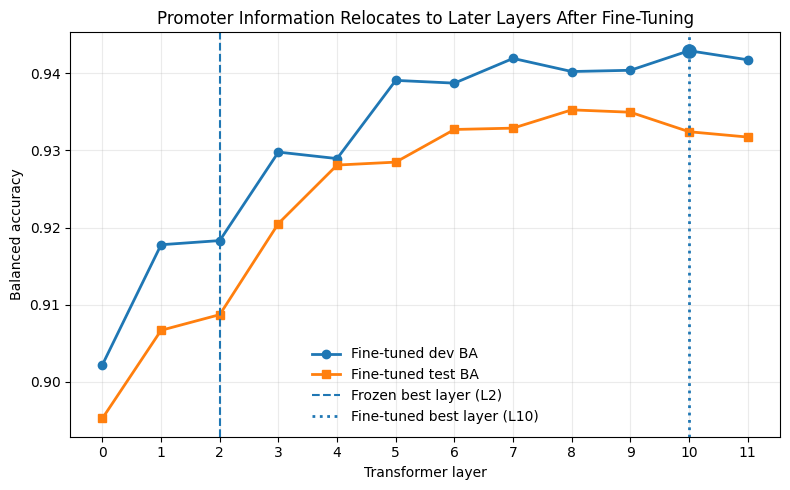


Saved:
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/hf_finetuned_layer_localization/figures/finetuned_layer_localization_ba.png
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/hf_finetuned_layer_localization/figures/finetuned_layer_localization_ba.pdf

Key values:
Fine-tuned L2 test BA: 0.908709
Fine-tuned L10 test BA: 0.932418

PASS: Stage 7 localization figure saved.


In [59]:
# Stage 7.15 — Fine-tuned layer-localization figure

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

INPUT_CSV = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/probes/layer_probe_metrics.csv"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_layer_localization/figures"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT_CSV)

layers = df["layer"].to_numpy()
dev_ba = df["dev_balanced_accuracy"].to_numpy()
test_ba = df["test_balanced_accuracy"].to_numpy()

FROZEN_BEST_LAYER = 2
FINETUNED_BEST_LAYER = 10

print("=" * 80)
print("CREATE LAYER-LOCALIZATION FIGURE")
print("=" * 80)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    layers,
    dev_ba,
    marker="o",
    linewidth=2,
    label="Fine-tuned dev BA",
)

ax.plot(
    layers,
    test_ba,
    marker="s",
    linewidth=2,
    label="Fine-tuned test BA",
)

ax.axvline(
    FROZEN_BEST_LAYER,
    linestyle="--",
    linewidth=1.5,
    label="Frozen best layer (L2)",
)

ax.axvline(
    FINETUNED_BEST_LAYER,
    linestyle=":",
    linewidth=2,
    label="Fine-tuned best layer (L10)",
)

ax.scatter(
    [FINETUNED_BEST_LAYER],
    [
        df.loc[
            df["layer"] == FINETUNED_BEST_LAYER,
            "dev_balanced_accuracy"
        ].iloc[0]
    ],
    s=90,
    zorder=5,
)

ax.set_xlabel("Transformer layer")
ax.set_ylabel("Balanced accuracy")

ax.set_title(
    "Promoter Information Relocates to Later Layers After Fine-Tuning"
)

ax.set_xticks(range(12))

ax.grid(
    True,
    alpha=0.25,
)

ax.legend(
    frameon=False,
)

fig.tight_layout()

png_path = OUTPUT_DIR / "finetuned_layer_localization_ba.png"
pdf_path = OUTPUT_DIR / "finetuned_layer_localization_ba.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
)

plt.show()

print("\nSaved:")
print(png_path)
print(pdf_path)

print("\nKey values:")

print(
    "Fine-tuned L2 test BA:",
    f"{df.loc[df['layer'] == 2, 'test_balanced_accuracy'].iloc[0]:.6f}"
)

print(
    "Fine-tuned L10 test BA:",
    f"{df.loc[df['layer'] == 10, 'test_balanced_accuracy'].iloc[0]:.6f}"
)

print(
    "\nPASS: Stage 7 localization figure saved."
)

In [60]:
# Stage 8.1 — Inspect Layer-0 module structure for targeted interventions

import torch

print("=" * 80)
print("LAYER-0 MODULE INSPECTION")
print("=" * 80)

layer0 = model_nf.bert.encoder.layer[0]

print("Layer 0 object:")
print(layer0)

print("\n" + "=" * 80)
print("DIRECT CHILD MODULES OF LAYER 0")
print("=" * 80)

for name, module in layer0.named_children():
    print(f"{name}: {module.__class__.__name__}")

print("\n" + "=" * 80)
print("NESTED MODULE NAMES INSIDE LAYER 0")
print("=" * 80)

for name, module in layer0.named_modules():
    if name == "":
        continue
    print(f"{name}: {module.__class__.__name__}")

print("\n" + "=" * 80)
print("PARAMETER SHAPES RELEVANT TO HEAD / MLP INTERVENTIONS")
print("=" * 80)

for name, param in layer0.named_parameters():
    print(f"{name:45s} {tuple(param.shape)}")

print("\n" + "=" * 80)
print("ARCHITECTURE FACTS")
print("=" * 80)

hidden_size = model_nf.config.hidden_size
num_heads = model_nf.config.num_attention_heads
head_dim = hidden_size // num_heads

print("Hidden size:", hidden_size)
print("Number of heads:", num_heads)
print("Per-head dimension:", head_dim)

assert hidden_size == 768
assert num_heads == 12
assert head_dim == 64

print("\nPASS: Layer-0 module structure inspected.")

LAYER-0 MODULE INSPECTION
Layer 0 object:
BertLayer(
  (attention): BertUnpadAttention(
    (self): BertUnpadSelfAttention(
      (dropout): Dropout(p=0.0, inplace=False)
      (Wqkv): Linear(in_features=768, out_features=2304, bias=True)
    )
    (output): BertSelfOutput(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (mlp): BertGatedLinearUnitMLP(
    (gated_layers): Linear(in_features=768, out_features=6144, bias=False)
    (act): GELU(approximate='none')
    (wo): Linear(in_features=3072, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
    (layernorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
  )
)

DIRECT CHILD MODULES OF LAYER 0
attention: BertUnpadAttention
mlp: BertGatedLinearUnitMLP

NESTED MODULE NAMES INSIDE LAYER 0
attention: BertUnpadAttention
attention.self: BertUnpadSelfAttention
a

In [61]:
# Stage 8.2 — Trace Layer-0 tensors at candidate causal intervention points.
#
# Goal:
#   1. Determine the exact tensor entering attention.output.dense.
#   2. Determine the exact output structure of attention.self.
#   3. Verify the Layer-0 MLP output shape.
#
# No intervention is performed in this step.

import torch

print("=" * 80)
print("LAYER-0 INTERVENTION-POINT TRACE")
print("=" * 80)

# Use a tiny canonical GUE test batch.
TRACE_N = 4

trace_sequences = (
    test_df["sequence"]
    .astype(str)
    .iloc[:TRACE_N]
    .tolist()
)

trace_labels = (
    test_df["label"]
    .iloc[:TRACE_N]
    .tolist()
)

trace_batch = tokenizer(
    trace_sequences,
    padding=True,
    truncation=True,
    max_length=256,
    return_tensors="pt",
)

trace_batch = {
    k: v.to(device)
    for k, v in trace_batch.items()
}

lengths = (
    trace_batch["attention_mask"]
    .sum(dim=1)
    .detach()
    .cpu()
    .tolist()
)

lengths = [int(x) for x in lengths]

print("Examples:", TRACE_N)
print("Labels:", trace_labels)
print("Non-pad token lengths:", lengths)
print("Total non-pad tokens:", sum(lengths))

layer0 = model_nf.bert.encoder.layer[0]

records = {}

# ------------------------------------------------------------------
# Generic shape formatter
# ------------------------------------------------------------------

def describe(obj):

    if torch.is_tensor(obj):
        return {
            "type": "Tensor",
            "shape": tuple(obj.shape),
            "dtype": str(obj.dtype),
            "device": str(obj.device),
            "finite": bool(torch.isfinite(obj).all()),
        }

    if isinstance(obj, tuple):
        return {
            "type": "tuple",
            "length": len(obj),
            "items": [
                describe(x)
                for x in obj
            ],
        }

    if isinstance(obj, list):
        return {
            "type": "list",
            "length": len(obj),
            "items": [
                describe(x)
                for x in obj
            ],
        }

    return {
        "type": type(obj).__name__,
        "repr": repr(obj)[:300],
    }


# ------------------------------------------------------------------
# Hooks
# ------------------------------------------------------------------

def attention_self_hook(module, inputs, output):
    records["attention.self.output"] = describe(output)


def dense_pre_hook(module, inputs):
    records["attention.output.dense.input"] = describe(inputs)


def dense_hook(module, inputs, output):
    records["attention.output.dense.output"] = describe(output)


def mlp_hook(module, inputs, output):
    records["mlp.output"] = describe(output)


handles = [
    layer0.attention.self.register_forward_hook(
        attention_self_hook
    ),

    layer0.attention.output.dense.register_forward_pre_hook(
        dense_pre_hook
    ),

    layer0.attention.output.dense.register_forward_hook(
        dense_hook
    ),

    layer0.mlp.register_forward_hook(
        mlp_hook
    ),
]

# ------------------------------------------------------------------
# Normal forward pass — no ablation
# ------------------------------------------------------------------

model_nf.eval()

try:
    with torch.inference_mode():
        baseline_outputs = model_nf(
            **trace_batch,
            return_dict=True,
        )
finally:
    for handle in handles:
        handle.remove()


# ------------------------------------------------------------------
# Print observed structures
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("OBSERVED INTERMEDIATE STRUCTURES")
print("=" * 80)

for name, info in records.items():

    print(f"\n{name}")

    print(info)


print("\n" + "=" * 80)
print("BASELINE OUTPUT")
print("=" * 80)

print(
    "Logits shape:",
    tuple(baseline_outputs.logits.shape)
)

print(
    "Logits finite:",
    bool(
        torch.isfinite(
            baseline_outputs.logits
        ).all()
    )
)

print(
    "Predictions:",
    baseline_outputs.logits.argmax(
        dim=-1
    ).detach().cpu().tolist()
)


# ------------------------------------------------------------------
# Critical expected intervention point
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("HEAD-ABLATION GEOMETRY CHECK")
print("=" * 80)

dense_input = records.get(
    "attention.output.dense.input"
)

print(
    "attention.output.dense input structure:",
    dense_input
)

print("\nCandidate Head-8 slice if final dimension is 768:")
print("start =", 8 * 64)
print("end   =", 9 * 64)
print("slice = [512:576]")

print(
    "\nPASS: Layer-0 intervention-point trace completed."
)

LAYER-0 INTERVENTION-POINT TRACE
Examples: 4
Labels: [1, 1, 0, 1]
Non-pad token lengths: [64, 67, 66, 67]
Total non-pad tokens: 264

OBSERVED INTERMEDIATE STRUCTURES

attention.self.output
{'type': 'Tensor', 'shape': (264, 768), 'dtype': 'torch.float32', 'device': 'cuda:0', 'finite': True}

attention.output.dense.input
{'type': 'tuple', 'length': 1, 'items': [{'type': 'Tensor', 'shape': (264, 768), 'dtype': 'torch.float32', 'device': 'cuda:0', 'finite': True}]}

attention.output.dense.output
{'type': 'Tensor', 'shape': (264, 768), 'dtype': 'torch.float32', 'device': 'cuda:0', 'finite': True}

mlp.output
{'type': 'Tensor', 'shape': (264, 768), 'dtype': 'torch.float32', 'device': 'cuda:0', 'finite': True}

BASELINE OUTPUT
Logits shape: (4, 2)
Logits finite: True
Predictions: [1, 1, 0, 1]

HEAD-ABLATION GEOMETRY CHECK
attention.output.dense input structure: {'type': 'tuple', 'length': 1, 'items': [{'type': 'Tensor', 'shape': (264, 768), 'dtype': 'torch.float32', 'device': 'cuda:0', 'finit

In [62]:
# Stage 8.3 — Inspect the exact Layer-0 forward implementations
# before designing the causal ablations.

import inspect

layer0 = model_nf.bert.encoder.layer[0]

print("=" * 80)
print("BERT LAYER FORWARD")
print("=" * 80)

print(
    inspect.getsource(
        layer0.forward
    )
)

print("\n" + "=" * 80)
print("ATTENTION FORWARD")
print("=" * 80)

print(
    inspect.getsource(
        layer0.attention.forward
    )
)

print("\n" + "=" * 80)
print("ATTENTION OUTPUT FORWARD")
print("=" * 80)

print(
    inspect.getsource(
        layer0.attention.output.forward
    )
)

print("\n" + "=" * 80)
print("MLP FORWARD")
print("=" * 80)

print(
    inspect.getsource(
        layer0.mlp.forward
    )
)

print("\n" + "=" * 80)
print("MLP OUTPUT PROJECTION")
print("=" * 80)

print("MLP wo:")
print(layer0.mlp.wo)

print(
    "\nPASS: forward implementations inspected."
)

BERT LAYER FORWARD
    def forward(
        self,
        hidden_states: torch.Tensor,
        cu_seqlens: torch.Tensor,
        seqlen: int,
        subset_idx: Optional[torch.Tensor] = None,
        indices: Optional[torch.Tensor] = None,
        attn_mask: Optional[torch.Tensor] = None,
        bias: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        """Forward pass for a BERT layer, including both attention and MLP.

        Args:
            hidden_states: (total_nnz, dim)
            cu_seqlens: (batch + 1,)
            seqlen: int
            subset_idx: () set of indices whose values we care about at the end of the layer
                        (e.g., the masked tokens, if this is the final layer).
            indices: None or (total_nnz,)
            attn_mask: None or (batch, max_seqlen_in_batch)
            bias: None or (batch, heads, max_seqlen_in_batch, max_seqlen_in_batch)
        """
        attention_output = self.attention(hidden_states, cu_seqlens, seqlen,

In [63]:
# Stage 8.4 — Targeted causal-ablation smoke test
# Conditions:
#   baseline
#   L0H8
#   L0_MLP
#   L0H8 + L0_MLP
#
# IMPORTANT:
# This is plumbing validation only, not the final dataset-level experiment.

import torch
import pandas as pd

SMOKE_N = 8
HEAD_INDEX = 8
HEAD_DIM = 64

HEAD_START = HEAD_INDEX * HEAD_DIM
HEAD_END = (HEAD_INDEX + 1) * HEAD_DIM

print("=" * 80)
print("TARGETED LAYER-0 ABLATION SMOKE TEST")
print("=" * 80)

print("Head:", HEAD_INDEX)
print("Head slice:", f"[{HEAD_START}:{HEAD_END}]")

assert HEAD_START == 512
assert HEAD_END == 576

smoke_df = test_df.iloc[:SMOKE_N].copy()

smoke_batch = tokenizer(
    smoke_df["sequence"].astype(str).tolist(),
    padding=True,
    truncation=True,
    max_length=256,
    return_tensors="pt",
)

smoke_batch = {
    key: value.to(device)
    for key, value in smoke_batch.items()
}

true_labels = (
    smoke_df["label"]
    .astype(int)
    .tolist()
)

layer0 = model_nf.bert.encoder.layer[0]

model_nf.eval()


# ------------------------------------------------------------------
# Helper: run one condition
# ------------------------------------------------------------------

def run_condition(
    ablate_head8=False,
    ablate_mlp=False,
):

    handles = []

    # --------------------------------------------------------------
    # L0H8:
    # zero Head-8's 64-dimensional contribution before W_O.
    # --------------------------------------------------------------

    if ablate_head8:

        def head8_pre_hook(module, inputs):

            assert len(inputs) == 1

            x = inputs[0]

            assert x.ndim == 2
            assert x.shape[-1] == 768

            x_new = x.clone()

            x_new[
                :,
                HEAD_START:HEAD_END
            ] = 0.0

            return (x_new,)

        handles.append(
            layer0.attention.output.dense.register_forward_pre_hook(
                head8_pre_hook
            )
        )

    # --------------------------------------------------------------
    # L0_MLP:
    # zero only the projected MLP branch BEFORE
    # residual addition + LayerNorm.
    #
    # mlp.forward:
    #
    #   hidden_states = self.wo(hidden_states)
    #   hidden_states = self.layernorm(
    #       hidden_states + residual_connection
    #   )
    #
    # Therefore zeroing wo output removes the MLP update
    # while preserving the attention residual stream.
    # --------------------------------------------------------------

    if ablate_mlp:

        def mlp_wo_hook(module, inputs, output):

            assert output.ndim == 2
            assert output.shape[-1] == 768

            return torch.zeros_like(output)

        handles.append(
            layer0.mlp.wo.register_forward_hook(
                mlp_wo_hook
            )
        )

    try:

        with torch.inference_mode():

            outputs = model_nf(
                **smoke_batch,
                return_dict=True,
            )

            logits = (
                outputs.logits
                .detach()
                .cpu()
            )

    finally:

        for handle in handles:
            handle.remove()

    probs = torch.softmax(
        logits,
        dim=-1,
    )

    promoter_prob = probs[:, 1]

    pred = logits.argmax(
        dim=-1
    )

    return {
        "logits": logits,
        "promoter_prob": promoter_prob,
        "pred": pred,
    }


# ------------------------------------------------------------------
# Run conditions
# ------------------------------------------------------------------

conditions = {
    "baseline": run_condition(
        ablate_head8=False,
        ablate_mlp=False,
    ),

    "L0H8": run_condition(
        ablate_head8=True,
        ablate_mlp=False,
    ),

    "L0_MLP": run_condition(
        ablate_head8=False,
        ablate_mlp=True,
    ),

    "L0H8_L0_MLP": run_condition(
        ablate_head8=True,
        ablate_mlp=True,
    ),
}


# ------------------------------------------------------------------
# Verify baseline is stable
# ------------------------------------------------------------------

baseline_repeat = run_condition(
    ablate_head8=False,
    ablate_mlp=False,
)

baseline_max_diff = (
    conditions["baseline"]["logits"]
    - baseline_repeat["logits"]
).abs().max().item()

print("\nBaseline repeat max-logit difference:")
print(f"{baseline_max_diff:.12f}")

assert baseline_max_diff < 1e-6


# ------------------------------------------------------------------
# Build per-example comparison
# ------------------------------------------------------------------

rows = []

baseline_prob = conditions[
    "baseline"
]["promoter_prob"]

for i in range(SMOKE_N):

    row = {
        "index": int(smoke_df.index[i]),
        "true_label": true_labels[i],

        "baseline_prob":
            float(baseline_prob[i]),

        "baseline_pred":
            int(
                conditions[
                    "baseline"
                ]["pred"][i]
            ),
    }

    for condition in [
        "L0H8",
        "L0_MLP",
        "L0H8_L0_MLP",
    ]:

        condition_prob = conditions[
            condition
        ]["promoter_prob"][i]

        row[
            f"{condition}_prob"
        ] = float(condition_prob)

        row[
            f"{condition}_delta_prob"
        ] = float(
            condition_prob
            - baseline_prob[i]
        )

        row[
            f"{condition}_pred"
        ] = int(
            conditions[
                condition
            ]["pred"][i]
        )

    rows.append(row)

comparison_df = pd.DataFrame(rows)


print("\n" + "=" * 80)
print("PER-EXAMPLE RESULTS")
print("=" * 80)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# ------------------------------------------------------------------
# Aggregate smoke-test effects
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("MEAN ABSOLUTE PROMOTER-PROBABILITY CHANGE")
print("=" * 80)

for condition in [
    "L0H8",
    "L0_MLP",
    "L0H8_L0_MLP",
]:

    delta = (
        conditions[condition]["promoter_prob"]
        - baseline_prob
    )

    print(
        f"{condition:12s}: "
        f"mean_delta={delta.mean().item():+.6f} "
        f"| mean_abs_delta={delta.abs().mean().item():.6f} "
        f"| max_abs_delta={delta.abs().max().item():.6f}"
    )


# ------------------------------------------------------------------
# Plumbing sanity checks
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("SANITY CHECK")
print("=" * 80)

for condition, result in conditions.items():

    assert result["logits"].shape == (SMOKE_N, 2)

    assert torch.isfinite(
        result["logits"]
    ).all()

    assert torch.isfinite(
        result["promoter_prob"]
    ).all()

print("All condition outputs finite: True")
print("All condition logits shape (8, 2): True")

print(
    "\nPASS: L0H8 and L0_MLP intervention "
    "plumbing works."
)

TARGETED LAYER-0 ABLATION SMOKE TEST
Head: 8
Head slice: [512:576]

Baseline repeat max-logit difference:
0.000000000000

PER-EXAMPLE RESULTS
 index  true_label  baseline_prob  baseline_pred  L0H8_prob  L0H8_delta_prob  L0H8_pred  L0_MLP_prob  L0_MLP_delta_prob  L0_MLP_pred  L0H8_L0_MLP_prob  L0H8_L0_MLP_delta_prob  L0H8_L0_MLP_pred
     0           1       0.962312              1   0.961126        -0.001186          1     0.942124          -0.020188            1          0.955224               -0.007088                 1
     1           1       0.997328              1   0.736752        -0.260577          1     0.989926          -0.007402            1          0.982387               -0.014941                 1
     2           0       0.091720              0   0.716128         0.624408          1     0.885888           0.794168            1          0.986574                0.894854                 1
     3           1       0.963909              1   0.952370        -0.011539          

In [67]:
# Stage 8.5 — Create and lock the fine-tuned causal localization cohort
# 128 promoters + 128 non-promoters
# Deterministic sampling from the canonical GUE test split.

from pathlib import Path
import pandas as pd
import numpy as np

SEED = 42
N_PER_CLASS = 128

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/cohorts"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = OUTPUT_DIR / "test_localization_256.csv"

print("=" * 80)
print("CREATE FINE-TUNED CAUSAL LOCALIZATION COHORT")
print("=" * 80)

if OUTPUT_PATH.exists():
    raise RuntimeError(
        f"Cohort already exists:\n{OUTPUT_PATH}\n"
        "Stopping to avoid silently changing the locked cohort."
    )

# Canonical test split, preserving original row indices.
working = test_df.copy()

working = working.reset_index().rename(
    columns={"index": "test_index"}
)

# Separate classes.
non_promoters = working[
    working["label"] == 0
].copy()

promoters = working[
    working["label"] == 1
].copy()

assert len(non_promoters) == 2940
assert len(promoters) == 2980

# Deterministic sampling.
sample_nonprom = non_promoters.sample(
    n=N_PER_CLASS,
    random_state=SEED,
    replace=False,
)

sample_prom = promoters.sample(
    n=N_PER_CLASS,
    random_state=SEED,
    replace=False,
)

# Combine and sort by original test index.
cohort = pd.concat(
    [
        sample_nonprom,
        sample_prom,
    ],
    ignore_index=True,
)

cohort = cohort.sort_values(
    "test_index"
).reset_index(drop=True)

print("Rows:", len(cohort))

print(
    "Label counts:",
    cohort["label"].value_counts().sort_index().to_dict()
)

print(
    "Unique test indices:",
    cohort["test_index"].nunique()
)

print(
    "Unique sequences:",
    cohort["sequence"].nunique()
)

assert len(cohort) == 256
assert cohort["test_index"].nunique() == 256

counts = cohort["label"].value_counts().to_dict()

assert counts[0] == 128
assert counts[1] == 128

# Save the locked cohort.
cohort.to_csv(
    OUTPUT_PATH,
    index=False,
)

print("\nFirst 10 rows:")
print(
    cohort[
        [
            "test_index",
            "label",
            "sequence",
        ]
    ].head(10).to_string(index=False)
)

print("\nSaved:")
print(OUTPUT_PATH)

print(
    "\nPASS: fine-tuned causal cohort locked "
    "(128 non-promoters + 128 promoters)."
)

CREATE FINE-TUNED CAUSAL LOCALIZATION COHORT
Rows: 256
Label counts: {0: 128, 1: 128}
Unique test indices: 256
Unique sequences: 256

First 10 rows:
 test_index  label                                                                                                                                                                                                                                                                                                     sequence
          0      1 CTAAATATTAACTGGTCTTGTGAGATGTCTTCTTGGCTGGAGCCTGACCACCTAACTTACTGTTTTTCCTCCAACTGCTGCCTCCTCCTTTCCCTCTGCTGCAGGCTGGAACTAAGGGCGGCGGGTGGCGGCGGGAGGAGGAAGGAGGAGAAGCAAAGTTGGCCAGGGTCCTGCTGGCTGGGGGCCAGGACTGCCTCCCTAAACAAGCAGGCGGGGGCACATATAGCCCTGGGTTGAGTTGTTGCCCTTACTCATCTGGCCACAGCAGGAAGAAGAGGCGCCCGGAAAACCTTAGCTCTT
         92      0 TGCTATCATCTTAGATAATGATTAACAGGCATTTAGAGAGAGTGTTAAAGTAAAAAAACTGTTTGGCAACACACAGGTTTAAAGGGCTAGCAAGAGAAAGAGGAGCCAGCAAAGGGGTCTGTCTGAGTGGTGGTCAGAGAATGGGTGGAGGACTTGGTCAACTCAGTGCTGCCTCTTAAGCCGAGGGAAAGG

In [68]:
# Stage 8.6 — Full targeted causal ablation on locked 256-example cohort

from pathlib import Path
import json
import shutil

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)

BATCH_SIZE = 64

COHORT_PATH = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/cohorts/test_localization_256.csv"
)

OUTPUT_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/targeted_ablation"
)

DRIVE_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/targeted_ablation"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("FULL TARGETED CAUSAL ABLATION")
print("=" * 80)

cohort = pd.read_csv(COHORT_PATH)

assert len(cohort) == 256
assert cohort["label"].value_counts().to_dict() == {
    0: 128,
    1: 128,
}

sequences = cohort["sequence"].astype(str).tolist()
labels = cohort["label"].astype(int).to_numpy()

layer0 = model_nf.bert.encoder.layer[0]

HEAD_INDEX = 8
HEAD_DIM = 64
HEAD_START = HEAD_INDEX * HEAD_DIM
HEAD_END = (HEAD_INDEX + 1) * HEAD_DIM

assert HEAD_START == 512
assert HEAD_END == 576

model_nf.eval()


def run_condition(
    name,
    ablate_head8=False,
    ablate_mlp=False,
):

    all_logits = []

    for start in range(0, len(cohort), BATCH_SIZE):

        end = min(
            start + BATCH_SIZE,
            len(cohort),
        )

        batch = tokenizer(
            sequences[start:end],
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt",
        )

        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        handles = []

        if ablate_head8:

            def head8_pre_hook(module, inputs):

                x = inputs[0]

                assert x.ndim == 2
                assert x.shape[-1] == 768

                x_new = x.clone()

                x_new[
                    :,
                    HEAD_START:HEAD_END
                ] = 0.0

                return (x_new,)

            handles.append(
                layer0.attention.output.dense.register_forward_pre_hook(
                    head8_pre_hook
                )
            )

        if ablate_mlp:

            def mlp_wo_hook(module, inputs, output):

                assert output.ndim == 2
                assert output.shape[-1] == 768

                return torch.zeros_like(output)

            handles.append(
                layer0.mlp.wo.register_forward_hook(
                    mlp_wo_hook
                )
            )

        try:

            with torch.inference_mode():

                outputs = model_nf(
                    **batch,
                    return_dict=True,
                )

                logits = (
                    outputs.logits
                    .detach()
                    .cpu()
                )

        finally:

            for handle in handles:
                handle.remove()

        all_logits.append(logits)

    logits = torch.cat(
        all_logits,
        dim=0,
    )

    assert logits.shape == (256, 2)
    assert torch.isfinite(logits).all()

    probs = torch.softmax(
        logits,
        dim=-1,
    ).numpy()

    promoter_prob = probs[:, 1]

    pred = logits.argmax(
        dim=-1
    ).numpy()

    cm = confusion_matrix(
        labels,
        pred,
        labels=[0, 1],
    )

    tn, fp, fn, tp = cm.ravel()

    metrics = {
        "condition": name,
        "accuracy": float(
            accuracy_score(
                labels,
                pred,
            )
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(
                labels,
                pred,
            )
        ),
        "mcc": float(
            matthews_corrcoef(
                labels,
                pred,
            )
        ),
        "roc_auc": float(
            roc_auc_score(
                labels,
                promoter_prob,
            )
        ),
        "pr_auc": float(
            average_precision_score(
                labels,
                promoter_prob,
            )
        ),
        "f1": float(
            f1_score(
                labels,
                pred,
            )
        ),
        "precision": float(
            precision_score(
                labels,
                pred,
                zero_division=0,
            )
        ),
        "recall": float(
            recall_score(
                labels,
                pred,
                zero_division=0,
            )
        ),
        "specificity": float(
            tn / (tn + fp)
        ),
    }

    return {
        "logits": logits.numpy(),
        "probabilities": probs,
        "promoter_probability": promoter_prob,
        "predictions": pred,
        "confusion_matrix": cm,
        "metrics": metrics,
    }


conditions = {
    "baseline": run_condition(
        "baseline",
        False,
        False,
    ),

    "L0H8": run_condition(
        "L0H8",
        True,
        False,
    ),

    "L0_MLP": run_condition(
        "L0_MLP",
        False,
        True,
    ),

    "L0H8_L0_MLP": run_condition(
        "L0H8_L0_MLP",
        True,
        True,
    ),
}


print("\n" + "=" * 80)
print("METRICS")
print("=" * 80)

metrics_df = pd.DataFrame(
    [
        conditions[name]["metrics"]
        for name in conditions
    ]
)

print(
    metrics_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# --------------------------------------------------------------
# Effect sizes relative to baseline
# --------------------------------------------------------------

baseline_prob = conditions[
    "baseline"
]["promoter_probability"]

effect_rows = []

for name in [
    "L0H8",
    "L0_MLP",
    "L0H8_L0_MLP",
]:

    condition_prob = conditions[
        name
    ]["promoter_probability"]

    delta = (
        condition_prob
        - baseline_prob
    )

    effect_rows.append(
        {
            "condition": name,

            "mean_delta_promoter_prob":
                float(delta.mean()),

            "mean_abs_delta_promoter_prob":
                float(np.abs(delta).mean()),

            "median_abs_delta_promoter_prob":
                float(np.median(np.abs(delta))),

            "max_abs_delta_promoter_prob":
                float(np.abs(delta).max()),

            "prediction_flip_fraction":
                float(
                    np.mean(
                        conditions[name]["predictions"]
                        != conditions["baseline"]["predictions"]
                    )
                ),

            "delta_balanced_accuracy":
                float(
                    conditions[name]["metrics"][
                        "balanced_accuracy"
                    ]
                    - conditions["baseline"]["metrics"][
                        "balanced_accuracy"
                    ]
                ),

            "delta_mcc":
                float(
                    conditions[name]["metrics"]["mcc"]
                    - conditions["baseline"]["metrics"]["mcc"]
                ),

            "delta_roc_auc":
                float(
                    conditions[name]["metrics"]["roc_auc"]
                    - conditions["baseline"]["metrics"]["roc_auc"]
                ),
        }
    )

effects_df = pd.DataFrame(effect_rows)

print("\n" + "=" * 80)
print("EFFECTS RELATIVE TO BASELINE")
print("=" * 80)

print(
    effects_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# --------------------------------------------------------------
# Per-example artifact
# --------------------------------------------------------------

per_example = cohort[
    [
        "test_index",
        "label",
        "sequence",
    ]
].copy()

for name, result in conditions.items():

    per_example[
        f"{name}_pred"
    ] = result["predictions"]

    per_example[
        f"{name}_promoter_probability"
    ] = result[
        "promoter_probability"
    ]

    per_example[
        f"{name}_logit_0"
    ] = result["logits"][:, 0]

    per_example[
        f"{name}_logit_1"
    ] = result["logits"][:, 1]

    if name != "baseline":

        per_example[
            f"{name}_delta_promoter_probability"
        ] = (
            result["promoter_probability"]
            - baseline_prob
        )


# --------------------------------------------------------------
# Save
# --------------------------------------------------------------

metrics_path = OUTPUT_DIR / "metrics.csv"
effects_path = OUTPUT_DIR / "effects_vs_baseline.csv"
per_example_path = OUTPUT_DIR / "per_example.csv"

metrics_df.to_csv(
    metrics_path,
    index=False,
)

effects_df.to_csv(
    effects_path,
    index=False,
)

per_example.to_csv(
    per_example_path,
    index=False,
)

metadata = {
    "n_examples": 256,
    "class_balance": {
        "non_promoter": 128,
        "promoter": 128,
    },
    "cohort_file": str(COHORT_PATH),
    "batch_size": BATCH_SIZE,
    "conditions": [
        "baseline",
        "L0H8",
        "L0_MLP",
        "L0H8_L0_MLP",
    ],
    "L0H8_intervention": {
        "location":
            "layer0.attention.output.dense input",
        "head": 8,
        "slice": [512, 576],
        "operation": "zero",
    },
    "L0_MLP_intervention": {
        "location": "layer0.mlp.wo output",
        "operation": "zero",
        "note":
            "removes MLP branch before residual addition and LayerNorm",
    },
}

metadata_path = OUTPUT_DIR / "metadata.json"

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
    )
)

for path in [
    metrics_path,
    effects_path,
    per_example_path,
    metadata_path,
]:

    shutil.copy2(
        path,
        DRIVE_OUTPUT_DIR / path.name,
    )

print("\n" + "=" * 80)
print("SAVED")
print("=" * 80)

print(DRIVE_OUTPUT_DIR)

print(
    "\nPASS: full 256-example targeted "
    "causal ablation completed."
)

FULL TARGETED CAUSAL ABLATION

METRICS
  condition  accuracy  balanced_accuracy      mcc  roc_auc   pr_auc       f1  precision   recall  specificity
   baseline  0.957031           0.957031 0.914090 0.991272 0.991231 0.957198   0.953488 0.960938     0.953125
       L0H8  0.511719           0.511719 0.108893 0.685669 0.676078 0.671916   0.505929 1.000000     0.023438
     L0_MLP  0.816406           0.816406 0.671858 0.900757 0.882187 0.842809   0.736842 0.984375     0.648438
L0H8_L0_MLP  0.503906           0.503906 0.036298 0.665222 0.687403 0.666667   0.501976 0.992188     0.015625

EFFECTS RELATIVE TO BASELINE
  condition  mean_delta_promoter_prob  mean_abs_delta_promoter_prob  median_abs_delta_promoter_prob  max_abs_delta_promoter_prob  prediction_flip_fraction  delta_balanced_accuracy  delta_mcc  delta_roc_auc
       L0H8                  0.411526                      0.450557                        0.303268                     0.989938                  0.484375                -0.44

In [69]:
# Stage 8.7 — Quantify class-conditional causal effects
# using the already-saved 256-example ablation results.
#
# No new model inference is performed.

from pathlib import Path
import pandas as pd
import numpy as np
import json
import shutil

INPUT_PATH = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/targeted_ablation/per_example.csv"
)

OUTPUT_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/targeted_ablation"
)

DRIVE_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/targeted_ablation"
)

df = pd.read_csv(INPUT_PATH)

print("=" * 80)
print("CLASS-CONDITIONAL ABLATION EFFECTS")
print("=" * 80)

assert len(df) == 256
assert (df["label"] == 0).sum() == 128
assert (df["label"] == 1).sum() == 128

conditions = [
    "L0H8",
    "L0_MLP",
    "L0H8_L0_MLP",
]

rows = []

for condition in conditions:

    delta_col = (
        f"{condition}_delta_promoter_probability"
    )

    pred_col = f"{condition}_pred"

    for label in [0, 1]:

        subset = df[
            df["label"] == label
        ].copy()

        delta = subset[
            delta_col
        ].to_numpy()

        baseline_pred = subset[
            "baseline_pred"
        ].to_numpy()

        condition_pred = subset[
            pred_col
        ].to_numpy()

        row = {
            "condition": condition,
            "true_label": label,
            "class_name":
                "non_promoter"
                if label == 0
                else "promoter",

            "n": len(subset),

            "mean_delta_promoter_probability":
                float(delta.mean()),

            "median_delta_promoter_probability":
                float(np.median(delta)),

            "mean_abs_delta":
                float(np.abs(delta).mean()),

            "fraction_delta_positive":
                float(np.mean(delta > 0)),

            "fraction_delta_negative":
                float(np.mean(delta < 0)),

            "prediction_flip_fraction":
                float(
                    np.mean(
                        baseline_pred
                        != condition_pred
                    )
                ),

            "fraction_predicted_promoter_after_ablation":
                float(
                    np.mean(
                        condition_pred == 1
                    )
                ),
        }

        rows.append(row)

summary_df = pd.DataFrame(rows)

print(
    summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print("\n" + "=" * 80)
print("DIRECTIONAL SUMMARY")
print("=" * 80)

for condition in conditions:

    nonprom = summary_df[
        (summary_df["condition"] == condition)
        &
        (summary_df["true_label"] == 0)
    ].iloc[0]

    prom = summary_df[
        (summary_df["condition"] == condition)
        &
        (summary_df["true_label"] == 1)
    ].iloc[0]

    print(f"\n{condition}")

    print(
        "  Non-promoters:"
        f" mean ΔP(promoter)="
        f"{nonprom['mean_delta_promoter_probability']:+.6f}"
        f" | predicted promoter after ablation="
        f"{nonprom['fraction_predicted_promoter_after_ablation']:.3f}"
    )

    print(
        "  Promoters:    "
        f" mean ΔP(promoter)="
        f"{prom['mean_delta_promoter_probability']:+.6f}"
        f" | predicted promoter after ablation="
        f"{prom['fraction_predicted_promoter_after_ablation']:.3f}"
    )


# Save
local_path = (
    OUTPUT_DIR
    / "class_conditional_effects.csv"
)

drive_path = (
    DRIVE_OUTPUT_DIR
    / "class_conditional_effects.csv"
)

summary_df.to_csv(
    local_path,
    index=False,
)

shutil.copy2(
    local_path,
    drive_path,
)

print("\nSaved:")
print(drive_path)

print(
    "\nPASS: class-conditional ablation effects quantified."
)

CLASS-CONDITIONAL ABLATION EFFECTS
  condition  true_label   class_name   n  mean_delta_promoter_probability  median_delta_promoter_probability  mean_abs_delta  fraction_delta_positive  fraction_delta_negative  prediction_flip_fraction  fraction_predicted_promoter_after_ablation
       L0H8           0 non_promoter 128                         0.819336                           0.900961        0.819481                 0.992188                 0.007812                  0.929688                                    0.976562
       L0H8           1     promoter 128                         0.003715                          -0.023256        0.081634                 0.250000                 0.750000                  0.039062                                    1.000000
     L0_MLP           0 non_promoter 128                         0.346258                           0.177013        0.355632                 0.968750                 0.031250                  0.320312                              

In [70]:
# Stage 9.1 — Activation-restoration smoke test
#
# Conditions:
#   baseline
#   combined ablation: L0H8 + L0_MLP
#   combined ablation + restore L0H8
#   combined ablation + restore L0_MLP
#   combined ablation + restore BOTH
#
# Uses only 8 examples.
# No final scientific inference yet.

import torch
import pandas as pd
import numpy as np

SMOKE_N = 8

HEAD_INDEX = 8
HEAD_DIM = 64
HEAD_START = HEAD_INDEX * HEAD_DIM
HEAD_END = (HEAD_INDEX + 1) * HEAD_DIM

assert HEAD_START == 512
assert HEAD_END == 576

print("=" * 80)
print("ACTIVATION RESTORATION SMOKE TEST")
print("=" * 80)

smoke_df = cohort.iloc[:SMOKE_N].copy()

sequences = smoke_df["sequence"].astype(str).tolist()
labels = smoke_df["label"].astype(int).to_numpy()

batch = tokenizer(
    sequences,
    padding=True,
    truncation=True,
    max_length=256,
    return_tensors="pt",
)

batch = {
    k: v.to(device)
    for k, v in batch.items()
}

layer0 = model_nf.bert.encoder.layer[0]

model_nf.eval()


# ==================================================================
# 1. BASELINE PASS + CACHE CLEAN ACTIVATIONS
# ==================================================================

cache = {}

def cache_head8_pre_hook(module, inputs):

    x = inputs[0]

    assert x.ndim == 2
    assert x.shape[-1] == 768

    cache["head8"] = (
        x[:, HEAD_START:HEAD_END]
        .detach()
        .clone()
    )


def cache_mlp_hook(module, inputs, output):

    assert output.ndim == 2
    assert output.shape[-1] == 768

    cache["mlp_wo"] = (
        output
        .detach()
        .clone()
    )


handles = [
    layer0.attention.output.dense.register_forward_pre_hook(
        cache_head8_pre_hook
    ),

    layer0.mlp.wo.register_forward_hook(
        cache_mlp_hook
    ),
]

try:

    with torch.inference_mode():

        baseline_outputs = model_nf(
            **batch,
            return_dict=True,
        )

        baseline_logits = (
            baseline_outputs.logits
            .detach()
            .cpu()
        )

finally:

    for handle in handles:
        handle.remove()


assert "head8" in cache
assert "mlp_wo" in cache

print("Cached Head-8 shape:", tuple(cache["head8"].shape))
print("Cached MLP wo shape:", tuple(cache["mlp_wo"].shape))


# ==================================================================
# Helper for ablation/restoration conditions
# ==================================================================

def run_restoration_condition(
    restore_head8=False,
    restore_mlp=False,
):

    handles = []

    # --------------------------------------------------------------
    # Head-8 intervention:
    #
    # Default = zero L0H8
    # If restore_head8=True, replace with cached clean activation.
    # --------------------------------------------------------------

    def head8_intervention(module, inputs):

        x = inputs[0]

        assert x.ndim == 2
        assert x.shape[-1] == 768

        x_new = x.clone()

        # Ablate first
        x_new[
            :,
            HEAD_START:HEAD_END
        ] = 0.0

        # Restore clean Head-8 if requested
        if restore_head8:

            assert (
                x_new.shape[0]
                == cache["head8"].shape[0]
            )

            x_new[
                :,
                HEAD_START:HEAD_END
            ] = cache["head8"]

        return (x_new,)

    handles.append(
        layer0.attention.output.dense.register_forward_pre_hook(
            head8_intervention
        )
    )

    # --------------------------------------------------------------
    # MLP intervention:
    #
    # Default = zero projected MLP branch.
    # If restore_mlp=True, replace with cached clean MLP projection.
    # --------------------------------------------------------------

    def mlp_intervention(module, inputs, output):

        assert output.ndim == 2
        assert output.shape[-1] == 768

        if restore_mlp:

            assert (
                output.shape
                == cache["mlp_wo"].shape
            )

            return cache["mlp_wo"].clone()

        return torch.zeros_like(output)

    handles.append(
        layer0.mlp.wo.register_forward_hook(
            mlp_intervention
        )
    )

    try:

        with torch.inference_mode():

            outputs = model_nf(
                **batch,
                return_dict=True,
            )

            logits = (
                outputs.logits
                .detach()
                .cpu()
            )

    finally:

        for handle in handles:
            handle.remove()

    assert logits.shape == (SMOKE_N, 2)
    assert torch.isfinite(logits).all()

    probs = torch.softmax(
        logits,
        dim=-1,
    )[:, 1]

    preds = logits.argmax(
        dim=-1
    )

    return {
        "logits": logits,
        "promoter_prob": probs,
        "pred": preds,
    }


# ==================================================================
# Run restoration conditions
# ==================================================================

results = {}

results["baseline"] = {
    "logits": baseline_logits,
    "promoter_prob": torch.softmax(
        baseline_logits,
        dim=-1,
    )[:, 1],
    "pred": baseline_logits.argmax(
        dim=-1
    ),
}

results["ablated"] = run_restoration_condition(
    restore_head8=False,
    restore_mlp=False,
)

results["restore_L0H8"] = run_restoration_condition(
    restore_head8=True,
    restore_mlp=False,
)

results["restore_L0_MLP"] = run_restoration_condition(
    restore_head8=False,
    restore_mlp=True,
)

results["restore_both"] = run_restoration_condition(
    restore_head8=True,
    restore_mlp=True,
)


# ==================================================================
# Compare against baseline
# ==================================================================

baseline_prob = results[
    "baseline"
]["promoter_prob"]

rows = []

for name in [
    "ablated",
    "restore_L0H8",
    "restore_L0_MLP",
    "restore_both",
]:

    prob = results[name][
        "promoter_prob"
    ]

    delta = (
        prob
        - baseline_prob
    )

    logit_diff = (
        results[name]["logits"]
        - results["baseline"]["logits"]
    )

    rows.append(
        {
            "condition": name,

            "mean_abs_prob_diff_from_baseline":
                float(
                    delta.abs().mean()
                ),

            "max_abs_prob_diff_from_baseline":
                float(
                    delta.abs().max()
                ),

            "mean_abs_logit_diff_from_baseline":
                float(
                    logit_diff.abs().mean()
                ),

            "max_abs_logit_diff_from_baseline":
                float(
                    logit_diff.abs().max()
                ),

            "prediction_match_fraction":
                float(
                    (
                        results[name]["pred"]
                        == results["baseline"]["pred"]
                    )
                    .float()
                    .mean()
                ),
        }
    )

summary_df = pd.DataFrame(rows)

print("\n" + "=" * 80)
print("RESTORATION SUMMARY")
print("=" * 80)

print(
    summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}",
    )
)


# ==================================================================
# Per-example probability table
# ==================================================================

per_example = pd.DataFrame(
    {
        "test_index":
            smoke_df["test_index"].to_numpy(),

        "label":
            labels,

        "baseline_prob":
            results[
                "baseline"
            ]["promoter_prob"].numpy(),

        "ablated_prob":
            results[
                "ablated"
            ]["promoter_prob"].numpy(),

        "restore_L0H8_prob":
            results[
                "restore_L0H8"
            ]["promoter_prob"].numpy(),

        "restore_L0_MLP_prob":
            results[
                "restore_L0_MLP"
            ]["promoter_prob"].numpy(),

        "restore_both_prob":
            results[
                "restore_both"
            ]["promoter_prob"].numpy(),
    }
)

print("\n" + "=" * 80)
print("PER-EXAMPLE PROMOTER PROBABILITIES")
print("=" * 80)

print(
    per_example.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# ==================================================================
# Critical restoration sanity check
# ==================================================================

both_max_logit_diff = (
    results["restore_both"]["logits"]
    - results["baseline"]["logits"]
).abs().max().item()

print("\n" + "=" * 80)
print("RESTORE-BOTH SANITY CHECK")
print("=" * 80)

print(
    "Max logit difference, baseline vs restore-both:",
    f"{both_max_logit_diff:.12f}"
)

print(
    "\nPASS: activation-restoration smoke test completed."
)

ACTIVATION RESTORATION SMOKE TEST
Cached Head-8 shape: (535, 64)
Cached MLP wo shape: (535, 768)

RESTORATION SUMMARY
     condition  mean_abs_prob_diff_from_baseline  max_abs_prob_diff_from_baseline  mean_abs_logit_diff_from_baseline  max_abs_logit_diff_from_baseline  prediction_match_fraction
       ablated                        0.07328853                       0.34500593                         0.65196204                        1.45214713                 1.00000000
  restore_L0H8                        0.05380431                       0.20599550                         0.61370230                        1.44852161                 1.00000000
restore_L0_MLP                        0.12500224                       0.35604674                         0.89027065                        1.87378693                 1.00000000
  restore_both                        0.00000000                       0.00000000                         0.00000000                        0.00000000                 1.0

In [71]:
# Stage 9.2 — Full activation-restoration experiment
# Locked 256-example causal cohort
#
# Conditions:
#   baseline
#   combined ablation
#   combined ablation + restore L0H8
#   combined ablation + restore L0_MLP
#   combined ablation + restore both

from pathlib import Path
import json
import shutil

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
)

BATCH_SIZE = 64

OUTPUT_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/activation_restoration"
)

DRIVE_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/activation_restoration"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("FULL ACTIVATION RESTORATION")
print("=" * 80)

assert len(cohort) == 256

sequences = cohort["sequence"].astype(str).tolist()
labels = cohort["label"].astype(int).to_numpy()

layer0 = model_nf.bert.encoder.layer[0]

HEAD_START = 512
HEAD_END = 576

model_nf.eval()


# ------------------------------------------------------------------
# Process one batch.
# ------------------------------------------------------------------

def run_batch(batch_sequences):

    batch = tokenizer(
        batch_sequences,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt",
    )

    batch = {
        k: v.to(device)
        for k, v in batch.items()
    }

    # ==============================================================
    # Clean pass + cache activations
    # ==============================================================

    cache = {}

    def cache_head_hook(module, inputs):

        x = inputs[0]

        cache["head8"] = (
            x[:, HEAD_START:HEAD_END]
            .detach()
            .clone()
        )

    def cache_mlp_hook(module, inputs, output):

        cache["mlp"] = (
            output
            .detach()
            .clone()
        )

    handles = [
        layer0.attention.output.dense.register_forward_pre_hook(
            cache_head_hook
        ),

        layer0.mlp.wo.register_forward_hook(
            cache_mlp_hook
        ),
    ]

    try:

        with torch.inference_mode():

            baseline = model_nf(
                **batch,
                return_dict=True,
            ).logits.detach().cpu()

    finally:

        for h in handles:
            h.remove()

    # ==============================================================
    # Intervention helper
    # ==============================================================

    def intervention_forward(
        restore_head=False,
        restore_mlp=False,
    ):

        handles = []

        def head_hook(module, inputs):

            x = inputs[0]
            x_new = x.clone()

            x_new[
                :,
                HEAD_START:HEAD_END
            ] = 0.0

            if restore_head:

                x_new[
                    :,
                    HEAD_START:HEAD_END
                ] = cache["head8"]

            return (x_new,)

        handles.append(
            layer0.attention.output.dense.register_forward_pre_hook(
                head_hook
            )
        )

        def mlp_hook(module, inputs, output):

            if restore_mlp:
                return cache["mlp"].clone()

            return torch.zeros_like(output)

        handles.append(
            layer0.mlp.wo.register_forward_hook(
                mlp_hook
            )
        )

        try:

            with torch.inference_mode():

                logits = model_nf(
                    **batch,
                    return_dict=True,
                ).logits.detach().cpu()

        finally:

            for h in handles:
                h.remove()

        return logits

    return {
        "baseline": baseline,

        "ablated":
            intervention_forward(
                False,
                False,
            ),

        "restore_L0H8":
            intervention_forward(
                True,
                False,
            ),

        "restore_L0_MLP":
            intervention_forward(
                False,
                True,
            ),

        "restore_both":
            intervention_forward(
                True,
                True,
            ),
    }


# ------------------------------------------------------------------
# Run full cohort
# ------------------------------------------------------------------

condition_logits = {
    name: []
    for name in [
        "baseline",
        "ablated",
        "restore_L0H8",
        "restore_L0_MLP",
        "restore_both",
    ]
}

for start in range(
    0,
    len(cohort),
    BATCH_SIZE,
):

    end = min(
        start + BATCH_SIZE,
        len(cohort),
    )

    batch_results = run_batch(
        sequences[start:end]
    )

    for name in condition_logits:

        condition_logits[name].append(
            batch_results[name]
        )

    print(
        f"Processed {end:3d}/256"
    )


for name in condition_logits:

    condition_logits[name] = torch.cat(
        condition_logits[name],
        dim=0,
    )

    assert condition_logits[name].shape == (
        256,
        2,
    )


# ------------------------------------------------------------------
# Exact restore-both check
# ------------------------------------------------------------------

restore_both_max_diff = (
    condition_logits["restore_both"]
    - condition_logits["baseline"]
).abs().max().item()

print("\nRestore-both max logit difference:")
print(f"{restore_both_max_diff:.12f}")

assert restore_both_max_diff < 1e-6


# ------------------------------------------------------------------
# Metrics
# ------------------------------------------------------------------

rows = []
results = {}

for name, logits in condition_logits.items():

    probs = torch.softmax(
        logits,
        dim=-1,
    ).numpy()

    promoter_prob = probs[:, 1]

    pred = logits.argmax(
        dim=-1
    ).numpy()

    metrics = {
        "condition": name,

        "accuracy":
            float(
                accuracy_score(
                    labels,
                    pred,
                )
            ),

        "balanced_accuracy":
            float(
                balanced_accuracy_score(
                    labels,
                    pred,
                )
            ),

        "mcc":
            float(
                matthews_corrcoef(
                    labels,
                    pred,
                )
            ),

        "roc_auc":
            float(
                roc_auc_score(
                    labels,
                    promoter_prob,
                )
            ),

        "pr_auc":
            float(
                average_precision_score(
                    labels,
                    promoter_prob,
                )
            ),

        "f1":
            float(
                f1_score(
                    labels,
                    pred,
                )
            ),

        "precision":
            float(
                precision_score(
                    labels,
                    pred,
                    zero_division=0,
                )
            ),

        "recall":
            float(
                recall_score(
                    labels,
                    pred,
                    zero_division=0,
                )
            ),
    }

    rows.append(metrics)

    results[name] = {
        "logits": logits.numpy(),
        "promoter_prob": promoter_prob,
        "pred": pred,
    }

metrics_df = pd.DataFrame(rows)

print("\n" + "=" * 80)
print("RESTORATION METRICS")
print("=" * 80)

print(
    metrics_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# ------------------------------------------------------------------
# Recovery relative to ablation
# ------------------------------------------------------------------

baseline_prob = results[
    "baseline"
]["promoter_prob"]

ablated_prob = results[
    "ablated"
]["promoter_prob"]

ablation_error = np.abs(
    ablated_prob
    - baseline_prob
)

recovery_rows = []

for name in [
    "restore_L0H8",
    "restore_L0_MLP",
    "restore_both",
]:

    restored_prob = results[
        name
    ]["promoter_prob"]

    restored_error = np.abs(
        restored_prob
        - baseline_prob
    )

    # Fraction of the ablation-induced probability error removed.
    denominator = ablation_error.mean()

    recovery_fraction = (
        1.0
        - restored_error.mean()
        / denominator
    )

    recovery_rows.append(
        {
            "condition": name,

            "mean_abs_prob_error_vs_baseline":
                float(
                    restored_error.mean()
                ),

            "recovery_fraction":
                float(
                    recovery_fraction
                ),

            "prediction_match_baseline":
                float(
                    np.mean(
                        results[name]["pred"]
                        == results["baseline"]["pred"]
                    )
                ),

            "delta_BA_vs_ablated":
                float(
                    metrics_df.loc[
                        metrics_df["condition"] == name,
                        "balanced_accuracy",
                    ].iloc[0]
                    -
                    metrics_df.loc[
                        metrics_df["condition"] == "ablated",
                        "balanced_accuracy",
                    ].iloc[0]
                ),
        }
    )

recovery_df = pd.DataFrame(
    recovery_rows
)

print("\n" + "=" * 80)
print("RESTORATION RECOVERY")
print("=" * 80)

print(
    recovery_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# ------------------------------------------------------------------
# Per-example results
# ------------------------------------------------------------------

per_example = cohort[
    [
        "test_index",
        "label",
        "sequence",
    ]
].copy()

for name in results:

    per_example[
        f"{name}_pred"
    ] = results[name]["pred"]

    per_example[
        f"{name}_promoter_probability"
    ] = results[name]["promoter_prob"]


# ------------------------------------------------------------------
# Save artifacts
# ------------------------------------------------------------------

metrics_path = (
    OUTPUT_DIR
    / "metrics.csv"
)

recovery_path = (
    OUTPUT_DIR
    / "recovery.csv"
)

per_example_path = (
    OUTPUT_DIR
    / "per_example.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False,
)

recovery_df.to_csv(
    recovery_path,
    index=False,
)

per_example.to_csv(
    per_example_path,
    index=False,
)

metadata = {
    "n_examples": 256,
    "cohort":
        "test_localization_256.csv",

    "conditions": [
        "baseline",
        "ablated",
        "restore_L0H8",
        "restore_L0_MLP",
        "restore_both",
    ],

    "ablation":
        "L0H8 + L0_MLP",

    "head8_slice":
        [512, 576],

    "restoration_source":
        "same-example clean forward activations",

    "restore_both_max_logit_diff":
        restore_both_max_diff,
}

metadata_path = (
    OUTPUT_DIR
    / "metadata.json"
)

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
    )
)

for path in [
    metrics_path,
    recovery_path,
    per_example_path,
    metadata_path,
]:

    shutil.copy2(
        path,
        DRIVE_OUTPUT_DIR / path.name,
    )

print("\nSaved:")
print(DRIVE_OUTPUT_DIR)

print(
    "\nPASS: full activation-restoration "
    "experiment completed."
)

FULL ACTIVATION RESTORATION
Processed  64/256
Processed 128/256
Processed 192/256
Processed 256/256

Restore-both max logit difference:
0.000000000000

RESTORATION METRICS
     condition  accuracy  balanced_accuracy      mcc  roc_auc   pr_auc       f1  precision   recall
      baseline  0.957031           0.957031 0.914090 0.991272 0.991231 0.957198   0.953488 0.960938
       ablated  0.503906           0.503906 0.036298 0.665222 0.687403 0.666667   0.501976 0.992188
  restore_L0H8  0.816406           0.816406 0.671858 0.900757 0.882187 0.842809   0.736842 0.984375
restore_L0_MLP  0.925781           0.925781 0.853675 0.979858 0.979772 0.928302   0.897810 0.960938
  restore_both  0.957031           0.957031 0.914090 0.991272 0.991231 0.957198   0.953488 0.960938

RESTORATION RECOVERY
     condition  mean_abs_prob_error_vs_baseline  recovery_fraction  prediction_match_baseline  delta_BA_vs_ablated
  restore_L0H8                         0.207994           0.552953                   0.8203

In [72]:
# Stage 10.1 — Construct deterministic donor/recipient mappings
# for the 256-example fine-tuned causal cohort.
#
# Same-class offsets:     1, 3, 5, 7
# Opposite-class offsets: 0, 3, 5, 7
#
# No model inference in this step.

from pathlib import Path
import json
import pandas as pd
import numpy as np
import shutil

print("=" * 80)
print("CONSTRUCT COMPONENT DONOR MATRIX PAIRINGS")
print("=" * 80)

SAME_CLASS_OFFSETS = [1, 3, 5, 7]
OPPOSITE_CLASS_OFFSETS = [0, 3, 5, 7]

OUTPUT_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/component_donor_matrix"
)

DRIVE_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/component_donor_matrix"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert len(cohort) == 256
assert (cohort["label"] == 0).sum() == 128
assert (cohort["label"] == 1).sum() == 128

# ------------------------------------------------------------------
# Work in locked cohort row coordinates 0...255.
# ------------------------------------------------------------------

working = cohort.reset_index(drop=True).copy()
working["cohort_row"] = np.arange(len(working))

class_rows = {
    label: working.loc[
        working["label"] == label,
        "cohort_row"
    ].to_numpy()
    for label in [0, 1]
}

print("Class 0 rows:", len(class_rows[0]))
print("Class 1 rows:", len(class_rows[1]))

assert len(class_rows[0]) == 128
assert len(class_rows[1]) == 128


# ------------------------------------------------------------------
# Build mappings.
#
# SAME CLASS:
# recipient at position k gets donor from position (k + offset) mod 128
#
# OPPOSITE CLASS:
# recipient at class-position k gets donor from opposite class
# at position (k + offset) mod 128
# ------------------------------------------------------------------

pair_rows = []

for recipient_label in [0, 1]:

    recipients = class_rows[recipient_label]

    # ==============================================================
    # Same-class donors
    # ==============================================================

    for offset in SAME_CLASS_OFFSETS:

        donors = np.roll(
            recipients,
            -offset,
        )

        for recipient_row, donor_row in zip(
            recipients,
            donors,
        ):

            pair_rows.append(
                {
                    "pair_type": "same_class",
                    "offset": offset,

                    "recipient_cohort_row":
                        int(recipient_row),

                    "donor_cohort_row":
                        int(donor_row),

                    "recipient_label":
                        int(
                            working.loc[
                                recipient_row,
                                "label"
                            ]
                        ),

                    "donor_label":
                        int(
                            working.loc[
                                donor_row,
                                "label"
                            ]
                        ),

                    "recipient_test_index":
                        int(
                            working.loc[
                                recipient_row,
                                "test_index"
                            ]
                        ),

                    "donor_test_index":
                        int(
                            working.loc[
                                donor_row,
                                "test_index"
                            ]
                        ),
                }
            )

    # ==============================================================
    # Opposite-class donors
    # ==============================================================

    donors_base = class_rows[
        1 - recipient_label
    ]

    for offset in OPPOSITE_CLASS_OFFSETS:

        donors = np.roll(
            donors_base,
            -offset,
        )

        for recipient_row, donor_row in zip(
            recipients,
            donors,
        ):

            pair_rows.append(
                {
                    "pair_type": "opposite_class",
                    "offset": offset,

                    "recipient_cohort_row":
                        int(recipient_row),

                    "donor_cohort_row":
                        int(donor_row),

                    "recipient_label":
                        int(
                            working.loc[
                                recipient_row,
                                "label"
                            ]
                        ),

                    "donor_label":
                        int(
                            working.loc[
                                donor_row,
                                "label"
                            ]
                        ),

                    "recipient_test_index":
                        int(
                            working.loc[
                                recipient_row,
                                "test_index"
                            ]
                        ),

                    "donor_test_index":
                        int(
                            working.loc[
                                donor_row,
                                "test_index"
                            ]
                        ),
                }
            )


pairs_df = pd.DataFrame(pair_rows)

print("\nTotal pair records:", len(pairs_df))

# 256 recipients × 8 pairing conditions
assert len(pairs_df) == 256 * 8


# ------------------------------------------------------------------
# Validate same-class mappings
# ------------------------------------------------------------------

same = pairs_df[
    pairs_df["pair_type"] == "same_class"
]

assert (
    same["recipient_label"]
    == same["donor_label"]
).all()

assert (
    same["recipient_cohort_row"]
    != same["donor_cohort_row"]
).all()


# ------------------------------------------------------------------
# Validate opposite-class mappings
# ------------------------------------------------------------------

opp = pairs_df[
    pairs_df["pair_type"] == "opposite_class"
]

assert (
    opp["recipient_label"]
    != opp["donor_label"]
).all()


# ------------------------------------------------------------------
# Every condition must contain all 256 recipients exactly once.
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("PAIRING CONDITION COUNTS")
print("=" * 80)

condition_counts = (
    pairs_df
    .groupby(
        [
            "pair_type",
            "offset",
        ]
    )
    .size()
    .reset_index(
        name="n_pairs"
    )
)

print(
    condition_counts.to_string(
        index=False
    )
)

for _, row in condition_counts.iterrows():
    assert int(row["n_pairs"]) == 256


print("\n" + "=" * 80)
print("PAIRING SANITY CHECK")
print("=" * 80)

print(
    "Same-class labels match:",
    bool(
        (
            same["recipient_label"]
            == same["donor_label"]
        ).all()
    )
)

print(
    "Same-class self-donors:",
    int(
        (
            same["recipient_cohort_row"]
            == same["donor_cohort_row"]
        ).sum()
    )
)

print(
    "Opposite-class labels differ:",
    bool(
        (
            opp["recipient_label"]
            != opp["donor_label"]
        ).all()
    )
)

print(
    "Unique recipients per condition:",
    pairs_df.groupby(
        ["pair_type", "offset"]
    )[
        "recipient_cohort_row"
    ].nunique().unique().tolist()
)


# ------------------------------------------------------------------
# Show examples
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("EXAMPLE PAIRS")
print("=" * 80)

print(
    pairs_df.head(16).to_string(
        index=False
    )
)


# ------------------------------------------------------------------
# Save locked mappings
# ------------------------------------------------------------------

pairs_path = (
    OUTPUT_DIR
    / "donor_pairings.csv"
)

pairs_df.to_csv(
    pairs_path,
    index=False,
)

metadata = {
    "n_recipients": 256,
    "n_per_class": 128,

    "same_class_offsets":
        SAME_CLASS_OFFSETS,

    "opposite_class_offsets":
        OPPOSITE_CLASS_OFFSETS,

    "same_class_rule":
        "donor class-position = "
        "(recipient class-position + offset) mod 128",

    "opposite_class_rule":
        "donor opposite-class position = "
        "(recipient class-position + offset) mod 128",

    "cohort":
        "test_localization_256.csv",

    "status":
        "pairings_locked_before_inference",
}

metadata_path = (
    OUTPUT_DIR
    / "pairing_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
    )
)

for path in [
    pairs_path,
    metadata_path,
]:

    shutil.copy2(
        path,
        DRIVE_OUTPUT_DIR / path.name,
    )

print("\nSaved:")
print(
    DRIVE_OUTPUT_DIR
    / "donor_pairings.csv"
)

print(
    "\nPASS: donor/recipient mappings locked "
    "for all 8 pairing conditions."
)

CONSTRUCT COMPONENT DONOR MATRIX PAIRINGS
Class 0 rows: 128
Class 1 rows: 128

Total pair records: 2048

PAIRING CONDITION COUNTS
     pair_type  offset  n_pairs
opposite_class       0      256
opposite_class       3      256
opposite_class       5      256
opposite_class       7      256
    same_class       1      256
    same_class       3      256
    same_class       5      256
    same_class       7      256

PAIRING SANITY CHECK
Same-class labels match: True
Same-class self-donors: 0
Opposite-class labels differ: True
Unique recipients per condition: [256]

EXAMPLE PAIRS
 pair_type  offset  recipient_cohort_row  donor_cohort_row  recipient_label  donor_label  recipient_test_index  donor_test_index
same_class       1                     1                 4                0            0                    92               119
same_class       1                     4                 9                0            0                   119               227
same_class       1          

In [73]:
# Stage 10.2 — Donor activation swapping smoke test
#
# Tiny test only.
# Verifies that donor activations from one example can be inserted
# into the corresponding recipient example for:
#   - L0H8
#   - L0_MLP
#   - both together
#
# No final inference yet.

import torch
import pandas as pd
import numpy as np

print("=" * 80)
print("DONOR ACTIVATION SWAPPING SMOKE TEST")
print("=" * 80)

# Use first 4 same-class pairs from offset 1.
pairs_smoke = pairs_df[
    (pairs_df["pair_type"] == "same_class")
    &
    (pairs_df["offset"] == 1)
].head(4).copy()

print(
    pairs_smoke[
        [
            "recipient_cohort_row",
            "donor_cohort_row",
            "recipient_label",
            "donor_label",
        ]
    ].to_string(index=False)
)

HEAD_START = 512
HEAD_END = 576

layer0 = model_nf.bert.encoder.layer[0]
model_nf.eval()


# ------------------------------------------------------------------
# Helper: run one sequence and cache clean component activations.
# ------------------------------------------------------------------

def clean_forward_and_cache(sequence):

    batch = tokenizer(
        [sequence],
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt",
    )

    batch = {
        k: v.to(device)
        for k, v in batch.items()
    }

    cache = {}

    def head_hook(module, inputs):

        x = inputs[0]

        cache["head8"] = (
            x[:, HEAD_START:HEAD_END]
            .detach()
            .clone()
        )

    def mlp_hook(module, inputs, output):

        cache["mlp"] = (
            output
            .detach()
            .clone()
        )

    handles = [
        layer0.attention.output.dense.register_forward_pre_hook(
            head_hook
        ),

        layer0.mlp.wo.register_forward_hook(
            mlp_hook
        ),
    ]

    try:

        with torch.inference_mode():

            logits = model_nf(
                **batch,
                return_dict=True,
            ).logits.detach().cpu()

    finally:

        for h in handles:
            h.remove()

    return {
        "batch": batch,
        "logits": logits,
        "head8": cache["head8"],
        "mlp": cache["mlp"],
    }


# ------------------------------------------------------------------
# Helper: run recipient while inserting donor component activations.
#
# Important:
# Token counts may differ between donor and recipient because DNABERT
# uses variable-length tokenization.
#
# For this smoke test we align by relative token position using
# nearest-neighbor index mapping when lengths differ.
# ------------------------------------------------------------------

def resize_token_axis(
    donor_tensor,
    target_len,
):

    donor_len = donor_tensor.shape[0]

    if donor_len == target_len:
        return donor_tensor.clone()

    idx = torch.linspace(
        0,
        donor_len - 1,
        steps=target_len,
        device=donor_tensor.device,
    )

    idx = idx.round().long()

    return donor_tensor[idx].clone()


def run_recipient_with_donor(
    recipient_sequence,
    donor_head8=None,
    donor_mlp=None,
):

    batch = tokenizer(
        [recipient_sequence],
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt",
    )

    batch = {
        k: v.to(device)
        for k, v in batch.items()
    }

    recipient_len = int(
        batch["attention_mask"]
        .sum()
        .item()
    )

    handles = []

    # --------------------------------------------------------------
    # Swap donor L0H8
    # --------------------------------------------------------------

    if donor_head8 is not None:

        donor_head_resized = resize_token_axis(
            donor_head8,
            recipient_len,
        )

        def head_swap_hook(module, inputs):

            x = inputs[0]

            assert x.shape[0] == recipient_len
            assert x.shape[-1] == 768

            x_new = x.clone()

            x_new[
                :,
                HEAD_START:HEAD_END
            ] = donor_head_resized

            return (x_new,)

        handles.append(
            layer0.attention.output.dense.register_forward_pre_hook(
                head_swap_hook
            )
        )

    # --------------------------------------------------------------
    # Swap donor L0_MLP projected branch
    # --------------------------------------------------------------

    if donor_mlp is not None:

        donor_mlp_resized = resize_token_axis(
            donor_mlp,
            recipient_len,
        )

        def mlp_swap_hook(module, inputs, output):

            assert output.shape[0] == recipient_len
            assert output.shape[-1] == 768

            return donor_mlp_resized.clone()

        handles.append(
            layer0.mlp.wo.register_forward_hook(
                mlp_swap_hook
            )
        )

    try:

        with torch.inference_mode():

            logits = model_nf(
                **batch,
                return_dict=True,
            ).logits.detach().cpu()

    finally:

        for h in handles:
            h.remove()

    return logits


# ------------------------------------------------------------------
# Execute smoke pairs
# ------------------------------------------------------------------

rows = []

for _, pair in pairs_smoke.iterrows():

    r_row = int(
        pair["recipient_cohort_row"]
    )

    d_row = int(
        pair["donor_cohort_row"]
    )

    recipient_sequence = str(
        cohort.loc[
            r_row,
            "sequence"
        ]
    )

    donor_sequence = str(
        cohort.loc[
            d_row,
            "sequence"
        ]
    )

    recipient_clean = clean_forward_and_cache(
        recipient_sequence
    )

    donor_clean = clean_forward_and_cache(
        donor_sequence
    )

    baseline_logits = recipient_clean[
        "logits"
    ]

    head_logits = run_recipient_with_donor(
        recipient_sequence,
        donor_head8=donor_clean["head8"],
        donor_mlp=None,
    )

    mlp_logits = run_recipient_with_donor(
        recipient_sequence,
        donor_head8=None,
        donor_mlp=donor_clean["mlp"],
    )

    both_logits = run_recipient_with_donor(
        recipient_sequence,
        donor_head8=donor_clean["head8"],
        donor_mlp=donor_clean["mlp"],
    )

    def promoter_prob(logits):

        return float(
            torch.softmax(
                logits,
                dim=-1,
            )[0, 1]
        )

    baseline_prob = promoter_prob(
        baseline_logits
    )

    head_prob = promoter_prob(
        head_logits
    )

    mlp_prob = promoter_prob(
        mlp_logits
    )

    both_prob = promoter_prob(
        both_logits
    )

    rows.append(
        {
            "recipient_row": r_row,
            "donor_row": d_row,

            "recipient_label":
                int(
                    pair["recipient_label"]
                ),

            "donor_label":
                int(
                    pair["donor_label"]
                ),

            "recipient_token_len":
                int(
                    recipient_clean[
                        "head8"
                    ].shape[0]
                ),

            "donor_token_len":
                int(
                    donor_clean[
                        "head8"
                    ].shape[0]
                ),

            "baseline_prob":
                baseline_prob,

            "swap_L0H8_prob":
                head_prob,

            "swap_L0H8_delta":
                head_prob
                - baseline_prob,

            "swap_L0_MLP_prob":
                mlp_prob,

            "swap_L0_MLP_delta":
                mlp_prob
                - baseline_prob,

            "swap_both_prob":
                both_prob,

            "swap_both_delta":
                both_prob
                - baseline_prob,
        }
    )


smoke_results = pd.DataFrame(
    rows
)

print("\n" + "=" * 80)
print("SWAP RESULTS")
print("=" * 80)

print(
    smoke_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# ------------------------------------------------------------------
# Basic checks
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("SANITY CHECK")
print("=" * 80)

for col in [
    "baseline_prob",
    "swap_L0H8_prob",
    "swap_L0_MLP_prob",
    "swap_both_prob",
]:

    assert np.isfinite(
        smoke_results[col]
    ).all()

    assert (
        smoke_results[col]
        .between(
            0.0,
            1.0,
        )
        .all()
    )

print("All probabilities finite: True")
print("All probabilities in [0,1]: True")

print(
    "\nPASS: donor activation swapping "
    "smoke test completed."
)

DONOR ACTIVATION SWAPPING SMOKE TEST
 recipient_cohort_row  donor_cohort_row  recipient_label  donor_label
                    1                 4                0            0
                    4                 9                0            0
                    9                11                0            0
                   11                12                0            0

SWAP RESULTS
 recipient_row  donor_row  recipient_label  donor_label  recipient_token_len  donor_token_len  baseline_prob  swap_L0H8_prob  swap_L0H8_delta  swap_L0_MLP_prob  swap_L0_MLP_delta  swap_both_prob  swap_both_delta
             1          4                0            0                   64               64       0.894714        0.855337        -0.039377          0.962065           0.067352        0.979948         0.085234
             4          9                0            0                   64               64       0.952795        0.983928         0.031133          0.252981          -0.699

In [74]:
# Stage 10.3 — Verify that the DNABERT tokenizer exposes character/nucleotide
# offset mappings so donor activations can be aligned by genomic position.

print("=" * 80)
print("TOKENIZER OFFSET-MAPPING CHECK")
print("=" * 80)

# Use one donor/recipient pair with different token lengths.
pair = pairs_df[
    (pairs_df["pair_type"] == "same_class")
    &
    (pairs_df["offset"] == 1)
].iloc[2]

recipient_row = int(
    pair["recipient_cohort_row"]
)

donor_row = int(
    pair["donor_cohort_row"]
)

recipient_sequence = str(
    cohort.loc[
        recipient_row,
        "sequence"
    ]
)

donor_sequence = str(
    cohort.loc[
        donor_row,
        "sequence"
    ]
)

print("Recipient row:", recipient_row)
print("Donor row:", donor_row)

print(
    "Raw nucleotide lengths:",
    len(recipient_sequence),
    len(donor_sequence),
)

assert len(recipient_sequence) == 300
assert len(donor_sequence) == 300


# ------------------------------------------------------------------
# Request tokenizer offsets
# ------------------------------------------------------------------

try:

    recipient_enc = tokenizer(
        recipient_sequence,
        truncation=True,
        max_length=256,
        return_offsets_mapping=True,
        add_special_tokens=True,
    )

    donor_enc = tokenizer(
        donor_sequence,
        truncation=True,
        max_length=256,
        return_offsets_mapping=True,
        add_special_tokens=True,
    )

except Exception as e:

    print("\nOFFSET MAPPING FAILED")
    print(type(e).__name__)
    print(str(e))

    raise


recipient_ids = recipient_enc[
    "input_ids"
]

donor_ids = donor_enc[
    "input_ids"
]

recipient_offsets = recipient_enc[
    "offset_mapping"
]

donor_offsets = donor_enc[
    "offset_mapping"
]


print("\n" + "=" * 80)
print("TOKEN COUNTS")
print("=" * 80)

print(
    "Recipient tokens:",
    len(recipient_ids),
)

print(
    "Donor tokens:",
    len(donor_ids),
)


print("\n" + "=" * 80)
print("RECIPIENT FIRST 20 TOKENS")
print("=" * 80)

recipient_tokens = tokenizer.convert_ids_to_tokens(
    recipient_ids
)

for i, (
    token,
    offset,
) in enumerate(
    zip(
        recipient_tokens[:20],
        recipient_offsets[:20],
    )
):

    print(
        f"{i:2d} | "
        f"{str(token):12s} | "
        f"offset={tuple(offset)}"
    )


print("\n" + "=" * 80)
print("DONOR FIRST 20 TOKENS")
print("=" * 80)

donor_tokens = tokenizer.convert_ids_to_tokens(
    donor_ids
)

for i, (
    token,
    offset,
) in enumerate(
    zip(
        donor_tokens[:20],
        donor_offsets[:20],
    )
):

    print(
        f"{i:2d} | "
        f"{str(token):12s} | "
        f"offset={tuple(offset)}"
    )


# ------------------------------------------------------------------
# Validate offsets
# ------------------------------------------------------------------

def summarize_offsets(
    offsets,
):

    real = [
        tuple(map(int, x))
        for x in offsets
        if tuple(map(int, x)) != (0, 0)
    ]

    starts = [
        x[0]
        for x in real
    ]

    ends = [
        x[1]
        for x in real
    ]

    return {
        "n_real_tokens": len(real),

        "min_start":
            min(starts)
            if starts
            else None,

        "max_end":
            max(ends)
            if ends
            else None,

        "monotonic_starts":
            all(
                starts[i]
                <= starts[i + 1]
                for i in range(
                    len(starts) - 1
                )
            ),
    }


recipient_summary = summarize_offsets(
    recipient_offsets
)

donor_summary = summarize_offsets(
    donor_offsets
)


print("\n" + "=" * 80)
print("OFFSET SUMMARY")
print("=" * 80)

print(
    "Recipient:",
    recipient_summary,
)

print(
    "Donor:",
    donor_summary,
)


assert (
    recipient_summary[
        "monotonic_starts"
    ]
)

assert (
    donor_summary[
        "monotonic_starts"
    ]
)


print(
    "\nPASS: tokenizer nucleotide-offset mappings are available."
)

TOKENIZER OFFSET-MAPPING CHECK
Recipient row: 9
Donor row: 11
Raw nucleotide lengths: 300 300

TOKEN COUNTS
Recipient tokens: 64
Donor tokens: 63

RECIPIENT FIRST 20 TOKENS
 0 | [CLS]        | offset=(0, 0)
 1 | CCAGGCC      | offset=(0, 7)
 2 | GGGCC        | offset=(7, 12)
 3 | TGTG         | offset=(12, 16)
 4 | CTGCA        | offset=(16, 21)
 5 | GGAGG        | offset=(21, 26)
 6 | GCACAGG      | offset=(26, 33)
 7 | CGAGG        | offset=(33, 38)
 8 | TG           | offset=(38, 40)
 9 | GGAA         | offset=(40, 44)
10 | GGGAA        | offset=(44, 49)
11 | GTGA         | offset=(49, 53)
12 | CACGG        | offset=(53, 58)
13 | GTGGG        | offset=(58, 63)
14 | CGGAA        | offset=(63, 68)
15 | GGCA         | offset=(68, 72)
16 | TCCCGG       | offset=(72, 78)
17 | TCC          | offset=(78, 81)
18 | CTGAAA       | offset=(81, 87)
19 | GTA          | offset=(87, 90)

DONOR FIRST 20 TOKENS
 0 | [CLS]        | offset=(0, 0)
 1 | CCCA         | offset=(0, 4)
 2 | GTTCC        | o

In [75]:
# Stage 10.4 — Validate nucleotide-position alignment for donor activations.
#
# No model intervention yet.
#
# Real tokens:
#   donor activation -> recipient token using nucleotide-span overlap.
#
# Special tokens:
#   CLS -> CLS
#   SEP -> SEP

import numpy as np
import torch

print("=" * 80)
print("NUCLEOTIDE-POSITION DONOR ALIGNMENT VALIDATION")
print("=" * 80)

# Use the same mismatched-length pair from Stage 10.3.
pair = pairs_df[
    (pairs_df["pair_type"] == "same_class")
    &
    (pairs_df["offset"] == 1)
].iloc[2]

recipient_row = int(
    pair["recipient_cohort_row"]
)

donor_row = int(
    pair["donor_cohort_row"]
)

recipient_sequence = str(
    cohort.loc[
        recipient_row,
        "sequence"
    ]
)

donor_sequence = str(
    cohort.loc[
        donor_row,
        "sequence"
    ]
)


# ------------------------------------------------------------------
# Tokenize with offsets
# ------------------------------------------------------------------

recipient_enc = tokenizer(
    recipient_sequence,
    truncation=True,
    max_length=256,
    return_offsets_mapping=True,
    add_special_tokens=True,
)

donor_enc = tokenizer(
    donor_sequence,
    truncation=True,
    max_length=256,
    return_offsets_mapping=True,
    add_special_tokens=True,
)

recipient_offsets = [
    tuple(map(int, x))
    for x in recipient_enc["offset_mapping"]
]

donor_offsets = [
    tuple(map(int, x))
    for x in donor_enc["offset_mapping"]
]

recipient_tokens = tokenizer.convert_ids_to_tokens(
    recipient_enc["input_ids"]
)

donor_tokens = tokenizer.convert_ids_to_tokens(
    donor_enc["input_ids"]
)


print("Recipient tokens:", len(recipient_tokens))
print("Donor tokens:", len(donor_tokens))


# ------------------------------------------------------------------
# Generic overlap alignment.
#
# donor_values has shape:
#   [donor_tokens, feature_dim]
#
# Returns:
#   [recipient_tokens, feature_dim]
# ------------------------------------------------------------------

def align_by_nucleotide_overlap(
    donor_values,
    donor_offsets,
    recipient_offsets,
):

    assert donor_values.ndim == 2
    assert donor_values.shape[0] == len(donor_offsets)

    donor_values = donor_values.detach()

    aligned = []

    real_recipient_covered = []

    # Identify donor special-token rows.
    donor_special_indices = [
        i
        for i, span in enumerate(donor_offsets)
        if span == (0, 0)
    ]

    # Standard BERT layout:
    # first special = CLS
    # last special  = SEP
    assert len(donor_special_indices) >= 2

    donor_cls_idx = donor_special_indices[0]
    donor_sep_idx = donor_special_indices[-1]

    recipient_special_indices = [
        i
        for i, span in enumerate(recipient_offsets)
        if span == (0, 0)
    ]

    assert len(recipient_special_indices) >= 2

    recipient_cls_idx = recipient_special_indices[0]
    recipient_sep_idx = recipient_special_indices[-1]

    for recipient_idx, (
        r_start,
        r_end,
    ) in enumerate(recipient_offsets):

        # ----------------------------------------------------------
        # Special tokens
        # ----------------------------------------------------------

        if (r_start, r_end) == (0, 0):

            if recipient_idx == recipient_cls_idx:
                aligned.append(
                    donor_values[
                        donor_cls_idx
                    ]
                )

            elif recipient_idx == recipient_sep_idx:
                aligned.append(
                    donor_values[
                        donor_sep_idx
                    ]
                )

            else:
                raise RuntimeError(
                    "Unexpected extra special token "
                    f"at recipient index {recipient_idx}"
                )

            continue

        # ----------------------------------------------------------
        # Real DNA token:
        # weighted average of all donor tokens that overlap this
        # nucleotide span.
        # ----------------------------------------------------------

        weighted_sum = torch.zeros_like(
            donor_values[0]
        )

        total_overlap = 0

        overlaps_used = []

        for donor_idx, (
            d_start,
            d_end,
        ) in enumerate(donor_offsets):

            if (d_start, d_end) == (0, 0):
                continue

            overlap = max(
                0,
                min(r_end, d_end)
                - max(r_start, d_start)
            )

            if overlap > 0:

                weighted_sum += (
                    donor_values[
                        donor_idx
                    ]
                    * float(overlap)
                )

                total_overlap += overlap

                overlaps_used.append(
                    (
                        donor_idx,
                        overlap,
                    )
                )

        if total_overlap == 0:
            raise RuntimeError(
                "No donor nucleotide coverage for "
                f"recipient token {recipient_idx} "
                f"span {(r_start, r_end)}"
            )

        aligned_value = (
            weighted_sum
            / float(total_overlap)
        )

        aligned.append(
            aligned_value
        )

        real_recipient_covered.append(
            {
                "recipient_idx":
                    recipient_idx,

                "recipient_span":
                    (r_start, r_end),

                "recipient_width":
                    r_end - r_start,

                "total_overlap":
                    total_overlap,

                "donor_tokens_used":
                    overlaps_used,
            }
        )

    aligned = torch.stack(
        aligned,
        dim=0,
    )

    return aligned, real_recipient_covered


# ------------------------------------------------------------------
# Use synthetic donor activations so alignment can be inspected.
#
# Each donor token gets a scalar equal to its token index.
# ------------------------------------------------------------------

synthetic_donor = torch.arange(
    len(donor_offsets),
    dtype=torch.float32,
).unsqueeze(1)

aligned_synthetic, coverage = (
    align_by_nucleotide_overlap(
        synthetic_donor,
        donor_offsets,
        recipient_offsets,
    )
)


print("\n" + "=" * 80)
print("COVERAGE CHECK")
print("=" * 80)

print(
    "Real recipient tokens:",
    len(coverage)
)

print(
    "Expected real recipient tokens:",
    sum(
        span != (0, 0)
        for span in recipient_offsets
    )
)

coverage_width_ok = all(
    item["total_overlap"]
    == item["recipient_width"]
    for item in coverage
)

print(
    "Every recipient nucleotide span fully covered:",
    coverage_width_ok
)

assert coverage_width_ok


# ------------------------------------------------------------------
# Display first 15 aligned real tokens
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("FIRST 15 REAL RECIPIENT ALIGNMENTS")
print("=" * 80)

shown = 0

for item in coverage:

    if shown >= 15:
        break

    r_idx = item[
        "recipient_idx"
    ]

    donor_info = []

    for d_idx, overlap in item[
        "donor_tokens_used"
    ]:

        donor_info.append(
            f"{d_idx}:{donor_tokens[d_idx]}"
            f"(overlap={overlap})"
        )

    print(
        f"recipient {r_idx:2d} "
        f"{recipient_tokens[r_idx]:10s} "
        f"span={item['recipient_span']} "
        f"<= "
        + ", ".join(donor_info)
        + " "
        + f"| aligned synthetic="
        + f"{aligned_synthetic[r_idx, 0].item():.3f}"
    )

    shown += 1


# ------------------------------------------------------------------
# Shape test using realistic feature dimensions.
# ------------------------------------------------------------------

fake_head8 = torch.randn(
    len(donor_offsets),
    64,
)

fake_mlp = torch.randn(
    len(donor_offsets),
    768,
)

aligned_head8, _ = (
    align_by_nucleotide_overlap(
        fake_head8,
        donor_offsets,
        recipient_offsets,
    )
)

aligned_mlp, _ = (
    align_by_nucleotide_overlap(
        fake_mlp,
        donor_offsets,
        recipient_offsets,
    )
)

print("\n" + "=" * 80)
print("ACTIVATION SHAPE CHECK")
print("=" * 80)

print(
    "Aligned Head-8:",
    tuple(aligned_head8.shape)
)

print(
    "Aligned MLP:",
    tuple(aligned_mlp.shape)
)

assert aligned_head8.shape == (
    len(recipient_offsets),
    64,
)

assert aligned_mlp.shape == (
    len(recipient_offsets),
    768,
)

assert torch.isfinite(
    aligned_head8
).all()

assert torch.isfinite(
    aligned_mlp
).all()


print(
    "\nPASS: nucleotide-overlap donor alignment "
    "fully covers the 300-nt recipient sequence."
)

NUCLEOTIDE-POSITION DONOR ALIGNMENT VALIDATION
Recipient tokens: 64
Donor tokens: 63

COVERAGE CHECK
Real recipient tokens: 62
Expected real recipient tokens: 62
Every recipient nucleotide span fully covered: True

FIRST 15 REAL RECIPIENT ALIGNMENTS
recipient  1 CCAGGCC    span=(0, 7) <= 1:CCCA(overlap=4), 2:GTTCC(overlap=3) | aligned synthetic=1.429
recipient  2 GGGCC      span=(7, 12) <= 2:GTTCC(overlap=2), 3:GTGCTT(overlap=3) | aligned synthetic=2.600
recipient  3 TGTG       span=(12, 16) <= 3:GTGCTT(overlap=3), 4:CCTCC(overlap=1) | aligned synthetic=3.250
recipient  4 CTGCA      span=(16, 21) <= 4:CCTCC(overlap=4), 5:CTAA(overlap=1) | aligned synthetic=4.200
recipient  5 GGAGG      span=(21, 26) <= 5:CTAA(overlap=3), 6:GCAGCA(overlap=2) | aligned synthetic=5.400
recipient  6 GCACAGG    span=(26, 33) <= 6:GCAGCA(overlap=4), 7:CCAGAA(overlap=3) | aligned synthetic=6.429
recipient  7 CGAGG      span=(33, 38) <= 7:CCAGAA(overlap=3), 8:GCAGGAA(overlap=2) | aligned synthetic=7.400
recipi

In [76]:
# Stage 10.5 — Donor activation swapping smoke test
# using nucleotide-overlap alignment instead of token-index resizing.
#
# Tests:
#   swap L0H8
#   swap L0_MLP
#   swap both
#
# Tiny 4-pair smoke test only.

import torch
import pandas as pd
import numpy as np

print("=" * 80)
print("NUCLEOTIDE-ALIGNED DONOR SWAP SMOKE TEST")
print("=" * 80)

pairs_smoke = pairs_df[
    (pairs_df["pair_type"] == "same_class")
    &
    (pairs_df["offset"] == 1)
].head(4).copy()

print(
    pairs_smoke[
        [
            "recipient_cohort_row",
            "donor_cohort_row",
            "recipient_label",
            "donor_label",
        ]
    ].to_string(index=False)
)

HEAD_START = 512
HEAD_END = 576

layer0 = model_nf.bert.encoder.layer[0]
model_nf.eval()


# ------------------------------------------------------------------
# Helper: tokenize one sequence with offsets.
# ------------------------------------------------------------------

def tokenize_with_offsets(sequence):

    encoded_offsets = tokenizer(
        sequence,
        truncation=True,
        max_length=256,
        return_offsets_mapping=True,
        add_special_tokens=True,
    )

    offsets = [
        tuple(map(int, x))
        for x in encoded_offsets["offset_mapping"]
    ]

    batch = tokenizer(
        [sequence],
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt",
    )

    batch = {
        k: v.to(device)
        for k, v in batch.items()
    }

    token_len = int(
        batch["attention_mask"]
        .sum()
        .item()
    )

    assert token_len == len(offsets)

    return batch, offsets


# ------------------------------------------------------------------
# Helper: clean forward + cache L0H8 and L0_MLP activations.
# ------------------------------------------------------------------

def clean_forward_and_cache(sequence):

    batch, offsets = tokenize_with_offsets(
        sequence
    )

    cache = {}

    def head_hook(module, inputs):

        x = inputs[0]

        assert x.shape[0] == len(offsets)

        cache["head8"] = (
            x[:, HEAD_START:HEAD_END]
            .detach()
            .clone()
        )

    def mlp_hook(module, inputs, output):

        assert output.shape[0] == len(offsets)

        cache["mlp"] = (
            output
            .detach()
            .clone()
        )

    handles = [
        layer0.attention.output.dense.register_forward_pre_hook(
            head_hook
        ),
        layer0.mlp.wo.register_forward_hook(
            mlp_hook
        ),
    ]

    try:
        with torch.inference_mode():

            logits = model_nf(
                **batch,
                return_dict=True,
            ).logits.detach().cpu()

    finally:
        for h in handles:
            h.remove()

    return {
        "logits": logits,
        "head8": cache["head8"],
        "mlp": cache["mlp"],
        "offsets": offsets,
    }


# ------------------------------------------------------------------
# Nucleotide-overlap alignment function
# from Stage 10.4.
# ------------------------------------------------------------------

def align_by_nucleotide_overlap(
    donor_values,
    donor_offsets,
    recipient_offsets,
):

    assert donor_values.ndim == 2
    assert donor_values.shape[0] == len(donor_offsets)

    donor_special_indices = [
        i
        for i, span in enumerate(donor_offsets)
        if span == (0, 0)
    ]

    recipient_special_indices = [
        i
        for i, span in enumerate(recipient_offsets)
        if span == (0, 0)
    ]

    assert len(donor_special_indices) >= 2
    assert len(recipient_special_indices) >= 2

    donor_cls_idx = donor_special_indices[0]
    donor_sep_idx = donor_special_indices[-1]

    recipient_cls_idx = recipient_special_indices[0]
    recipient_sep_idx = recipient_special_indices[-1]

    aligned = []

    for recipient_idx, (
        r_start,
        r_end,
    ) in enumerate(recipient_offsets):

        # CLS / SEP
        if (r_start, r_end) == (0, 0):

            if recipient_idx == recipient_cls_idx:
                aligned.append(
                    donor_values[
                        donor_cls_idx
                    ]
                )

            elif recipient_idx == recipient_sep_idx:
                aligned.append(
                    donor_values[
                        donor_sep_idx
                    ]
                )

            else:
                raise RuntimeError(
                    "Unexpected special token."
                )

            continue

        weighted_sum = torch.zeros_like(
            donor_values[0]
        )

        total_overlap = 0

        for donor_idx, (
            d_start,
            d_end,
        ) in enumerate(donor_offsets):

            if (d_start, d_end) == (0, 0):
                continue

            overlap = max(
                0,
                min(r_end, d_end)
                - max(r_start, d_start)
            )

            if overlap > 0:

                weighted_sum += (
                    donor_values[
                        donor_idx
                    ]
                    * float(overlap)
                )

                total_overlap += overlap

        if total_overlap == 0:
            raise RuntimeError(
                f"No donor coverage for recipient "
                f"token {recipient_idx}."
            )

        aligned.append(
            weighted_sum
            / float(total_overlap)
        )

    return torch.stack(
        aligned,
        dim=0,
    )


# ------------------------------------------------------------------
# Recipient forward with aligned donor component(s).
# ------------------------------------------------------------------

def run_with_donor(
    recipient_sequence,
    donor_cache,
    swap_head=False,
    swap_mlp=False,
):

    batch, recipient_offsets = tokenize_with_offsets(
        recipient_sequence
    )

    handles = []

    if swap_head:

        aligned_head = align_by_nucleotide_overlap(
            donor_cache["head8"],
            donor_cache["offsets"],
            recipient_offsets,
        )

        def head_swap_hook(module, inputs):

            x = inputs[0]

            assert aligned_head.shape == (
                x.shape[0],
                64,
            )

            x_new = x.clone()

            x_new[
                :,
                HEAD_START:HEAD_END
            ] = aligned_head

            return (x_new,)

        handles.append(
            layer0.attention.output.dense.register_forward_pre_hook(
                head_swap_hook
            )
        )

    if swap_mlp:

        aligned_mlp = align_by_nucleotide_overlap(
            donor_cache["mlp"],
            donor_cache["offsets"],
            recipient_offsets,
        )

        def mlp_swap_hook(
            module,
            inputs,
            output,
        ):

            assert aligned_mlp.shape == output.shape

            return aligned_mlp.clone()

        handles.append(
            layer0.mlp.wo.register_forward_hook(
                mlp_swap_hook
            )
        )

    try:

        with torch.inference_mode():

            logits = model_nf(
                **batch,
                return_dict=True,
            ).logits.detach().cpu()

    finally:

        for h in handles:
            h.remove()

    return logits


# ------------------------------------------------------------------
# Run smoke pairs.
# ------------------------------------------------------------------

rows = []

for _, pair in pairs_smoke.iterrows():

    recipient_row = int(
        pair["recipient_cohort_row"]
    )

    donor_row = int(
        pair["donor_cohort_row"]
    )

    recipient_sequence = str(
        cohort.loc[
            recipient_row,
            "sequence"
        ]
    )

    donor_sequence = str(
        cohort.loc[
            donor_row,
            "sequence"
        ]
    )

    recipient_clean = clean_forward_and_cache(
        recipient_sequence
    )

    donor_clean = clean_forward_and_cache(
        donor_sequence
    )

    baseline_logits = recipient_clean[
        "logits"
    ]

    head_logits = run_with_donor(
        recipient_sequence,
        donor_clean,
        swap_head=True,
        swap_mlp=False,
    )

    mlp_logits = run_with_donor(
        recipient_sequence,
        donor_clean,
        swap_head=False,
        swap_mlp=True,
    )

    both_logits = run_with_donor(
        recipient_sequence,
        donor_clean,
        swap_head=True,
        swap_mlp=True,
    )

    def promoter_prob(logits):
        return float(
            torch.softmax(
                logits,
                dim=-1,
            )[0, 1]
        )

    baseline_prob = promoter_prob(
        baseline_logits
    )

    head_prob = promoter_prob(
        head_logits
    )

    mlp_prob = promoter_prob(
        mlp_logits
    )

    both_prob = promoter_prob(
        both_logits
    )

    rows.append(
        {
            "recipient_row":
                recipient_row,

            "donor_row":
                donor_row,

            "recipient_label":
                int(
                    pair["recipient_label"]
                ),

            "donor_label":
                int(
                    pair["donor_label"]
                ),

            "recipient_token_len":
                len(
                    recipient_clean[
                        "offsets"
                    ]
                ),

            "donor_token_len":
                len(
                    donor_clean[
                        "offsets"
                    ]
                ),

            "baseline_prob":
                baseline_prob,

            "swap_L0H8_prob":
                head_prob,

            "swap_L0H8_delta":
                head_prob
                - baseline_prob,

            "swap_L0_MLP_prob":
                mlp_prob,

            "swap_L0_MLP_delta":
                mlp_prob
                - baseline_prob,

            "swap_both_prob":
                both_prob,

            "swap_both_delta":
                both_prob
                - baseline_prob,
        }
    )


results_df = pd.DataFrame(
    rows
)

print("\n" + "=" * 80)
print("NUCLEOTIDE-ALIGNED SWAP RESULTS")
print("=" * 80)

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print("\n" + "=" * 80)
print("MEAN ABSOLUTE EFFECT")
print("=" * 80)

for component in [
    "L0H8",
    "L0_MLP",
    "both",
]:

    delta = results_df[
        f"swap_{component}_delta"
    ]

    print(
        f"{component:8s}: "
        f"mean_delta={delta.mean():+.6f} "
        f"| mean_abs_delta={delta.abs().mean():.6f}"
    )


print("\n" + "=" * 80)
print("SANITY CHECK")
print("=" * 80)

for col in [
    "baseline_prob",
    "swap_L0H8_prob",
    "swap_L0_MLP_prob",
    "swap_both_prob",
]:

    assert np.isfinite(
        results_df[col]
    ).all()

    assert results_df[
        col
    ].between(
        0.0,
        1.0,
    ).all()

print("All probabilities finite: True")
print("All probabilities in [0,1]: True")

print(
    "\nPASS: nucleotide-aligned donor "
    "swapping smoke test completed."
)

NUCLEOTIDE-ALIGNED DONOR SWAP SMOKE TEST
 recipient_cohort_row  donor_cohort_row  recipient_label  donor_label
                    1                 4                0            0
                    4                 9                0            0
                    9                11                0            0
                   11                12                0            0

NUCLEOTIDE-ALIGNED SWAP RESULTS
 recipient_row  donor_row  recipient_label  donor_label  recipient_token_len  donor_token_len  baseline_prob  swap_L0H8_prob  swap_L0H8_delta  swap_L0_MLP_prob  swap_L0_MLP_delta  swap_both_prob  swap_both_delta
             1          4                0            0                   64               64       0.894714        0.873748        -0.020966          0.988877           0.094164        0.992908         0.098195
             4          9                0            0                   64               64       0.952795        0.985819         0.033023          0

In [77]:
# Stage 10.6 — Cache clean component activations for all 256 examples.
#
# Saves:
#   - clean baseline logits/probabilities
#   - L0H8 activations
#   - L0_MLP projected activations
#   - tokenizer nucleotide offsets
#
# These will be reused for the full donor matrix.

from pathlib import Path
import pickle
import json
import shutil

import numpy as np
import torch

print("=" * 80)
print("CACHE CLEAN DONOR ACTIVATIONS")
print("=" * 80)

OUTPUT_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/component_donor_matrix"
)

DRIVE_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/component_donor_matrix"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CACHE_LOCAL = OUTPUT_DIR / "clean_component_cache.pkl"
CACHE_DRIVE = DRIVE_OUTPUT_DIR / "clean_component_cache.pkl"

if CACHE_DRIVE.exists():
    raise RuntimeError(
        f"Cache already exists:\n{CACHE_DRIVE}\n"
        "Stopping to avoid silently overwriting it."
    )

HEAD_START = 512
HEAD_END = 576

layer0 = model_nf.bert.encoder.layer[0]
model_nf.eval()

clean_cache = {}

for row_idx in range(len(cohort)):

    sequence = str(
        cohort.loc[row_idx, "sequence"]
    )

    label = int(
        cohort.loc[row_idx, "label"]
    )

    test_index = int(
        cohort.loc[row_idx, "test_index"]
    )

    # --------------------------------------------------------------
    # Get tokenizer nucleotide offsets.
    # --------------------------------------------------------------

    offset_encoding = tokenizer(
        sequence,
        truncation=True,
        max_length=256,
        return_offsets_mapping=True,
        add_special_tokens=True,
    )

    offsets = [
        tuple(map(int, x))
        for x in offset_encoding[
            "offset_mapping"
        ]
    ]

    # --------------------------------------------------------------
    # Regular tensor batch for model.
    # --------------------------------------------------------------

    batch = tokenizer(
        [sequence],
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt",
    )

    batch = {
        k: v.to(device)
        for k, v in batch.items()
    }

    token_len = int(
        batch["attention_mask"]
        .sum()
        .item()
    )

    assert token_len == len(offsets)

    captured = {}

    # --------------------------------------------------------------
    # Cache clean L0H8 before output projection.
    # --------------------------------------------------------------

    def head_hook(module, inputs):

        x = inputs[0]

        assert x.ndim == 2
        assert x.shape == (
            token_len,
            768,
        )

        captured["head8"] = (
            x[
                :,
                HEAD_START:HEAD_END
            ]
            .detach()
            .cpu()
            .clone()
        )

    # --------------------------------------------------------------
    # Cache clean MLP projected branch before residual + LayerNorm.
    # --------------------------------------------------------------

    def mlp_hook(module, inputs, output):

        assert output.ndim == 2
        assert output.shape == (
            token_len,
            768,
        )

        captured["mlp"] = (
            output
            .detach()
            .cpu()
            .clone()
        )

    handles = [
        layer0.attention.output.dense.register_forward_pre_hook(
            head_hook
        ),
        layer0.mlp.wo.register_forward_hook(
            mlp_hook
        ),
    ]

    try:

        with torch.inference_mode():

            logits = model_nf(
                **batch,
                return_dict=True,
            ).logits.detach().cpu()

    finally:

        for handle in handles:
            handle.remove()

    assert "head8" in captured
    assert "mlp" in captured

    assert captured["head8"].shape == (
        token_len,
        64,
    )

    assert captured["mlp"].shape == (
        token_len,
        768,
    )

    assert torch.isfinite(
        captured["head8"]
    ).all()

    assert torch.isfinite(
        captured["mlp"]
    ).all()

    promoter_prob = float(
        torch.softmax(
            logits,
            dim=-1,
        )[0, 1]
    )

    clean_cache[row_idx] = {
        "cohort_row": row_idx,
        "test_index": test_index,
        "label": label,
        "token_len": token_len,
        "offsets": offsets,
        "head8": captured["head8"],
        "mlp": captured["mlp"],
        "logits": logits,
        "promoter_probability":
            promoter_prob,
    }

    if (
        row_idx == 0
        or (row_idx + 1) % 32 == 0
        or row_idx == len(cohort) - 1
    ):
        print(
            f"Cached {row_idx + 1:3d}/256"
        )


# ------------------------------------------------------------------
# Global integrity checks
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("CACHE INTEGRITY")
print("=" * 80)

assert len(clean_cache) == 256

token_lengths = np.array(
    [
        clean_cache[i]["token_len"]
        for i in range(256)
    ]
)

print("Cached examples:", len(clean_cache))
print("Token length min:", int(token_lengths.min()))
print("Token length max:", int(token_lengths.max()))
print(
    "Token length mean:",
    f"{token_lengths.mean():.3f}"
)

for i in range(256):

    item = clean_cache[i]

    assert item["cohort_row"] == i

    assert item["head8"].shape == (
        item["token_len"],
        64,
    )

    assert item["mlp"].shape == (
        item["token_len"],
        768,
    )

    assert len(
        item["offsets"]
    ) == item["token_len"]


# ------------------------------------------------------------------
# Check cached baseline probabilities against the already-saved
# Stage-8 targeted-ablation baseline.
# ------------------------------------------------------------------

previous_path = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/targeted_ablation/per_example.csv"
)

previous_df = pd.read_csv(
    previous_path
)

previous_probs = previous_df[
    "baseline_promoter_probability"
].to_numpy()

cached_probs = np.array(
    [
        clean_cache[i][
            "promoter_probability"
        ]
        for i in range(256)
    ]
)

max_prob_diff = float(
    np.max(
        np.abs(
            cached_probs
            - previous_probs
        )
    )
)

print("\n" + "=" * 80)
print("BASELINE REPRODUCIBILITY")
print("=" * 80)

print(
    "Max probability difference vs Stage 8 baseline:",
    f"{max_prob_diff:.12f}"
)

assert max_prob_diff < 1e-6


# ------------------------------------------------------------------
# Save cache.
# ------------------------------------------------------------------

with open(
    CACHE_LOCAL,
    "wb",
) as f:

    pickle.dump(
        clean_cache,
        f,
        protocol=pickle.HIGHEST_PROTOCOL,
    )

shutil.copy2(
    CACHE_LOCAL,
    CACHE_DRIVE,
)

metadata = {
    "n_examples": 256,

    "components": {
        "L0H8": {
            "shape_per_token": 64,
            "location":
                "L0 attention output-projection input",
            "slice": [512, 576],
        },

        "L0_MLP": {
            "shape_per_token": 768,
            "location":
                "L0 mlp.wo output before residual and LayerNorm",
        },
    },

    "alignment_coordinate_system":
        "tokenizer nucleotide offset_mapping",

    "baseline_reproducibility_max_probability_difference":
        max_prob_diff,
}

metadata_local = (
    OUTPUT_DIR
    / "clean_component_cache_metadata.json"
)

metadata_drive = (
    DRIVE_OUTPUT_DIR
    / "clean_component_cache_metadata.json"
)

metadata_local.write_text(
    json.dumps(
        metadata,
        indent=2,
    )
)

shutil.copy2(
    metadata_local,
    metadata_drive,
)

print("\nSaved:")
print(CACHE_DRIVE)

print(
    "\nPASS: clean donor activations cached "
    "for all 256 examples."
)

CACHE CLEAN DONOR ACTIVATIONS
Cached   1/256
Cached  32/256
Cached  64/256
Cached  96/256
Cached 128/256
Cached 160/256
Cached 192/256
Cached 224/256
Cached 256/256

CACHE INTEGRITY
Cached examples: 256
Token length min: 58
Token length max: 74
Token length mean: 65.543

BASELINE REPRODUCIBILITY
Max probability difference vs Stage 8 baseline: 0.000002322165


AssertionError: 

In [78]:
# Stage 10.6b — Validate the already-computed cache with a realistic
# floating-point tolerance, then save it.
#
# No model inference is repeated.

from pathlib import Path
import pickle
import json
import shutil

import numpy as np
import pandas as pd

print("=" * 80)
print("FINALIZE CLEAN COMPONENT CACHE")
print("=" * 80)

assert "clean_cache" in globals(), (
    "clean_cache is no longer in memory. "
    "If the runtime restarted, we will need to rerun Stage 10.6."
)

assert len(clean_cache) == 256

OUTPUT_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/component_donor_matrix"
)

DRIVE_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/component_donor_matrix"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CACHE_LOCAL = OUTPUT_DIR / "clean_component_cache.pkl"
CACHE_DRIVE = DRIVE_OUTPUT_DIR / "clean_component_cache.pkl"

previous_path = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/targeted_ablation/per_example.csv"
)

previous_df = pd.read_csv(
    previous_path
)

previous_probs = previous_df[
    "baseline_promoter_probability"
].to_numpy()

cached_probs = np.array(
    [
        clean_cache[i][
            "promoter_probability"
        ]
        for i in range(256)
    ],
    dtype=np.float64,
)

assert previous_probs.shape == (256,)
assert cached_probs.shape == (256,)

abs_diff = np.abs(
    cached_probs
    - previous_probs
)

max_prob_diff = float(
    abs_diff.max()
)

mean_prob_diff = float(
    abs_diff.mean()
)

n_over_1e6 = int(
    np.sum(
        abs_diff > 1e-6
    )
)

n_over_1e5 = int(
    np.sum(
        abs_diff > 1e-5
    )
)

print("\n" + "=" * 80)
print("BASELINE REPRODUCIBILITY")
print("=" * 80)

print(
    "Max absolute probability difference:",
    f"{max_prob_diff:.12f}"
)

print(
    "Mean absolute probability difference:",
    f"{mean_prob_diff:.12f}"
)

print(
    "Examples with difference > 1e-6:",
    n_over_1e6,
)

print(
    "Examples with difference > 1e-5:",
    n_over_1e5,
)

# GPU re-inference may produce tiny last-digit variation.
# 1e-5 is safely below anything that could affect interpretation here.
TOLERANCE = 1e-5

assert max_prob_diff < TOLERANCE

print(
    "\nPASS: cached baseline reproduces Stage 8 "
    f"within tolerance {TOLERANCE:.0e}."
)


# ------------------------------------------------------------------
# Cache integrity
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("CACHE INTEGRITY")
print("=" * 80)

for i in range(256):

    item = clean_cache[i]

    assert item["cohort_row"] == i

    assert item["head8"].shape == (
        item["token_len"],
        64,
    )

    assert item["mlp"].shape == (
        item["token_len"],
        768,
    )

    assert len(
        item["offsets"]
    ) == item["token_len"]

print("Cached examples:", len(clean_cache))
print("All component shapes valid: True")
print("All offset lengths valid: True")


# ------------------------------------------------------------------
# Save cache
# ------------------------------------------------------------------

with open(
    CACHE_LOCAL,
    "wb",
) as f:

    pickle.dump(
        clean_cache,
        f,
        protocol=pickle.HIGHEST_PROTOCOL,
    )

shutil.copy2(
    CACHE_LOCAL,
    CACHE_DRIVE,
)

metadata = {
    "n_examples": 256,

    "components": {
        "L0H8": {
            "shape_per_token": 64,
            "location":
                "L0 attention output-projection input",
            "slice": [512, 576],
        },

        "L0_MLP": {
            "shape_per_token": 768,
            "location":
                "L0 mlp.wo output before residual and LayerNorm",
        },
    },

    "alignment_coordinate_system":
        "tokenizer nucleotide offset_mapping",

    "baseline_reproducibility": {
        "max_absolute_probability_difference":
            max_prob_diff,

        "mean_absolute_probability_difference":
            mean_prob_diff,

        "accepted_tolerance":
            TOLERANCE,

        "n_examples_over_1e6":
            n_over_1e6,

        "n_examples_over_1e5":
            n_over_1e5,
    },
}

metadata_local = (
    OUTPUT_DIR
    / "clean_component_cache_metadata.json"
)

metadata_drive = (
    DRIVE_OUTPUT_DIR
    / "clean_component_cache_metadata.json"
)

metadata_local.write_text(
    json.dumps(
        metadata,
        indent=2,
    )
)

shutil.copy2(
    metadata_local,
    metadata_drive,
)

print("\n" + "=" * 80)
print("SAVED")
print("=" * 80)

print(CACHE_DRIVE)

print(
    "\nPASS: clean donor activation cache "
    "validated and persisted."
)

FINALIZE CLEAN COMPONENT CACHE

BASELINE REPRODUCIBILITY
Max absolute probability difference: 0.000002322165
Mean absolute probability difference: 0.000000078120
Examples with difference > 1e-6: 4
Examples with difference > 1e-5: 0

PASS: cached baseline reproduces Stage 8 within tolerance 1e-05.

CACHE INTEGRITY
Cached examples: 256
All component shapes valid: True
All offset lengths valid: True

SAVED
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/hf_finetuned_causal/component_donor_matrix/clean_component_cache.pkl

PASS: clean donor activation cache validated and persisted.


In [79]:
# Stage 10.7 — Full nucleotide-aligned component donor matrix
#
# 2,048 donor/recipient pairs:
#   same-class offsets     1,3,5,7
#   opposite-class offsets 0,3,5,7
#
# For every pair:
#   - recipient baseline
#   - swap L0H8
#   - swap L0_MLP
#   - swap both
#
# Uses cached clean donor activations.

from pathlib import Path
import pickle
import json
import shutil

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
)

print("=" * 80)
print("FULL NUCLEOTIDE-ALIGNED COMPONENT DONOR MATRIX")
print("=" * 80)

BASE_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/component_donor_matrix"
)

CACHE_PATH = BASE_DIR / "clean_component_cache.pkl"
PAIRINGS_PATH = BASE_DIR / "donor_pairings.csv"

LOCAL_OUTPUT_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/component_donor_matrix"
)

LOCAL_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

with open(
    CACHE_PATH,
    "rb",
) as f:
    clean_cache = pickle.load(f)

pairs_df = pd.read_csv(
    PAIRINGS_PATH
)

assert len(clean_cache) == 256
assert len(pairs_df) == 2048

HEAD_START = 512
HEAD_END = 576

layer0 = model_nf.bert.encoder.layer[0]
model_nf.eval()


# ------------------------------------------------------------------
# Alignment helper
# ------------------------------------------------------------------

def align_by_nucleotide_overlap(
    donor_values,
    donor_offsets,
    recipient_offsets,
):

    donor_values = donor_values.to(device)

    donor_special_indices = [
        i
        for i, span in enumerate(donor_offsets)
        if tuple(span) == (0, 0)
    ]

    recipient_special_indices = [
        i
        for i, span in enumerate(recipient_offsets)
        if tuple(span) == (0, 0)
    ]

    assert len(donor_special_indices) >= 2
    assert len(recipient_special_indices) >= 2

    donor_cls_idx = donor_special_indices[0]
    donor_sep_idx = donor_special_indices[-1]

    recipient_cls_idx = recipient_special_indices[0]
    recipient_sep_idx = recipient_special_indices[-1]

    aligned = []

    for recipient_idx, span in enumerate(
        recipient_offsets
    ):

        r_start, r_end = map(
            int,
            span,
        )

        # CLS / SEP
        if (r_start, r_end) == (0, 0):

            if recipient_idx == recipient_cls_idx:

                aligned.append(
                    donor_values[
                        donor_cls_idx
                    ]
                )

            elif recipient_idx == recipient_sep_idx:

                aligned.append(
                    donor_values[
                        donor_sep_idx
                    ]
                )

            else:

                raise RuntimeError(
                    "Unexpected special token."
                )

            continue

        weighted_sum = torch.zeros_like(
            donor_values[0]
        )

        total_overlap = 0

        for donor_idx, d_span in enumerate(
            donor_offsets
        ):

            d_start, d_end = map(
                int,
                d_span,
            )

            if (d_start, d_end) == (0, 0):
                continue

            overlap = max(
                0,
                min(r_end, d_end)
                - max(r_start, d_start)
            )

            if overlap > 0:

                weighted_sum += (
                    donor_values[
                        donor_idx
                    ]
                    * float(overlap)
                )

                total_overlap += overlap

        if total_overlap == 0:

            raise RuntimeError(
                f"No donor coverage for "
                f"recipient token {recipient_idx}"
            )

        aligned.append(
            weighted_sum
            / float(total_overlap)
        )

    return torch.stack(
        aligned,
        dim=0,
    )


# ------------------------------------------------------------------
# Recipient swap forward
# ------------------------------------------------------------------

def run_recipient_swap(
    recipient_row,
    donor_row,
    swap_head=False,
    swap_mlp=False,
):

    recipient_sequence = str(
        cohort.loc[
            recipient_row,
            "sequence"
        ]
    )

    recipient_cache = clean_cache[
        recipient_row
    ]

    donor_cache = clean_cache[
        donor_row
    ]

    batch = tokenizer(
        [recipient_sequence],
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt",
    )

    batch = {
        k: v.to(device)
        for k, v in batch.items()
    }

    recipient_offsets = [
        tuple(x)
        for x in recipient_cache[
            "offsets"
        ]
    ]

    handles = []

    # --------------------------------------------------------------
    # Swap Head 8
    # --------------------------------------------------------------

    if swap_head:

        aligned_head = align_by_nucleotide_overlap(
            donor_cache["head8"],
            donor_cache["offsets"],
            recipient_offsets,
        )

        def head_hook(
            module,
            inputs,
        ):

            x = inputs[0]

            assert aligned_head.shape == (
                x.shape[0],
                64,
            )

            x_new = x.clone()

            x_new[
                :,
                HEAD_START:HEAD_END
            ] = aligned_head

            return (x_new,)

        handles.append(
            layer0.attention.output.dense.register_forward_pre_hook(
                head_hook
            )
        )

    # --------------------------------------------------------------
    # Swap MLP
    # --------------------------------------------------------------

    if swap_mlp:

        aligned_mlp = align_by_nucleotide_overlap(
            donor_cache["mlp"],
            donor_cache["offsets"],
            recipient_offsets,
        )

        def mlp_hook(
            module,
            inputs,
            output,
        ):

            assert aligned_mlp.shape == output.shape

            return aligned_mlp

        handles.append(
            layer0.mlp.wo.register_forward_hook(
                mlp_hook
            )
        )

    try:

        with torch.inference_mode():

            logits = model_nf(
                **batch,
                return_dict=True,
            ).logits.detach().cpu()

    finally:

        for handle in handles:
            handle.remove()

    probability = float(
        torch.softmax(
            logits,
            dim=-1,
        )[0, 1]
    )

    prediction = int(
        logits.argmax(
            dim=-1
        )[0]
    )

    return probability, prediction


# ------------------------------------------------------------------
# Run all pairs
# ------------------------------------------------------------------

records = []

for pair_idx, pair in pairs_df.iterrows():

    recipient_row = int(
        pair["recipient_cohort_row"]
    )

    donor_row = int(
        pair["donor_cohort_row"]
    )

    baseline_prob = float(
        clean_cache[
            recipient_row
        ]["promoter_probability"]
    )

    baseline_pred = int(
        clean_cache[
            recipient_row
        ]["logits"].argmax(
            dim=-1
        )[0]
    )

    head_prob, head_pred = (
        run_recipient_swap(
            recipient_row,
            donor_row,
            swap_head=True,
            swap_mlp=False,
        )
    )

    mlp_prob, mlp_pred = (
        run_recipient_swap(
            recipient_row,
            donor_row,
            swap_head=False,
            swap_mlp=True,
        )
    )

    both_prob, both_pred = (
        run_recipient_swap(
            recipient_row,
            donor_row,
            swap_head=True,
            swap_mlp=True,
        )
    )

    records.append(
        {
            **pair.to_dict(),

            "baseline_prob":
                baseline_prob,

            "baseline_pred":
                baseline_pred,

            "swap_L0H8_prob":
                head_prob,

            "swap_L0H8_pred":
                head_pred,

            "swap_L0H8_delta":
                head_prob
                - baseline_prob,

            "swap_L0_MLP_prob":
                mlp_prob,

            "swap_L0_MLP_pred":
                mlp_pred,

            "swap_L0_MLP_delta":
                mlp_prob
                - baseline_prob,

            "swap_both_prob":
                both_prob,

            "swap_both_pred":
                both_pred,

            "swap_both_delta":
                both_prob
                - baseline_prob,
        }
    )

    if (
        pair_idx == 0
        or (pair_idx + 1) % 128 == 0
        or pair_idx == len(
            pairs_df
        ) - 1
    ):

        print(
            f"Processed "
            f"{pair_idx + 1:4d}/2048"
        )


results_df = pd.DataFrame(
    records
)


# ------------------------------------------------------------------
# Per-condition aggregate effects
# ------------------------------------------------------------------

aggregate_rows = []

for pair_type in [
    "same_class",
    "opposite_class",
]:

    for offset in sorted(
        results_df.loc[
            results_df[
                "pair_type"
            ] == pair_type,
            "offset",
        ].unique()
    ):

        subset = results_df[
            (
                results_df[
                    "pair_type"
                ] == pair_type
            )
            &
            (
                results_df[
                    "offset"
                ] == offset
            )
        ]

        for component in [
            "L0H8",
            "L0_MLP",
            "both",
        ]:

            delta = subset[
                f"swap_{component}_delta"
            ].to_numpy()

            baseline_pred = subset[
                "baseline_pred"
            ].to_numpy()

            swap_pred = subset[
                f"swap_{component}_pred"
            ].to_numpy()

            aggregate_rows.append(
                {
                    "pair_type":
                        pair_type,

                    "offset":
                        int(offset),

                    "component":
                        component,

                    "n_pairs":
                        len(subset),

                    "mean_delta_prob":
                        float(
                            delta.mean()
                        ),

                    "mean_abs_delta_prob":
                        float(
                            np.abs(
                                delta
                            ).mean()
                        ),

                    "median_abs_delta_prob":
                        float(
                            np.median(
                                np.abs(
                                    delta
                                )
                            )
                        ),

                    "prediction_flip_fraction":
                        float(
                            np.mean(
                                baseline_pred
                                != swap_pred
                            )
                        ),
                }
            )


aggregate_df = pd.DataFrame(
    aggregate_rows
)


print("\n" + "=" * 80)
print("AGGREGATE DONOR EFFECTS")
print("=" * 80)

print(
    aggregate_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# ------------------------------------------------------------------
# Collapse across offsets:
# same-class versus opposite-class
# ------------------------------------------------------------------

collapsed_rows = []

for pair_type in [
    "same_class",
    "opposite_class",
]:

    subset = results_df[
        results_df[
            "pair_type"
        ] == pair_type
    ]

    for component in [
        "L0H8",
        "L0_MLP",
        "both",
    ]:

        delta = subset[
            f"swap_{component}_delta"
        ].to_numpy()

        baseline_pred = subset[
            "baseline_pred"
        ].to_numpy()

        swap_pred = subset[
            f"swap_{component}_pred"
        ].to_numpy()

        collapsed_rows.append(
            {
                "pair_type":
                    pair_type,

                "component":
                    component,

                "n_pairs":
                    len(subset),

                "mean_delta_prob":
                    float(
                        delta.mean()
                    ),

                "mean_abs_delta_prob":
                    float(
                        np.abs(
                            delta
                        ).mean()
                    ),

                "median_abs_delta_prob":
                    float(
                        np.median(
                            np.abs(
                                delta
                            )
                        )
                    ),

                "prediction_flip_fraction":
                    float(
                        np.mean(
                            baseline_pred
                            != swap_pred
                        )
                    ),
            }
        )


collapsed_df = pd.DataFrame(
    collapsed_rows
)

print("\n" + "=" * 80)
print("SAME-CLASS VS OPPOSITE-CLASS")
print("=" * 80)

print(
    collapsed_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# ------------------------------------------------------------------
# Save
# ------------------------------------------------------------------

per_example_path = (
    LOCAL_OUTPUT_DIR
    / "donor_matrix_per_pair.csv"
)

aggregate_path = (
    LOCAL_OUTPUT_DIR
    / "donor_matrix_by_offset.csv"
)

collapsed_path = (
    LOCAL_OUTPUT_DIR
    / "donor_matrix_same_vs_opposite.csv"
)

results_df.to_csv(
    per_example_path,
    index=False,
)

aggregate_df.to_csv(
    aggregate_path,
    index=False,
)

collapsed_df.to_csv(
    collapsed_path,
    index=False,
)

metadata = {
    "n_pairs": 2048,

    "components": [
        "L0H8",
        "L0_MLP",
        "both",
    ],

    "same_class_offsets":
        [1, 3, 5, 7],

    "opposite_class_offsets":
        [0, 3, 5, 7],

    "alignment":
        "nucleotide-overlap weighted token alignment",

    "baseline_source":
        "cached clean recipient inference",

    "donor_source":
        "cached clean donor component activations",
}

metadata_path = (
    LOCAL_OUTPUT_DIR
    / "donor_matrix_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
    )
)

for path in [
    per_example_path,
    aggregate_path,
    collapsed_path,
    metadata_path,
]:

    shutil.copy2(
        path,
        BASE_DIR / path.name,
    )

print("\n" + "=" * 80)
print("SAVED")
print("=" * 80)

print(BASE_DIR)

print(
    "\nPASS: full nucleotide-aligned "
    "component donor matrix completed."
)

FULL NUCLEOTIDE-ALIGNED COMPONENT DONOR MATRIX
Processed    1/2048
Processed  128/2048
Processed  256/2048
Processed  384/2048
Processed  512/2048
Processed  640/2048
Processed  768/2048
Processed  896/2048
Processed 1024/2048
Processed 1152/2048
Processed 1280/2048
Processed 1408/2048
Processed 1536/2048
Processed 1664/2048
Processed 1792/2048
Processed 1920/2048
Processed 2048/2048

AGGREGATE DONOR EFFECTS
     pair_type  offset component  n_pairs  mean_delta_prob  mean_abs_delta_prob  median_abs_delta_prob  prediction_flip_fraction
    same_class       1      L0H8      256        -0.048012             0.077631               0.005285                  0.062500
    same_class       1    L0_MLP      256         0.015929             0.092530               0.005500                  0.074219
    same_class       1      both      256         0.059623             0.108799               0.011755                  0.093750
    same_class       3      L0H8      256        -0.061762             0

In [80]:
# Stage 10.8 — Statistical comparison:
# same-class vs opposite-class donor compatibility
#
# Uses saved full donor-matrix results.
# No new model inference.

from pathlib import Path
import pandas as pd
import numpy as np

from scipy.stats import (
    mannwhitneyu,
)

print("=" * 80)
print("DONOR COMPATIBILITY STATISTICS")
print("=" * 80)

RESULTS_PATH = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/component_donor_matrix/"
    "donor_matrix_per_pair.csv"
)

df = pd.read_csv(RESULTS_PATH)

assert len(df) == 2048

components = [
    "L0H8",
    "L0_MLP",
    "both",
]

rows = []

for component in components:

    delta_col = f"swap_{component}_delta"

    same = np.abs(
        df.loc[
            df["pair_type"] == "same_class",
            delta_col,
        ].to_numpy()
    )

    opposite = np.abs(
        df.loc[
            df["pair_type"] == "opposite_class",
            delta_col,
        ].to_numpy()
    )

    assert len(same) == 1024
    assert len(opposite) == 1024

    # Two-sided nonparametric comparison
    test = mannwhitneyu(
        opposite,
        same,
        alternative="two-sided",
    )

    # Common-language effect:
    # probability that a random opposite-class swap is
    # more disruptive than a random same-class swap.
    #
    # U / (n1*n2) for opposite vs same.
    probability_superiority = (
        test.statistic
        / (
            len(opposite)
            * len(same)
        )
    )

    rows.append(
        {
            "component": component,

            "same_mean_abs_delta":
                float(
                    same.mean()
                ),

            "same_median_abs_delta":
                float(
                    np.median(
                        same
                    )
                ),

            "opposite_mean_abs_delta":
                float(
                    opposite.mean()
                ),

            "opposite_median_abs_delta":
                float(
                    np.median(
                        opposite
                    )
                ),

            "mean_abs_delta_ratio":
                float(
                    opposite.mean()
                    / same.mean()
                ),

            "mannwhitney_U":
                float(
                    test.statistic
                ),

            "p_value":
                float(
                    test.pvalue
                ),

            "probability_opposite_more_disruptive":
                float(
                    probability_superiority
                ),
        }
    )

stats_df = pd.DataFrame(rows)

print(
    stats_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}",
    )
)

print("\n" + "=" * 80)
print("INTERPRETABLE RATIOS")
print("=" * 80)

for _, row in stats_df.iterrows():

    print(
        f"{row['component']:8s}: "
        f"opposite-class swaps are "
        f"{row['mean_abs_delta_ratio']:.2f}x "
        f"more disruptive on average "
        f"| P(opposite > same)="
        f"{row['probability_opposite_more_disruptive']:.3f}"
    )

OUTPUT_PATH = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_causal/component_donor_matrix/"
    "same_vs_opposite_statistics.csv"
)

stats_df.to_csv(
    OUTPUT_PATH,
    index=False,
)

print("\nSaved:")
print(OUTPUT_PATH)

print(
    "\nPASS: donor compatibility statistics completed."
)

DONOR COMPATIBILITY STATISTICS
component  same_mean_abs_delta  same_median_abs_delta  opposite_mean_abs_delta  opposite_median_abs_delta  mean_abs_delta_ratio   mannwhitney_U    p_value  probability_opposite_more_disruptive
     L0H8           0.09287954             0.00587387               0.17594107                 0.03354424            1.89429309 675417.00000000 0.00000000                            0.64412785
   L0_MLP           0.09019115             0.00646108               0.77300608                 0.95233079            8.57075347 978092.50000000 0.00000000                            0.93278170
     both           0.11463077             0.01311561               0.81561624                 0.96738361            7.11515946 988536.00000000 0.00000000                            0.94274139

INTERPRETABLE RATIOS
L0H8    : opposite-class swaps are 1.89x more disruptive on average | P(opposite > same)=0.644
L0_MLP  : opposite-class swaps are 8.57x more disruptive on average | P(opposite

In [81]:
# Stage 11.1 — Identify TATA-positive promoter examples
# in the canonical GUE prom_300_all test split.
#
# Motif family: TATA[AT][AT]
# Canonical motif: TATAAA
#
# No model inference or perturbation yet.

from pathlib import Path
import re
import json
import shutil

import pandas as pd
import numpy as np

print("=" * 80)
print("IDENTIFY TATA-POSITIVE TEST PROMOTERS")
print("=" * 80)

MOTIF_PATTERN = re.compile(
    r"TATA[AT][AT]"
)

CANONICAL_MOTIF = "TATAAA"

OUTPUT_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_tata"
)

DRIVE_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_tata"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

DRIVE_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------------
# Promoter subset only
# ------------------------------------------------------------------

promoters = (
    test_df
    .reset_index()
    .rename(
        columns={
            "index": "test_index"
        }
    )
)

promoters = promoters[
    promoters["label"] == 1
].copy()

assert len(promoters) == 2980

print("Total test promoters:", len(promoters))


# ------------------------------------------------------------------
# Find all TATA[AT][AT] occurrences.
#
# Keep one record per occurrence first.
# ------------------------------------------------------------------

occurrence_rows = []

for _, row in promoters.iterrows():

    sequence = str(
        row["sequence"]
    ).upper()

    assert len(sequence) == 300

    matches = list(
        MOTIF_PATTERN.finditer(
            sequence
        )
    )

    for match_idx, match in enumerate(
        matches
    ):

        motif = match.group(0)
        start = int(match.start())
        end = int(match.end())

        assert len(motif) == 6
        assert end - start == 6

        occurrence_rows.append(
            {
                "test_index":
                    int(
                        row["test_index"]
                    ),

                "label": 1,

                "sequence":
                    sequence,

                "match_index":
                    match_idx,

                "motif":
                    motif,

                "start":
                    start,

                "end":
                    end,

                "is_canonical_TATAAA":
                    motif
                    == CANONICAL_MOTIF,
            }
        )


occurrences = pd.DataFrame(
    occurrence_rows
)

print(
    "Total motif occurrences:",
    len(occurrences)
)

print(
    "Unique promoters with >=1 motif:",
    occurrences[
        "test_index"
    ].nunique()
)


# ------------------------------------------------------------------
# Motif counts
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("MOTIF COUNTS")
print("=" * 80)

motif_counts = (
    occurrences[
        "motif"
    ]
    .value_counts()
    .sort_index()
)

print(
    motif_counts.to_string()
)


print("\nCanonical TATAAA occurrences:")

canonical_count = int(
    occurrences[
        "is_canonical_TATAAA"
    ].sum()
)

print(canonical_count)


# ------------------------------------------------------------------
# Number of motifs per promoter
# ------------------------------------------------------------------

per_promoter_counts = (
    occurrences
    .groupby(
        "test_index"
    )
    .size()
)

print("\n" + "=" * 80)
print("MOTIFS PER ELIGIBLE PROMOTER")
print("=" * 80)

print(
    per_promoter_counts
    .value_counts()
    .sort_index()
    .rename_axis(
        "n_motifs"
    )
    .to_string()
)


# ------------------------------------------------------------------
# First occurrence per promoter.
#
# We lock one perturbation target per promoter to avoid giving
# promoters with multiple motifs disproportionate weight.
# ------------------------------------------------------------------

eligible = (
    occurrences
    .sort_values(
        [
            "test_index",
            "start",
            "match_index",
        ]
    )
    .groupby(
        "test_index",
        as_index=False,
    )
    .first()
)

assert (
    eligible[
        "test_index"
    ].nunique()
    == len(eligible)
)


print("\n" + "=" * 80)
print("LOCKED ELIGIBLE PROMOTERS")
print("=" * 80)

print(
    "Eligible promoters:",
    len(eligible)
)

print(
    "Canonical TATAAA:",
    int(
        eligible[
            "is_canonical_TATAAA"
        ].sum()
    )
)

print(
    "Other TATA[AT][AT]:",
    int(
        (
            ~eligible[
                "is_canonical_TATAAA"
            ]
        ).sum()
    )
)


# ------------------------------------------------------------------
# Start-position distribution
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("START POSITION SUMMARY")
print("=" * 80)

print(
    "Min start:",
    int(
        eligible["start"].min()
    )
)

print(
    "Max start:",
    int(
        eligible["start"].max()
    )
)

print(
    "Median start:",
    float(
        eligible["start"].median()
    )
)

print(
    "Mean start:",
    float(
        eligible["start"].mean()
    )
)

print(
    "\nStarts 0-20:"
)

early_start_counts = (
    eligible.loc[
        eligible["start"] <= 20,
        "start",
    ]
    .value_counts()
    .sort_index()
)

print(
    early_start_counts.to_string()
    if len(early_start_counts)
    else "None"
)


# ------------------------------------------------------------------
# Save occurrence table and locked target table
# ------------------------------------------------------------------

occurrence_path = (
    OUTPUT_DIR
    / "tata_all_occurrences.csv"
)

eligible_path = (
    OUTPUT_DIR
    / "tata_eligible_promoters.csv"
)

occurrences.to_csv(
    occurrence_path,
    index=False,
)

eligible.to_csv(
    eligible_path,
    index=False,
)


metadata = {
    "dataset":
        "GUE/prom_300_all",

    "split":
        "test",

    "promoter_label":
        1,

    "n_test_promoters":
        2980,

    "motif_regex":
        "TATA[AT][AT]",

    "canonical_motif":
        "TATAAA",

    "selection_rule":
        "one target per promoter; earliest motif occurrence",

    "n_eligible_promoters":
        int(
            len(eligible)
        ),

    "n_total_occurrences":
        int(
            len(occurrences)
        ),

    "n_locked_canonical_TATAAA":
        int(
            eligible[
                "is_canonical_TATAAA"
            ].sum()
        ),
}

metadata_path = (
    OUTPUT_DIR
    / "tata_cohort_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
    )
)


for path in [
    occurrence_path,
    eligible_path,
    metadata_path,
]:

    shutil.copy2(
        path,
        DRIVE_OUTPUT_DIR
        / path.name,
    )


print("\n" + "=" * 80)
print("SAVED")
print("=" * 80)

print(
    DRIVE_OUTPUT_DIR
    / "tata_eligible_promoters.csv"
)

print(
    "\nPASS: fine-tuned TATA-positive promoter "
    "cohort identified and locked."
)

IDENTIFY TATA-POSITIVE TEST PROMOTERS
Total test promoters: 2980
Total motif occurrences: 437
Unique promoters with >=1 motif: 354

MOTIF COUNTS
motif
TATAAA    171
TATAAT     76
TATATA     95
TATATT     95

Canonical TATAAA occurrences:
171

MOTIFS PER ELIGIBLE PROMOTER
n_motifs
1    293
2     47
3     11
5      1
6      2

LOCKED ELIGIBLE PROMOTERS
Eligible promoters: 354
Canonical TATAAA: 150
Other TATA[AT][AT]: 204

START POSITION SUMMARY
Min start: 2
Max start: 290
Median start: 126.5
Mean start: 132.34745762711864

Starts 0-20:
start
2     2
3     1
4     1
5     4
6     5
8     2
9     4
10    3
11    4
12    3
13    3
14    1
15    1
17    1
18    2
19    1

SAVED
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/hf_finetuned_tata/tata_eligible_promoters.csv

PASS: fine-tuned TATA-positive promoter cohort identified and locked.


In [82]:
# Stage 11.2 — Baseline evaluation on locked TATA-positive promoters.
#
# No sequence perturbation yet.
#
# Purpose:
#   - measure baseline promoter probability
#   - identify correctly classified examples
#   - characterize canonical TATAAA vs other TATA[AT][AT]
#   - preserve baseline outputs for later paired perturbation analysis

from pathlib import Path
import json
import shutil

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    recall_score,
)

print("=" * 80)
print("BASELINE EVALUATION — TATA-POSITIVE PROMOTERS")
print("=" * 80)

INPUT_PATH = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_tata/tata_eligible_promoters.csv"
)

LOCAL_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_tata"
)

DRIVE_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_tata"
)

LOCAL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

DRIVE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

eligible = pd.read_csv(
    INPUT_PATH
)

assert len(eligible) == 354
assert (eligible["label"] == 1).all()

BATCH_SIZE = 64

sequences = (
    eligible["sequence"]
    .astype(str)
    .tolist()
)

all_logits = []

model_nf.eval()

for start in range(
    0,
    len(eligible),
    BATCH_SIZE,
):

    end = min(
        start + BATCH_SIZE,
        len(eligible),
    )

    batch = tokenizer(
        sequences[start:end],
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt",
    )

    batch = {
        k: v.to(device)
        for k, v in batch.items()
    }

    with torch.inference_mode():

        logits = model_nf(
            **batch,
            return_dict=True,
        ).logits.detach().cpu()

    all_logits.append(
        logits
    )

    print(
        f"Processed {end:3d}/354"
    )


logits = torch.cat(
    all_logits,
    dim=0,
)

assert logits.shape == (
    354,
    2,
)

assert torch.isfinite(
    logits
).all()

probabilities = torch.softmax(
    logits,
    dim=-1,
).numpy()

promoter_prob = probabilities[
    :,
    1
]

pred = logits.argmax(
    dim=-1
).numpy()


# ------------------------------------------------------------------
# Append baseline outputs
# ------------------------------------------------------------------

baseline_df = eligible.copy()

baseline_df[
    "baseline_logit_0"
] = logits[:, 0].numpy()

baseline_df[
    "baseline_logit_1"
] = logits[:, 1].numpy()

baseline_df[
    "baseline_promoter_probability"
] = promoter_prob

baseline_df[
    "baseline_prediction"
] = pred

baseline_df[
    "baseline_correct"
] = (
    pred == 1
)


# ------------------------------------------------------------------
# Overall summary
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("OVERALL BASELINE")
print("=" * 80)

overall_accuracy = float(
    accuracy_score(
        np.ones(
            len(pred),
            dtype=int,
        ),
        pred,
    )
)

overall_recall = float(
    recall_score(
        np.ones(
            len(pred),
            dtype=int,
        ),
        pred,
    )
)

print(
    "Eligible promoters:",
    len(baseline_df)
)

print(
    "Correctly predicted promoter:",
    int(
        baseline_df[
            "baseline_correct"
        ].sum()
    )
)

print(
    "Incorrectly predicted non-promoter:",
    int(
        (
            ~baseline_df[
                "baseline_correct"
            ]
        ).sum()
    )
)

print(
    "Promoter recall:",
    f"{overall_recall:.6f}"
)

print(
    "Mean promoter probability:",
    f"{promoter_prob.mean():.6f}"
)

print(
    "Median promoter probability:",
    f"{np.median(promoter_prob):.6f}"
)


# ------------------------------------------------------------------
# Canonical vs non-canonical
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("CANONICAL VS OTHER TATA MOTIFS")
print("=" * 80)

summary_rows = []

for group_name, mask in [

    (
        "TATAAA",
        baseline_df[
            "is_canonical_TATAAA"
        ].astype(bool),
    ),

    (
        "other_TATA[AT][AT]",
        ~baseline_df[
            "is_canonical_TATAAA"
        ].astype(bool),
    ),
]:

    subset = baseline_df[
        mask
    ]

    summary_rows.append(
        {
            "group":
                group_name,

            "n":
                len(subset),

            "correct_promoter":
                int(
                    subset[
                        "baseline_correct"
                    ].sum()
                ),

            "recall":
                float(
                    subset[
                        "baseline_correct"
                    ].mean()
                ),

            "mean_promoter_probability":
                float(
                    subset[
                        "baseline_promoter_probability"
                    ].mean()
                ),

            "median_promoter_probability":
                float(
                    subset[
                        "baseline_promoter_probability"
                    ].median()
                ),
        }
    )

summary_df = pd.DataFrame(
    summary_rows
)

print(
    summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# ------------------------------------------------------------------
# Distribution by motif identity
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("BY MOTIF")
print("=" * 80)

motif_summary = (
    baseline_df
    .groupby(
        "motif"
    )
    .agg(
        n=(
            "test_index",
            "size",
        ),

        correctly_predicted=(
            "baseline_correct",
            "sum",
        ),

        mean_promoter_probability=(
            "baseline_promoter_probability",
            "mean",
        ),

        median_promoter_probability=(
            "baseline_promoter_probability",
            "median",
        ),
    )
    .reset_index()
)

motif_summary[
    "recall"
] = (
    motif_summary[
        "correctly_predicted"
    ]
    /
    motif_summary[
        "n"
    ]
)

print(
    motif_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# ------------------------------------------------------------------
# Save
# ------------------------------------------------------------------

baseline_path = (
    LOCAL_DIR
    / "tata_baseline_predictions.csv"
)

summary_path = (
    LOCAL_DIR
    / "tata_baseline_summary.csv"
)

motif_summary_path = (
    LOCAL_DIR
    / "tata_baseline_by_motif.csv"
)

baseline_df.to_csv(
    baseline_path,
    index=False,
)

summary_df.to_csv(
    summary_path,
    index=False,
)

motif_summary.to_csv(
    motif_summary_path,
    index=False,
)

metadata = {
    "n_eligible_promoters":
        354,

    "batch_size":
        BATCH_SIZE,

    "model":
        "magicslabnu/DNABERT-2-finetuned-prom_300_all",

    "promoter_probability":
        "softmax(logits)[:,1]",

    "purpose":
        "lock clean baseline before paired TATA perturbation",
}

metadata_path = (
    LOCAL_DIR
    / "tata_baseline_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
    )
)

for path in [
    baseline_path,
    summary_path,
    motif_summary_path,
    metadata_path,
]:

    shutil.copy2(
        path,
        DRIVE_DIR / path.name,
    )


print("\n" + "=" * 80)
print("SAVED")
print("=" * 80)

print(
    DRIVE_DIR
    / "tata_baseline_predictions.csv"
)

print(
    "\nPASS: TATA cohort baseline predictions locked."
)

BASELINE EVALUATION — TATA-POSITIVE PROMOTERS
Processed  64/354
Processed 128/354
Processed 192/354
Processed 256/354
Processed 320/354
Processed 354/354

OVERALL BASELINE
Eligible promoters: 354
Correctly predicted promoter: 299
Incorrectly predicted non-promoter: 55
Promoter recall: 0.844633
Mean promoter probability: 0.822061
Median promoter probability: 0.968802

CANONICAL VS OTHER TATA MOTIFS
             group   n  correct_promoter   recall  mean_promoter_probability  median_promoter_probability
            TATAAA 150               127 0.846667                   0.832063                     0.969273
other_TATA[AT][AT] 204               172 0.843137                   0.814707                     0.968282

BY MOTIF
 motif   n  correctly_predicted  mean_promoter_probability  median_promoter_probability   recall
TATAAA 150                  127                   0.832063                     0.969273 0.846667
TATAAT  63                   54                   0.833114                   

In [83]:
# Stage 11.3 — Construct paired TATA motif perturbations and
# position-matched control perturbations.
#
# No model inference yet.

from pathlib import Path
import json
import shutil

import pandas as pd
import numpy as np

print("=" * 80)
print("CONSTRUCT TATA PERTURBATIONS")
print("=" * 80)

INPUT_PATH = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_tata/tata_baseline_predictions.csv"
)

LOCAL_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_tata"
)

DRIVE_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_tata"
)

LOCAL_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT_PATH)

assert len(df) == 354

REPLACEMENT = "CGCGCG"

assert len(REPLACEMENT) == 6


# ------------------------------------------------------------------
# Helper
# ------------------------------------------------------------------

def replace_window(
    sequence,
    start,
    replacement,
):
    return (
        sequence[:start]
        + replacement
        + sequence[start + len(replacement):]
    )


rows = []

for _, row in df.iterrows():

    sequence = str(row["sequence"])
    motif_start = int(row["start"])
    motif_end = int(row["end"])

    assert len(sequence) == 300
    assert motif_end - motif_start == 6

    original_motif = sequence[
        motif_start:motif_end
    ]

    assert original_motif == str(
        row["motif"]
    )

    # --------------------------------------------------------------
    # Motif perturbation
    # --------------------------------------------------------------

    motif_perturbed = replace_window(
        sequence,
        motif_start,
        REPLACEMENT,
    )

    assert len(motif_perturbed) == 300

    assert (
        motif_perturbed[
            motif_start:motif_end
        ]
        == REPLACEMENT
    )

    # --------------------------------------------------------------
    # Mirrored control position
    #
    # For a 6-nt window beginning at s in a length-300 sequence:
    # mirrored start = 300 - 6 - s
    # --------------------------------------------------------------

    control_start = (
        300
        - 6
        - motif_start
    )

    control_end = (
        control_start
        + 6
    )

    assert 0 <= control_start <= 294
    assert control_end <= 300

    # Avoid overlapping the true motif.
    overlaps = not (
        control_end <= motif_start
        or control_start >= motif_end
    )

    # If exact mirror overlaps, shift deterministically by 12 nt.
    if overlaps:

        if control_start + 12 <= 294:
            control_start += 12
        else:
            control_start -= 12

        control_end = (
            control_start
            + 6
        )

    assert not (
        control_end > motif_start
        and control_start < motif_end
    )

    control_original = sequence[
        control_start:control_end
    ]

    control_perturbed = replace_window(
        sequence,
        control_start,
        REPLACEMENT,
    )

    assert len(control_perturbed) == 300

    rows.append(
        {
            "test_index":
                int(row["test_index"]),

            "label":
                int(row["label"]),

            "motif":
                str(row["motif"]),

            "is_canonical_TATAAA":
                bool(
                    row[
                        "is_canonical_TATAAA"
                    ]
                ),

            "motif_start":
                motif_start,

            "motif_end":
                motif_end,

            "original_motif":
                original_motif,

            "control_start":
                control_start,

            "control_end":
                control_end,

            "control_original":
                control_original,

            "replacement":
                REPLACEMENT,

            "original_sequence":
                sequence,

            "motif_perturbed_sequence":
                motif_perturbed,

            "control_perturbed_sequence":
                control_perturbed,

            "baseline_promoter_probability":
                float(
                    row[
                        "baseline_promoter_probability"
                    ]
                ),

            "baseline_prediction":
                int(
                    row[
                        "baseline_prediction"
                    ]
                ),

            "baseline_correct":
                bool(
                    row[
                        "baseline_correct"
                    ]
                ),
        }
    )


perturb_df = pd.DataFrame(
    rows
)

assert len(perturb_df) == 354


# ------------------------------------------------------------------
# Validate perturbation construction
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("VALIDATION")
print("=" * 80)

print("Rows:", len(perturb_df))

print(
    "All original lengths 300:",
    bool(
        perturb_df[
            "original_sequence"
        ].str.len().eq(300).all()
    )
)

print(
    "All motif-perturbed lengths 300:",
    bool(
        perturb_df[
            "motif_perturbed_sequence"
        ].str.len().eq(300).all()
    )
)

print(
    "All control-perturbed lengths 300:",
    bool(
        perturb_df[
            "control_perturbed_sequence"
        ].str.len().eq(300).all()
    )
)

print(
    "All motif/control windows distinct:",
    bool(
        (
            (
                perturb_df[
                    "control_end"
                ]
                <= perturb_df[
                    "motif_start"
                ]
            )
            |
            (
                perturb_df[
                    "control_start"
                ]
                >= perturb_df[
                    "motif_end"
                ]
            )
        ).all()
    )
)


# ------------------------------------------------------------------
# Show examples
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("EXAMPLE PERTURBATIONS")
print("=" * 80)

print(
    perturb_df[
        [
            "test_index",
            "motif",
            "motif_start",
            "control_start",
            "original_motif",
            "control_original",
            "replacement",
        ]
    ]
    .head(12)
    .to_string(index=False)
)


# ------------------------------------------------------------------
# Save
# ------------------------------------------------------------------

output_path = (
    LOCAL_DIR
    / "tata_perturbation_pairs.csv"
)

perturb_df.to_csv(
    output_path,
    index=False,
)

metadata = {
    "n_examples": 354,
    "motif_target":
        "earliest TATA[AT][AT] per promoter",

    "replacement":
        REPLACEMENT,

    "motif_window_length":
        6,

    "control_rule":
        "mirror the motif start across the 300-nt sequence; "
        "if overlapping the motif, shift by 12 nt",

    "sequence_length":
        300,

    "status":
        "perturbations_locked_before_inference",
}

metadata_path = (
    LOCAL_DIR
    / "tata_perturbation_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
    )
)

for path in [
    output_path,
    metadata_path,
]:

    shutil.copy2(
        path,
        DRIVE_DIR / path.name,
    )

print("\nSaved:")
print(
    DRIVE_DIR
    / "tata_perturbation_pairs.csv"
)

print(
    "\nPASS: paired motif and control "
    "perturbations constructed and locked."
)

CONSTRUCT TATA PERTURBATIONS

VALIDATION
Rows: 354
All original lengths 300: True
All motif-perturbed lengths 300: True
All control-perturbed lengths 300: True
All motif/control windows distinct: True

EXAMPLE PERTURBATIONS
 test_index  motif  motif_start  control_start original_motif control_original replacement
          3 TATAAA          219             75         TATAAA           CGGTGC      CGCGCG
          8 TATATA          219             75         TATATA           CGCCTT      CGCGCG
         13 TATAAA          218             76         TATAAA           ACACTC      CGCGCG
         18 TATAAA          219             75         TATAAA           CAGCTG      CGCGCG
         32 TATATT           12            282         TATATT           GTCCAA      CGCGCG
         39 TATAAA          220             74         TATAAA           CCAGCG      CGCGCG
         52 TATAAA          219             75         TATAAA           GCCCCA      CGCGCG
         54 TATATT          116            178  

In [84]:
# Stage 11.4 — Run paired TATA motif/control perturbation inference
#
# For each eligible promoter:
#   original
#   motif perturbation
#   control perturbation
#
# Primary quantity:
#   motif_damage   = baseline_prob - motif_prob
#   control_damage = baseline_prob - control_prob
#   excess_damage  = motif_damage - control_damage

from pathlib import Path
import json
import shutil

import numpy as np
import pandas as pd
import torch

print("=" * 80)
print("RUN TATA PERTURBATION INFERENCE")
print("=" * 80)

INPUT_PATH = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_tata/tata_perturbation_pairs.csv"
)

LOCAL_DIR = Path(
    "/content/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_tata"
)

DRIVE_DIR = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_tata"
)

LOCAL_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT_PATH)

assert len(df) == 354

BATCH_SIZE = 64

model_nf.eval()


# ------------------------------------------------------------------
# Helper
# ------------------------------------------------------------------

def infer_promoter_probability(
    sequences,
):

    all_logits = []

    for start in range(
        0,
        len(sequences),
        BATCH_SIZE,
    ):

        end = min(
            start + BATCH_SIZE,
            len(sequences),
        )

        batch = tokenizer(
            sequences[start:end],
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt",
        )

        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        with torch.inference_mode():

            logits = model_nf(
                **batch,
                return_dict=True,
            ).logits.detach().cpu()

        all_logits.append(
            logits
        )

    logits = torch.cat(
        all_logits,
        dim=0,
    )

    assert logits.shape == (
        len(sequences),
        2,
    )

    assert torch.isfinite(
        logits
    ).all()

    probs = torch.softmax(
        logits,
        dim=-1,
    ).numpy()

    pred = logits.argmax(
        dim=-1
    ).numpy()

    return {
        "logits": logits.numpy(),
        "promoter_probability":
            probs[:, 1],
        "prediction":
            pred,
    }


# ------------------------------------------------------------------
# Run motif perturbations
# ------------------------------------------------------------------

print("Running motif perturbations...")

motif_results = infer_promoter_probability(
    df[
        "motif_perturbed_sequence"
    ]
    .astype(str)
    .tolist()
)

print("Done.")


# ------------------------------------------------------------------
# Run control perturbations
# ------------------------------------------------------------------

print("Running control perturbations...")

control_results = infer_promoter_probability(
    df[
        "control_perturbed_sequence"
    ]
    .astype(str)
    .tolist()
)

print("Done.")


# ------------------------------------------------------------------
# Baseline from locked Stage 11.2 output
# ------------------------------------------------------------------

baseline_prob = df[
    "baseline_promoter_probability"
].to_numpy()

baseline_pred = df[
    "baseline_prediction"
].astype(int).to_numpy()

motif_prob = motif_results[
    "promoter_probability"
]

control_prob = control_results[
    "promoter_probability"
]

motif_pred = motif_results[
    "prediction"
]

control_pred = control_results[
    "prediction"
]


# ------------------------------------------------------------------
# Paired effects
# ------------------------------------------------------------------

motif_damage = (
    baseline_prob
    - motif_prob
)

control_damage = (
    baseline_prob
    - control_prob
)

excess_damage = (
    motif_damage
    - control_damage
)


result_df = df.copy()

result_df[
    "motif_perturbed_promoter_probability"
] = motif_prob

result_df[
    "control_perturbed_promoter_probability"
] = control_prob

result_df[
    "motif_perturbed_prediction"
] = motif_pred

result_df[
    "control_perturbed_prediction"
] = control_pred

result_df[
    "motif_damage"
] = motif_damage

result_df[
    "control_damage"
] = control_damage

result_df[
    "excess_motif_damage"
] = excess_damage

result_df[
    "motif_prediction_flip"
] = (
    motif_pred
    != baseline_pred
)

result_df[
    "control_prediction_flip"
] = (
    control_pred
    != baseline_pred
)


# ------------------------------------------------------------------
# Overall summary
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("OVERALL TATA PERTURBATION EFFECT")
print("=" * 80)

print(
    "Examples:",
    len(result_df)
)

print(
    "Mean motif damage:",
    f"{motif_damage.mean():+.6f}"
)

print(
    "Median motif damage:",
    f"{np.median(motif_damage):+.6f}"
)

print(
    "Mean control damage:",
    f"{control_damage.mean():+.6f}"
)

print(
    "Median control damage:",
    f"{np.median(control_damage):+.6f}"
)

print(
    "Mean excess motif damage:",
    f"{excess_damage.mean():+.6f}"
)

print(
    "Median excess motif damage:",
    f"{np.median(excess_damage):+.6f}"
)

print(
    "Fraction motif more damaging than control:",
    f"{np.mean(excess_damage > 0):.6f}"
)

print(
    "Motif prediction flip fraction:",
    f"{np.mean(result_df['motif_prediction_flip']):.6f}"
)

print(
    "Control prediction flip fraction:",
    f"{np.mean(result_df['control_prediction_flip']):.6f}"
)


# ------------------------------------------------------------------
# Canonical TATAAA subset
# ------------------------------------------------------------------

canonical_mask = (
    result_df[
        "is_canonical_TATAAA"
    ].astype(bool)
)

canonical = result_df[
    canonical_mask
].copy()

canonical_excess = canonical[
    "excess_motif_damage"
].to_numpy()

print("\n" + "=" * 80)
print("CANONICAL TATAAA")
print("=" * 80)

print(
    "Examples:",
    len(canonical)
)

print(
    "Mean motif damage:",
    f"{canonical['motif_damage'].mean():+.6f}"
)

print(
    "Mean control damage:",
    f"{canonical['control_damage'].mean():+.6f}"
)

print(
    "Mean excess motif damage:",
    f"{canonical_excess.mean():+.6f}"
)

print(
    "Median excess motif damage:",
    f"{np.median(canonical_excess):+.6f}"
)

print(
    "Fraction motif more damaging than control:",
    f"{np.mean(canonical_excess > 0):.6f}"
)


# ------------------------------------------------------------------
# By motif identity
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("BY MOTIF")
print("=" * 80)

motif_summary = (
    result_df
    .groupby(
        "motif"
    )
    .agg(
        n=(
            "test_index",
            "size",
        ),

        mean_motif_damage=(
            "motif_damage",
            "mean",
        ),

        mean_control_damage=(
            "control_damage",
            "mean",
        ),

        mean_excess_motif_damage=(
            "excess_motif_damage",
            "mean",
        ),

        median_excess_motif_damage=(
            "excess_motif_damage",
            "median",
        ),

        motif_flip_fraction=(
            "motif_prediction_flip",
            "mean",
        ),

        control_flip_fraction=(
            "control_prediction_flip",
            "mean",
        ),
    )
    .reset_index()
)

print(
    motif_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# ------------------------------------------------------------------
# Save
# ------------------------------------------------------------------

result_path = (
    LOCAL_DIR
    / "tata_perturbation_results.csv"
)

summary_path = (
    LOCAL_DIR
    / "tata_perturbation_by_motif.csv"
)

result_df.to_csv(
    result_path,
    index=False,
)

motif_summary.to_csv(
    summary_path,
    index=False,
)

metadata = {
    "n_examples":
        354,

    "primary_effect":
        "excess_motif_damage = "
        "(baseline - motif_perturbed) - "
        "(baseline - control_perturbed)",

    "replacement":
        "CGCGCG",

    "control":
        "mirrored 6-nt sequence window",

    "evidence_type":
        "paired biological sequence perturbation",

    "baseline_source":
        "locked Stage 11.2 predictions",
}

metadata_path = (
    LOCAL_DIR
    / "tata_perturbation_results_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
    )
)

for path in [
    result_path,
    summary_path,
    metadata_path,
]:

    shutil.copy2(
        path,
        DRIVE_DIR / path.name,
    )

print("\n" + "=" * 80)
print("SAVED")
print("=" * 80)

print(
    DRIVE_DIR
    / "tata_perturbation_results.csv"
)

print(
    "\nPASS: paired TATA perturbation inference completed."
)

RUN TATA PERTURBATION INFERENCE
Running motif perturbations...
Done.
Running control perturbations...
Done.

OVERALL TATA PERTURBATION EFFECT
Examples: 354
Mean motif damage: +0.025684
Median motif damage: +0.000487
Mean control damage: +0.047558
Median control damage: +0.001314
Mean excess motif damage: -0.021874
Median excess motif damage: -0.000151
Fraction motif more damaging than control: 0.483051
Motif prediction flip fraction: 0.135593
Control prediction flip fraction: 0.084746

CANONICAL TATAAA
Examples: 150
Mean motif damage: -0.001574
Mean control damage: +0.028868
Mean excess motif damage: -0.030441
Median excess motif damage: -0.004788
Fraction motif more damaging than control: 0.373333

BY MOTIF
 motif   n  mean_motif_damage  mean_control_damage  mean_excess_motif_damage  median_excess_motif_damage  motif_flip_fraction  control_flip_fraction
TATAAA 150          -0.001574             0.028868                 -0.030441                   -0.004788             0.133333        

In [85]:
# Stage 11.5 — Statistical test of paired TATA-specific perturbation effect.
#
# Primary null:
#   excess_motif_damage is centered at zero.
#
# Tests:
#   - Wilcoxon signed-rank
#   - bootstrap 95% CI for mean excess damage
#
# Also evaluates canonical TATAAA separately.
#
# No new model inference.

from pathlib import Path
import numpy as np
import pandas as pd

from scipy.stats import wilcoxon

print("=" * 80)
print("TATA PERTURBATION STATISTICS")
print("=" * 80)

RESULTS_PATH = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_tata/tata_perturbation_results.csv"
)

df = pd.read_csv(
    RESULTS_PATH
)

assert len(df) == 354

RNG = np.random.default_rng(42)
N_BOOT = 10000


# ------------------------------------------------------------------
# Helper
# ------------------------------------------------------------------

def analyze_group(
    values,
    name,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    assert np.isfinite(
        values
    ).all()

    # Paired Wilcoxon signed-rank test against zero.
    wilcox = wilcoxon(
        values,
        alternative="two-sided",
        zero_method="wilcox",
    )

    # Bootstrap CI for mean excess damage.
    boot_means = np.empty(
        N_BOOT,
        dtype=float,
    )

    n = len(values)

    for i in range(N_BOOT):

        sample = RNG.choice(
            values,
            size=n,
            replace=True,
        )

        boot_means[i] = (
            sample.mean()
        )

    ci_low, ci_high = np.percentile(
        boot_means,
        [2.5, 97.5],
    )

    result = {
        "group": name,
        "n": n,

        "mean_excess_damage":
            float(
                values.mean()
            ),

        "median_excess_damage":
            float(
                np.median(
                    values
                )
            ),

        "fraction_positive":
            float(
                np.mean(
                    values > 0
                )
            ),

        "wilcoxon_statistic":
            float(
                wilcox.statistic
            ),

        "wilcoxon_p_value":
            float(
                wilcox.pvalue
            ),

        "bootstrap_mean_ci_low":
            float(
                ci_low
            ),

        "bootstrap_mean_ci_high":
            float(
                ci_high
            ),
    }

    return result


# ------------------------------------------------------------------
# Overall
# ------------------------------------------------------------------

overall = analyze_group(
    df[
        "excess_motif_damage"
    ].to_numpy(),
    "all_TATA[AT][AT]",
)


# ------------------------------------------------------------------
# Canonical TATAAA
# ------------------------------------------------------------------

canonical_mask = (
    df[
        "is_canonical_TATAAA"
    ].astype(bool)
)

canonical = analyze_group(
    df.loc[
        canonical_mask,
        "excess_motif_damage",
    ].to_numpy(),
    "TATAAA",
)


# ------------------------------------------------------------------
# Other motif variants
# ------------------------------------------------------------------

rows = [
    overall,
    canonical,
]

for motif in [
    "TATAAT",
    "TATATA",
    "TATATT",
]:

    subset = df.loc[
        df["motif"] == motif,
        "excess_motif_damage",
    ].to_numpy()

    rows.append(
        analyze_group(
            subset,
            motif,
        )
    )


stats_df = pd.DataFrame(
    rows
)


print("\n" + "=" * 80)
print("STATISTICAL RESULTS")
print("=" * 80)

print(
    stats_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}",
    )
)


# ------------------------------------------------------------------
# Directional interpretation
# ------------------------------------------------------------------

print("\n" + "=" * 80)
print("DIRECTIONAL INTERPRETATION")
print("=" * 80)

for _, row in stats_df.iterrows():

    mean_effect = row[
        "mean_excess_damage"
    ]

    ci_low = row[
        "bootstrap_mean_ci_low"
    ]

    ci_high = row[
        "bootstrap_mean_ci_high"
    ]

    p = row[
        "wilcoxon_p_value"
    ]

    if (
        ci_low > 0
        and p < 0.05
    ):
        interpretation = (
            "positive TATA-specific damage"
        )

    elif (
        ci_high < 0
        and p < 0.05
    ):
        interpretation = (
            "control more damaging than motif"
        )

    else:
        interpretation = (
            "no clear TATA-specific effect"
        )

    print(
        f"{row['group']:16s}: "
        f"mean={mean_effect:+.6f} "
        f"| 95% CI=[{ci_low:+.6f}, {ci_high:+.6f}] "
        f"| p={p:.6g} "
        f"| {interpretation}"
    )


# ------------------------------------------------------------------
# Save
# ------------------------------------------------------------------

OUTPUT_PATH = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/"
    "hf_finetuned_tata/tata_perturbation_statistics.csv"
)

stats_df.to_csv(
    OUTPUT_PATH,
    index=False,
)

print("\nSaved:")
print(OUTPUT_PATH)

print(
    "\nPASS: TATA perturbation statistics completed."
)

TATA PERTURBATION STATISTICS

STATISTICAL RESULTS
           group   n  mean_excess_damage  median_excess_damage  fraction_positive  wilcoxon_statistic  wilcoxon_p_value  bootstrap_mean_ci_low  bootstrap_mean_ci_high
all_TATA[AT][AT] 354         -0.02187408           -0.00015149         0.48305085      28728.00000000        0.16276015            -0.04761253              0.00328839
          TATAAA 150         -0.03044144           -0.00478774         0.37333333       3985.00000000        0.00164734            -0.07228177              0.01199331
          TATAAT  63          0.00650379            0.00372797         0.63492063        800.00000000        0.15444947            -0.03896755              0.05290660
          TATATA  69         -0.04814442           -0.00069749         0.44927536       1020.00000000        0.26226554            -0.11460755              0.01735937
          TATATT  72         -0.00368028            0.00148186         0.61111111       1077.00000000        0.1835

In [86]:
# Stage 12.1 — Consolidate all completed HF fine-tuned DNABERT results.
#
# IMPORTANT:
# This summarizes the fine-tuned model ONLY.
# No frozen-model comparison or interpretation is performed here.

from pathlib import Path
import json

import pandas as pd
import numpy as np

print("=" * 80)
print("CONSOLIDATE FINE-TUNED DNABERT RESULTS")
print("=" * 80)

ROOT = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results"
)

OUTPUT_DIR = ROOT / "final_finetuned_summary"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ==================================================================
# 1. FULL TEST PERFORMANCE
# ==================================================================

hf_test_summary_path = (
    ROOT
    / "hf_finetuned_test"
    / "summary.json"
)

with open(
    hf_test_summary_path,
    "r",
) as f:
    hf_test_summary = json.load(f)

print("\nLoaded full-test performance.")


# ==================================================================
# 2. LAYER-WISE LOCALIZATION
# ==================================================================

layer_metrics = pd.read_csv(
    ROOT
    / "hf_finetuned_layer_localization"
    / "probes"
    / "layer_probe_metrics.csv"
)

with open(
    ROOT
    / "hf_finetuned_layer_localization"
    / "selected_endpoint.json",
    "r",
) as f:
    endpoint = json.load(f)

best_layer = int(
    endpoint[
        "fine_tuned_best_layer"
    ]
)

best_layer_row = layer_metrics.loc[
    layer_metrics["layer"] == best_layer
].iloc[0]

print(
    "Loaded layer localization. "
    f"Selected layer = {best_layer}"
)


# ==================================================================
# 3. TARGETED ABLATION
# ==================================================================

ablation_metrics = pd.read_csv(
    ROOT
    / "hf_finetuned_causal"
    / "targeted_ablation"
    / "metrics.csv"
)

ablation_effects = pd.read_csv(
    ROOT
    / "hf_finetuned_causal"
    / "targeted_ablation"
    / "effects_vs_baseline.csv"
)

print("Loaded targeted ablation.")


# ==================================================================
# 4. ACTIVATION RESTORATION
# ==================================================================

restoration_metrics = pd.read_csv(
    ROOT
    / "hf_finetuned_causal"
    / "activation_restoration"
    / "metrics.csv"
)

restoration_recovery = pd.read_csv(
    ROOT
    / "hf_finetuned_causal"
    / "activation_restoration"
    / "recovery.csv"
)

print("Loaded activation restoration.")


# ==================================================================
# 5. DONOR MATRIX
# ==================================================================

donor_summary = pd.read_csv(
    ROOT
    / "hf_finetuned_causal"
    / "component_donor_matrix"
    / "donor_matrix_same_vs_opposite.csv"
)

donor_stats = pd.read_csv(
    ROOT
    / "hf_finetuned_causal"
    / "component_donor_matrix"
    / "same_vs_opposite_statistics.csv"
)

print("Loaded donor matrix.")


# ==================================================================
# 6. TATA PERTURBATION
# ==================================================================

tata_stats = pd.read_csv(
    ROOT
    / "hf_finetuned_tata"
    / "tata_perturbation_statistics.csv"
)

tata_results = pd.read_csv(
    ROOT
    / "hf_finetuned_tata"
    / "tata_perturbation_results.csv"
)

print("Loaded TATA perturbation.")


# ==================================================================
# Helper for metric lookup
# ==================================================================

def metric_value(
    df,
    condition,
    metric,
):
    return float(
        df.loc[
            df["condition"] == condition,
            metric,
        ].iloc[0]
    )


# ==================================================================
# Construct compact summary
# ==================================================================

overall_tata = tata_stats.loc[
    tata_stats["group"]
    == "all_TATA[AT][AT]"
].iloc[0]

canonical_tata = tata_stats.loc[
    tata_stats["group"]
    == "TATAAA"
].iloc[0]

l0h8_donor = donor_stats.loc[
    donor_stats["component"]
    == "L0H8"
].iloc[0]

mlp_donor = donor_stats.loc[
    donor_stats["component"]
    == "L0_MLP"
].iloc[0]

both_donor = donor_stats.loc[
    donor_stats["component"]
    == "both"
].iloc[0]


summary = {
    "model": (
        "magicslabnu/"
        "DNABERT-2-finetuned-prom_300_all"
    ),

    "task": "GUE/prom_300_all",

    "full_test_performance": {
        "accuracy":
            float(
                hf_test_summary[
                    "accuracy"
                ]
            ),

        "balanced_accuracy":
            float(
                hf_test_summary[
                    "balanced_accuracy"
                ]
            ),

        "mcc":
            float(
                hf_test_summary[
                    "mcc"
                ]
            ),

        "roc_auc":
            float(
                hf_test_summary[
                    "roc_auc"
                ]
            ),

        "pr_auc":
            float(
                hf_test_summary[
                    "pr_auc"
                ]
            ),

        "f1":
            float(
                hf_test_summary[
                    "f1"
                ]
            ),
    },

    "layer_localization": {
        "selected_layer":
            best_layer,

        "selection_metric":
            "validation_balanced_accuracy",

        "dev_balanced_accuracy":
            float(
                best_layer_row[
                    "dev_balanced_accuracy"
                ]
            ),

        "dev_roc_auc":
            float(
                best_layer_row[
                    "dev_roc_auc"
                ]
            ),

        "test_balanced_accuracy":
            float(
                best_layer_row[
                    "test_balanced_accuracy"
                ]
            ),

        "test_mcc":
            float(
                best_layer_row[
                    "test_mcc"
                ]
            ),

        "test_roc_auc":
            float(
                best_layer_row[
                    "test_roc_auc"
                ]
            ),

        "evidence_type":
            "correlational_linear_probe",
    },

    "targeted_ablation": {
        "cohort_n":
            256,

        "baseline_BA":
            metric_value(
                ablation_metrics,
                "baseline",
                "balanced_accuracy",
            ),

        "L0H8_BA":
            metric_value(
                ablation_metrics,
                "L0H8",
                "balanced_accuracy",
            ),

        "L0_MLP_BA":
            metric_value(
                ablation_metrics,
                "L0_MLP",
                "balanced_accuracy",
            ),

        "combined_BA":
            metric_value(
                ablation_metrics,
                "L0H8_L0_MLP",
                "balanced_accuracy",
            ),

        "L0H8_delta_BA":
            metric_value(
                ablation_metrics,
                "L0H8",
                "balanced_accuracy",
            )
            -
            metric_value(
                ablation_metrics,
                "baseline",
                "balanced_accuracy",
            ),

        "L0_MLP_delta_BA":
            metric_value(
                ablation_metrics,
                "L0_MLP",
                "balanced_accuracy",
            )
            -
            metric_value(
                ablation_metrics,
                "baseline",
                "balanced_accuracy",
            ),

        "combined_delta_BA":
            metric_value(
                ablation_metrics,
                "L0H8_L0_MLP",
                "balanced_accuracy",
            )
            -
            metric_value(
                ablation_metrics,
                "baseline",
                "balanced_accuracy",
            ),

        "evidence_type":
            "causal_ablation",
    },

    "activation_restoration": {
        "ablated_BA":
            metric_value(
                restoration_metrics,
                "ablated",
                "balanced_accuracy",
            ),

        "restore_L0H8_BA":
            metric_value(
                restoration_metrics,
                "restore_L0H8",
                "balanced_accuracy",
            ),

        "restore_L0_MLP_BA":
            metric_value(
                restoration_metrics,
                "restore_L0_MLP",
                "balanced_accuracy",
            ),

        "restore_both_BA":
            metric_value(
                restoration_metrics,
                "restore_both",
                "balanced_accuracy",
            ),

        "restore_L0H8_recovery_fraction":
            float(
                restoration_recovery.loc[
                    restoration_recovery[
                        "condition"
                    ]
                    == "restore_L0H8",
                    "recovery_fraction",
                ].iloc[0]
            ),

        "restore_L0_MLP_recovery_fraction":
            float(
                restoration_recovery.loc[
                    restoration_recovery[
                        "condition"
                    ]
                    == "restore_L0_MLP",
                    "recovery_fraction",
                ].iloc[0]
            ),

        "restore_both_recovery_fraction":
            float(
                restoration_recovery.loc[
                    restoration_recovery[
                        "condition"
                    ]
                    == "restore_both",
                    "recovery_fraction",
                ].iloc[0]
            ),

        "evidence_type":
            "causal_activation_restoration",
    },

    "component_donor_matrix": {
        "L0H8_opposite_vs_same_ratio":
            float(
                l0h8_donor[
                    "mean_abs_delta_ratio"
                ]
            ),

        "L0_MLP_opposite_vs_same_ratio":
            float(
                mlp_donor[
                    "mean_abs_delta_ratio"
                ]
            ),

        "combined_opposite_vs_same_ratio":
            float(
                both_donor[
                    "mean_abs_delta_ratio"
                ]
            ),

        "L0H8_probability_opposite_more_disruptive":
            float(
                l0h8_donor[
                    "probability_opposite_more_disruptive"
                ]
            ),

        "L0_MLP_probability_opposite_more_disruptive":
            float(
                mlp_donor[
                    "probability_opposite_more_disruptive"
                ]
            ),

        "combined_probability_opposite_more_disruptive":
            float(
                both_donor[
                    "probability_opposite_more_disruptive"
                ]
            ),

        "evidence_type":
            "causal_donor_swap",
    },

    "tata_perturbation": {
        "n":
            int(
                overall_tata["n"]
            ),

        "mean_excess_damage":
            float(
                overall_tata[
                    "mean_excess_damage"
                ]
            ),

        "median_excess_damage":
            float(
                overall_tata[
                    "median_excess_damage"
                ]
            ),

        "fraction_positive":
            float(
                overall_tata[
                    "fraction_positive"
                ]
            ),

        "wilcoxon_p":
            float(
                overall_tata[
                    "wilcoxon_p_value"
                ]
            ),

        "bootstrap_CI": [
            float(
                overall_tata[
                    "bootstrap_mean_ci_low"
                ]
            ),

            float(
                overall_tata[
                    "bootstrap_mean_ci_high"
                ]
            ),
        ],

        "TATAAA_n":
            int(
                canonical_tata["n"]
            ),

        "TATAAA_mean_excess_damage":
            float(
                canonical_tata[
                    "mean_excess_damage"
                ]
            ),

        "TATAAA_wilcoxon_p":
            float(
                canonical_tata[
                    "wilcoxon_p_value"
                ]
            ),

        "TATAAA_bootstrap_CI": [
            float(
                canonical_tata[
                    "bootstrap_mean_ci_low"
                ]
            ),

            float(
                canonical_tata[
                    "bootstrap_mean_ci_high"
                ]
            ),
        ],

        "evidence_type":
            "paired_sequence_perturbation",
    },
}


# ==================================================================
# Save JSON
# ==================================================================

json_path = (
    OUTPUT_DIR
    / "finetuned_results_summary.json"
)

json_path.write_text(
    json.dumps(
        summary,
        indent=2,
    )
)


# ==================================================================
# Make a human-readable compact table
# ==================================================================

table_rows = [
    {
        "experiment":
            "Full test performance",

        "result":
            (
                f"BA={summary['full_test_performance']['balanced_accuracy']:.6f}; "
                f"MCC={summary['full_test_performance']['mcc']:.6f}; "
                f"AUC={summary['full_test_performance']['roc_auc']:.6f}"
            ),
    },

    {
        "experiment":
            "Layer localization",

        "result":
            (
                f"Best layer=L{best_layer}; "
                f"test BA={summary['layer_localization']['test_balanced_accuracy']:.6f}; "
                f"AUC={summary['layer_localization']['test_roc_auc']:.6f}"
            ),
    },

    {
        "experiment":
            "L0H8 ablation",

        "result":
            (
                f"BA "
                f"{summary['targeted_ablation']['baseline_BA']:.6f}"
                f" -> "
                f"{summary['targeted_ablation']['L0H8_BA']:.6f}"
            ),
    },

    {
        "experiment":
            "L0_MLP ablation",

        "result":
            (
                f"BA "
                f"{summary['targeted_ablation']['baseline_BA']:.6f}"
                f" -> "
                f"{summary['targeted_ablation']['L0_MLP_BA']:.6f}"
            ),
    },

    {
        "experiment":
            "Combined early ablation",

        "result":
            (
                f"BA "
                f"{summary['targeted_ablation']['baseline_BA']:.6f}"
                f" -> "
                f"{summary['targeted_ablation']['combined_BA']:.6f}"
            ),
    },

    {
        "experiment":
            "Activation restoration",

        "result":
            (
                f"ablated BA={summary['activation_restoration']['ablated_BA']:.6f}; "
                f"restore H8={summary['activation_restoration']['restore_L0H8_BA']:.6f}; "
                f"restore MLP={summary['activation_restoration']['restore_L0_MLP_BA']:.6f}; "
                f"restore both={summary['activation_restoration']['restore_both_BA']:.6f}"
            ),
    },

    {
        "experiment":
            "Donor compatibility",

        "result":
            (
                f"opposite/same disruption ratio: "
                f"H8={summary['component_donor_matrix']['L0H8_opposite_vs_same_ratio']:.2f}x; "
                f"MLP={summary['component_donor_matrix']['L0_MLP_opposite_vs_same_ratio']:.2f}x; "
                f"both={summary['component_donor_matrix']['combined_opposite_vs_same_ratio']:.2f}x"
            ),
    },

    {
        "experiment":
            "TATA perturbation",

        "result":
            (
                f"mean excess damage="
                f"{summary['tata_perturbation']['mean_excess_damage']:+.6f}; "
                f"p={summary['tata_perturbation']['wilcoxon_p']:.6f}"
            ),
    },
]

table_df = pd.DataFrame(
    table_rows
)

csv_path = (
    OUTPUT_DIR
    / "finetuned_results_summary.csv"
)

table_df.to_csv(
    csv_path,
    index=False,
)


# ==================================================================
# Print
# ==================================================================

print("\n" + "=" * 80)
print("FINE-TUNED DNABERT SUMMARY")
print("=" * 80)

print(
    table_df.to_string(
        index=False
    )
)

print("\n" + "=" * 80)
print("ARTIFACTS")
print("=" * 80)

print(json_path)
print(csv_path)

print(
    "\nPASS: required fine-tuned DNABERT "
    "experimental package consolidated."
)

CONSOLIDATE FINE-TUNED DNABERT RESULTS

Loaded full-test performance.
Loaded layer localization. Selected layer = 10
Loaded targeted ablation.
Loaded activation restoration.
Loaded donor matrix.
Loaded TATA perturbation.

FINE-TUNED DNABERT SUMMARY
             experiment                                                                                result
  Full test performance                                               BA=0.935205; MCC=0.870487; AUC=0.984785
     Layer localization                                        Best layer=L10; test BA=0.932418; AUC=0.983282
          L0H8 ablation                                                               BA 0.957031 -> 0.511719
        L0_MLP ablation                                                               BA 0.957031 -> 0.816406
Combined early ablation                                                               BA 0.957031 -> 0.503906
 Activation restoration ablated BA=0.503906; restore H8=0.816406; restore MLP=0.925781; res

GENERATE ALL FINAL FINE-TUNED DNABERT FIGURES

Creating Figure 1...


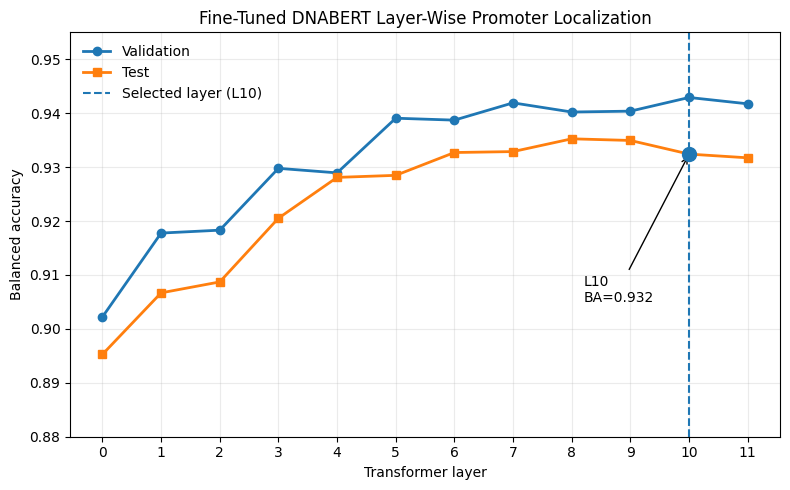

Creating Figure 2...


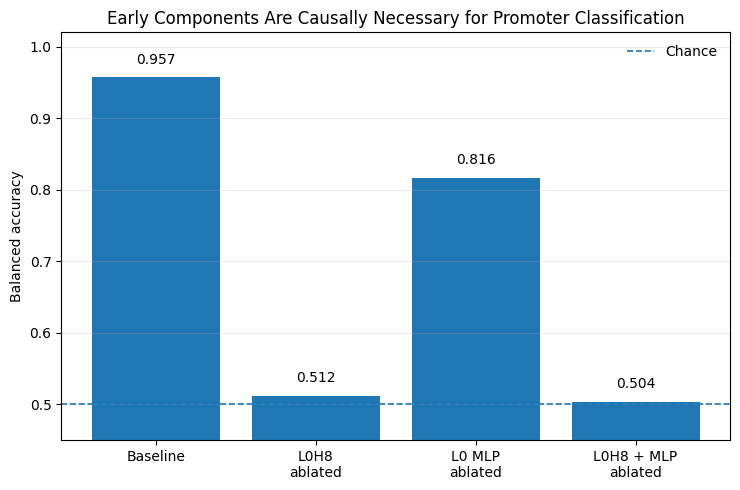

Creating Figure 3...


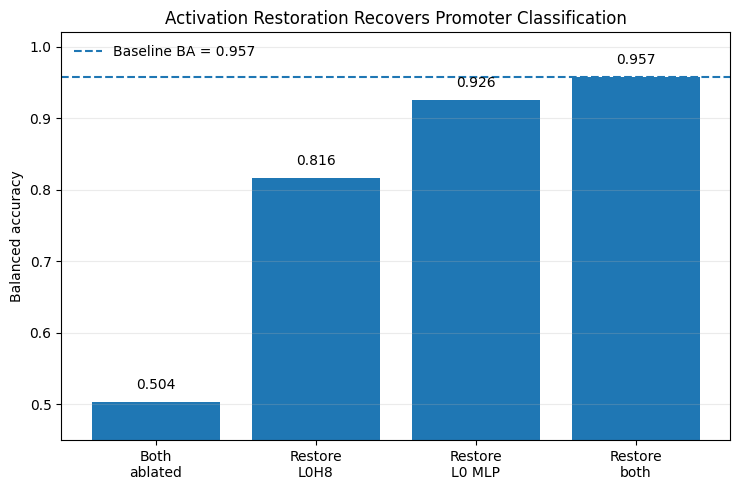

Creating Figure 4...


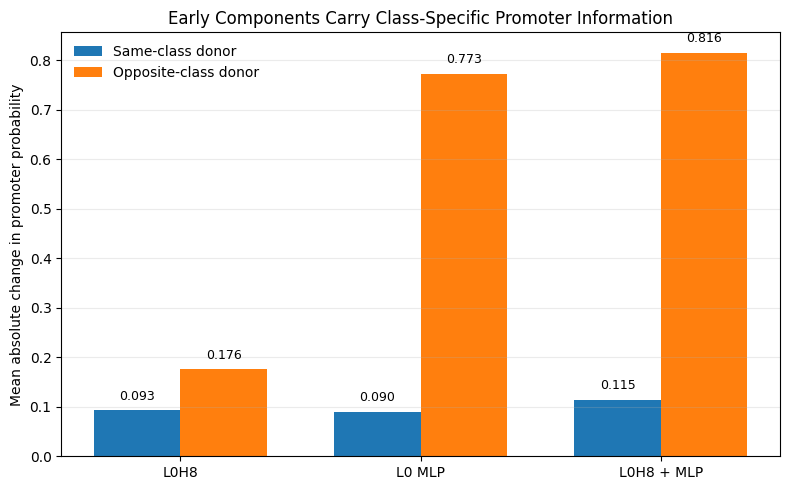

Creating Figure 5...


/tmp/ipykernel_667/3151380176.py:589: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


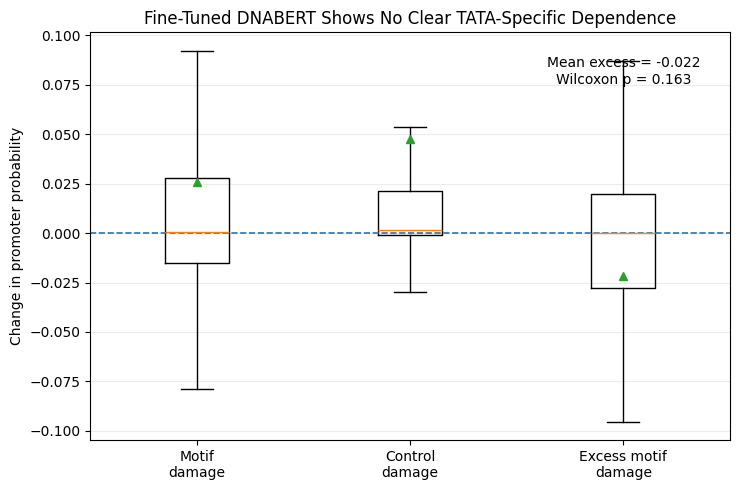


FIGURES SAVED
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/final_finetuned_summary/figures/figure1_layer_localization.png
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/final_finetuned_summary/figures/figure1_layer_localization.pdf
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/final_finetuned_summary/figures/figure2_targeted_ablation.png
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/final_finetuned_summary/figures/figure2_targeted_ablation.pdf
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/final_finetuned_summary/figures/figure3_activation_restoration.png
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/final_finetuned_summary/figures/figure3_activation_restoration.pdf
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/final_finetuned_summary/figures/figure4_donor_compatibility.png
/content/drive/MyDrive/dnabert_hf_finetuned_eval/results/final_finetuned_summary/figures/figure4_donor_compatibility.pdf
/content/drive/My

In [87]:
# Final figures — generate all 5 fine-tuned DNABERT figures
# Uses existing saved experimental results only.
# NO model inference.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 80)
print("GENERATE ALL FINAL FINE-TUNED DNABERT FIGURES")
print("=" * 80)

ROOT = Path(
    "/content/drive/MyDrive/dnabert_hf_finetuned_eval/results"
)

FIG_DIR = (
    ROOT
    / "final_finetuned_summary"
    / "figures"
)

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

saved_files = []


# =====================================================================
# Shared helper
# =====================================================================

def save_figure(fig, stem):

    png_path = (
        FIG_DIR
        / f"{stem}.png"
    )

    pdf_path = (
        FIG_DIR
        / f"{stem}.pdf"
    )

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
    )

    saved_files.extend(
        [
            png_path,
            pdf_path,
        ]
    )


# =====================================================================
# FIGURE 1
# Layer-wise localization
# =====================================================================

print("\nCreating Figure 1...")

layer_df = pd.read_csv(
    ROOT
    / "hf_finetuned_layer_localization"
    / "probes"
    / "layer_probe_metrics.csv"
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    layer_df["layer"],
    layer_df["dev_balanced_accuracy"],
    marker="o",
    linewidth=2,
    label="Validation",
)

ax.plot(
    layer_df["layer"],
    layer_df["test_balanced_accuracy"],
    marker="s",
    linewidth=2,
    label="Test",
)

# Fine-tuned selected endpoint
ax.axvline(
    10,
    linestyle="--",
    linewidth=1.5,
    label="Selected layer (L10)",
)

best_test_ba = float(
    layer_df.loc[
        layer_df["layer"] == 10,
        "test_balanced_accuracy",
    ].iloc[0]
)

ax.scatter(
    [10],
    [best_test_ba],
    s=100,
    zorder=5,
)

ax.annotate(
    f"L10\nBA={best_test_ba:.3f}",
    xy=(10, best_test_ba),
    xytext=(8.2, 0.905),
    arrowprops=dict(
        arrowstyle="->",
    ),
)

ax.set_xlabel(
    "Transformer layer"
)

ax.set_ylabel(
    "Balanced accuracy"
)

ax.set_title(
    "Fine-Tuned DNABERT Layer-Wise Promoter Localization"
)

ax.set_xticks(
    range(12)
)

ax.set_ylim(
    0.88,
    0.955,
)

ax.grid(
    alpha=0.25,
)

ax.legend(
    frameon=False,
)

fig.tight_layout()

save_figure(
    fig,
    "figure1_layer_localization",
)

plt.show()


# =====================================================================
# FIGURE 2
# Targeted causal ablation
# =====================================================================

print("Creating Figure 2...")

ablation_df = pd.read_csv(
    ROOT
    / "hf_finetuned_causal"
    / "targeted_ablation"
    / "metrics.csv"
)

condition_order = [
    "baseline",
    "L0H8",
    "L0_MLP",
    "L0H8_L0_MLP",
]

condition_labels = [
    "Baseline",
    "L0H8\nablated",
    "L0 MLP\nablated",
    "L0H8 + MLP\nablated",
]

plot_df = (
    ablation_df
    .set_index("condition")
    .loc[condition_order]
)

values = (
    plot_df[
        "balanced_accuracy"
    ].to_numpy()
)

fig, ax = plt.subplots(
    figsize=(7.5, 5)
)

bars = ax.bar(
    condition_labels,
    values,
)

ax.axhline(
    0.5,
    linestyle="--",
    linewidth=1.2,
    label="Chance",
)

for bar, value in zip(
    bars,
    values,
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

ax.set_ylabel(
    "Balanced accuracy"
)

ax.set_title(
    "Early Components Are Causally Necessary for Promoter Classification"
)

ax.set_ylim(
    0.45,
    1.02,
)

ax.legend(
    frameon=False,
)

ax.grid(
    axis="y",
    alpha=0.25,
)

fig.tight_layout()

save_figure(
    fig,
    "figure2_targeted_ablation",
)

plt.show()


# =====================================================================
# FIGURE 3
# Activation restoration
# =====================================================================

print("Creating Figure 3...")

restoration_df = pd.read_csv(
    ROOT
    / "hf_finetuned_causal"
    / "activation_restoration"
    / "metrics.csv"
)

restoration_order = [
    "ablated",
    "restore_L0H8",
    "restore_L0_MLP",
    "restore_both",
]

restoration_labels = [
    "Both\nablated",
    "Restore\nL0H8",
    "Restore\nL0 MLP",
    "Restore\nboth",
]

restoration_plot = (
    restoration_df
    .set_index("condition")
    .loc[restoration_order]
)

restoration_values = (
    restoration_plot[
        "balanced_accuracy"
    ].to_numpy()
)

baseline_ba = float(
    restoration_df.loc[
        restoration_df[
            "condition"
        ] == "baseline",
        "balanced_accuracy",
    ].iloc[0]
)

fig, ax = plt.subplots(
    figsize=(7.5, 5)
)

bars = ax.bar(
    restoration_labels,
    restoration_values,
)

ax.axhline(
    baseline_ba,
    linestyle="--",
    linewidth=1.5,
    label=f"Baseline BA = {baseline_ba:.3f}",
)

for bar, value in zip(
    bars,
    restoration_values,
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.014,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

ax.set_ylabel(
    "Balanced accuracy"
)

ax.set_title(
    "Activation Restoration Recovers Promoter Classification"
)

ax.set_ylim(
    0.45,
    1.02,
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.legend(
    frameon=False,
)

fig.tight_layout()

save_figure(
    fig,
    "figure3_activation_restoration",
)

plt.show()


# =====================================================================
# FIGURE 4
# Donor compatibility
# =====================================================================

print("Creating Figure 4...")

donor_df = pd.read_csv(
    ROOT
    / "hf_finetuned_causal"
    / "component_donor_matrix"
    / "donor_matrix_same_vs_opposite.csv"
)

components = [
    "L0H8",
    "L0_MLP",
    "both",
]

component_labels = [
    "L0H8",
    "L0 MLP",
    "L0H8 + MLP",
]

same_values = []

opposite_values = []

for component in components:

    same_values.append(
        float(
            donor_df.loc[
                (
                    donor_df[
                        "pair_type"
                    ] == "same_class"
                )
                &
                (
                    donor_df[
                        "component"
                    ] == component
                ),
                "mean_abs_delta_prob",
            ].iloc[0]
        )
    )

    opposite_values.append(
        float(
            donor_df.loc[
                (
                    donor_df[
                        "pair_type"
                    ] == "opposite_class"
                )
                &
                (
                    donor_df[
                        "component"
                    ] == component
                ),
                "mean_abs_delta_prob",
            ].iloc[0]
        )
    )

same_values = np.array(
    same_values
)

opposite_values = np.array(
    opposite_values
)

x = np.arange(
    len(components)
)

width = 0.36

fig, ax = plt.subplots(
    figsize=(8, 5)
)

bars_same = ax.bar(
    x - width / 2,
    same_values,
    width,
    label="Same-class donor",
)

bars_opposite = ax.bar(
    x + width / 2,
    opposite_values,
    width,
    label="Opposite-class donor",
)

for bars in [
    bars_same,
    bars_opposite,
]:

    for bar in bars:

        value = bar.get_height()

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,
            value + 0.015,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

ax.set_xticks(
    x
)

ax.set_xticklabels(
    component_labels
)

ax.set_ylabel(
    "Mean absolute change in promoter probability"
)

ax.set_title(
    "Early Components Carry Class-Specific Promoter Information"
)

ax.legend(
    frameon=False,
)

ax.grid(
    axis="y",
    alpha=0.25,
)

fig.tight_layout()

save_figure(
    fig,
    "figure4_donor_compatibility",
)

plt.show()


# =====================================================================
# FIGURE 5
# TATA perturbation
# =====================================================================

print("Creating Figure 5...")

tata_df = pd.read_csv(
    ROOT
    / "hf_finetuned_tata"
    / "tata_perturbation_results.csv"
)

motif_damage = (
    tata_df[
        "motif_damage"
    ].to_numpy()
)

control_damage = (
    tata_df[
        "control_damage"
    ].to_numpy()
)

excess_damage = (
    tata_df[
        "excess_motif_damage"
    ].to_numpy()
)

plot_data = [
    motif_damage,
    control_damage,
    excess_damage,
]

labels = [
    "Motif\ndamage",
    "Control\ndamage",
    "Excess motif\ndamage",
]

fig, ax = plt.subplots(
    figsize=(7.5, 5)
)

box = ax.boxplot(
    plot_data,
    labels=labels,
    showfliers=False,
    showmeans=True,
)

ax.axhline(
    0.0,
    linestyle="--",
    linewidth=1.2,
)

ax.set_ylabel(
    "Change in promoter probability"
)

ax.set_title(
    "Fine-Tuned DNABERT Shows No Clear TATA-Specific Dependence"
)

# Add overall mean excess effect.
mean_excess = float(
    excess_damage.mean()
)

ax.text(
    3,
    ax.get_ylim()[1] * 0.88,
    f"Mean excess = {mean_excess:+.3f}\n"
    "Wilcoxon p = 0.163",
    ha="center",
    va="top",
)

ax.grid(
    axis="y",
    alpha=0.25,
)

fig.tight_layout()

save_figure(
    fig,
    "figure5_tata_perturbation",
)

plt.show()


# =====================================================================
# FINAL CHECK
# =====================================================================

print("\n" + "=" * 80)
print("FIGURES SAVED")
print("=" * 80)

for path in saved_files:
    print(path)

assert len(saved_files) == 10

for path in saved_files:
    assert path.exists()
    assert path.stat().st_size > 0

print(
    "\nPASS: all 5 figures generated "
    "and saved as PNG + PDF."
)